# Anatomy-Normative Deviation Gating for Glaucoma Detection and Severity Grading
### Proposed model (Colab notebook) — compared against the DenseNet121 baseline

**Pipeline (matches your figures)**

| Stage | Model | Output |
|---|---|---|
| 1 | Pre-processing → MaxViT-Tiny → CBAM → GC Block → shared embedding (512) → FC 512→128 → FC 128→2 | Glaucoma / Non-glaucoma |
| 2 (Verification module, **v3**) | **Spatial Deviation Gating Block** on the frozen 512×7×7 Stage-1 map (S, E, S−E, S⊙E → conv-MLP → σ → D; S′ = S⊙D) → CDR / disc-size / deviation-evidence heads → **two-sided evidence-fusion verifier** | Continuous CDR ∈ [0,1] + "verified glaucoma / verified non-glaucoma / review" decision |

**Fairness rules built in**
* Uses the **same 70/15/15 stratified split (seed 42)** as the baseline → same 450 test images.
* **50 epochs, no early stopping.** The best epoch is picked from *validation* only (checkpoint selection, not stopping); the test set is never touched for any decision.
* Everything is written to a **brand-new timestamped folder** (`results/proposed_devgate_<time>`); existing result/checkpoint folders are never overwritten.
* All numbers in the final tables are computed by code from real predictions — nothing is hard-coded except the baseline fallback figures (used only if the baseline checkpoint can't be found).

**Run order:** just *Runtime → Run all*. Expect ~45–70 min on a T4 (first run also builds an image cache, ~5 min).
If Colab disconnects, set `RUN_NAME_OVERRIDE` in cell 1 to the folder that was created and re-run — Stage 1 resumes from its last epoch.

**Stage-2 v3 (this file):** the old one-sided AND-rule Stage 2 is kept only as the *comparator*. Section 5c replaces it with a cross-fitted spatial deviation gate and a two-sided verifier; Sections 6–7 are re-written for it. Run order for Stage 2: CELL 14 → 15 → 15a → 15b → 15c (audit, optional) → 15d (spatial bank) → S2-1 → S2-2 → S2-3 → S2-4 → CELL 16 → CELL 17.

In [1]:
# ============================================================
# CELL 1 — Environment, imports, configuration
# ============================================================
import os, sys, json, time, copy, math, random, subprocess, warnings, datetime
warnings.filterwarnings('ignore')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'timm'], check=False)

from google.colab import drive
drive.mount('/content/drive')

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as tvm
import timm
try:
    from timm.layers import LayerNorm2d
except Exception:
    from timm.models.layers import LayerNorm2d

from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score,
    average_precision_score, f1_score, confusion_matrix, matthews_corrcoef, cohen_kappa_score,
    brier_score_loss, log_loss, roc_curve, precision_recall_curve, r2_score)

# ---------------- Paths (new run folder — never an existing one) ----------------
PROJECT_DIR   = '/content/drive/MyDrive/glaucoma-mtl'
FINAL_CSV     = f'{PROJECT_DIR}/metadata_final.csv'                       # produced by your CDR-derivation cell
BASELINE_CKPT = f'{PROJECT_DIR}/checkpoints/baseline_densenet121_best.pth' # read-only use
RUN_NAME_OVERRIDE = None     # e.g. 'proposed_devgate_20261001_1030' to RESUME an interrupted run

PROTECTED = {'baseline_densenet121', 'proposed_maxvit', 'ablation_maxvit_cbam_only'}
RUN_NAME    = RUN_NAME_OVERRIDE or ('proposed_devgate_' + datetime.datetime.now().strftime('%Y%m%d_%H%M'))
RESULTS_DIR = f'{PROJECT_DIR}/results/{RUN_NAME}'
assert RUN_NAME not in PROTECTED, 'Refusing to write into an existing results folder.'
if RUN_NAME_OVERRIDE is None:
    assert not os.path.exists(RESULTS_DIR), f'{RESULTS_DIR} already exists — pick a new name.'
FIG_DIR, TAB_DIR, CKPT_DIR, PRED_DIR = [f'{RESULTS_DIR}/{d}' for d in ('figures', 'tables', 'checkpoints', 'predictions')]
for d in (FIG_DIR, TAB_DIR, CKPT_DIR, PRED_DIR):
    os.makedirs(d, exist_ok=True)
CACHE_DIR = '/content/cache'; os.makedirs(CACHE_DIR, exist_ok=True)

# ---------------- Hyper-parameters ----------------
CFG = dict(
    seed=42, img_size=224, cache_size=256, batch_size=32, num_workers=2,
    # Stage 1 (classifier) — 50 epochs, NO early stopping
    s1_epochs=50, s1_backbone_lr=5e-5, s1_head_lr=5e-4, s1_weight_decay=0.05,
    s1_warmup_epochs=3, s1_label_smoothing=0.1, s1_drop_path=0.2, s1_dropout=0.3,
    s1_ema_decay=0.995, s1_grad_clip=1.0, tta=True,
    # Stage 2 (verification module) — 50 epochs, NO early stopping
    s2_epochs=50, s2_lr=1e-3, s2_weight_decay=1e-2, s2_batch=64, s2_bucket_loss_w=0.2,
    s2_aug_views=8, s2_ema_momentum=0.99, s2_seeds=[0, 1, 2, 3, 4],
    n_buckets=3, sev_thresholds=(0.65, 0.85), bootstrap=2000,
)
SEED = CFG['seed']
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
print('Device:', DEVICE, '|', torch.cuda.get_device_name(0) if USE_AMP else 'NO GPU — switch runtime to T4 GPU')
print('Results folder:', RESULTS_DIR)
json.dump(CFG, open(f'{RESULTS_DIR}/config.json', 'w'), indent=2)

Mounted at /content/drive
Device: cuda | Tesla T4
Results folder: /content/drive/MyDrive/glaucoma-mtl/results/proposed_devgate_20261010_1731


## 1 · Data — identical split to the baseline, pre-processing cache, disc-size buckets
Pre-processing (as in the figure): crop black borders → pad to square → resize 256 → CLAHE on the lightness channel.
Disc-size bucket (S/M/L tercile) is computed from the optic-disc mask as *equivalent disc diameter ÷ fundus diameter* (scale-free across cameras); tercile cut-offs come from **training images only**.

In [2]:
# ============================================================
# CELL 2 — Load metadata and reproduce the baseline split exactly
# ============================================================
if not os.path.exists(FINAL_CSV):
    raise FileNotFoundError(f'{FINAL_CSV} not found. Run the CDR-derivation cell from the baseline notebook first.')
df = pd.read_csv(FINAL_CSV)
for c in ['fundus_path', 'od_path', 'label', 'vcdr_final', 'names']:
    assert c in df.columns, f'missing column {c}'
df['row_id']      = np.arange(len(df))
df['vcdr_final']  = pd.to_numeric(df['vcdr_final'], errors='coerce')
df['has_cdr']     = df['vcdr_final'].notna().astype(int)

# SAME calls as the baseline notebook -> same train/val/test membership
tr_tmp, temp_tmp = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=42)
va_tmp, te_tmp   = train_test_split(temp_tmp, test_size=0.50, stratify=temp_tmp['label'], random_state=42)
TRAIN_IDX, VAL_IDX, TEST_IDX = tr_tmp.index.values, va_tmp.index.values, te_tmp.index.values
print(f'Split sizes -> train {len(TRAIN_IDX)} | val {len(VAL_IDX)} | test {len(TEST_IDX)}')
assert (len(TRAIN_IDX), len(VAL_IDX), len(TEST_IDX)) == (2100, 450, 450), 'Split differs from baseline (expected 2100/450/450)'
print('Test glaucoma ratio:', te_tmp['label'].mean().round(3))

Split sizes -> train 2100 | val 450 | test 450
Test glaucoma ratio: 0.5


In [3]:
# ============================================================
# CELL 2-G (OPTIONAL, insert right after CELL 2) — patient-level (grouped) 70/15/15 split
#   Only use this if CELL 15a (or SMDG metadata) shows that eyes/images of one patient sit in different splits.
#   CONSEQUENCES: Stage 1 AND the DenseNet121 baseline must be retrained/re-scored on the new split (their checkpoints have seen the new val/test images).
#   Everything from CELL 3 onward must be re-run with a NEW run folder. Default is OFF so the published split is untouched.
# ============================================================
USE_GROUP_SPLIT = False
GROUP_COL = None            # e.g. 'patient_id' if your metadata has one; otherwise a name-derived id is used (VERIFY it on your file names!)
if USE_GROUP_SPLIT:
    import re
    from sklearn.model_selection import StratifiedGroupKFold
    def eye_group(name):
        s = re.sub(r'\.[A-Za-z]{3,4}$', '', str(name).split('/')[-1])
        return re.sub(r'(?i)(?<![a-z])(od|os|oi|re|le|left|right|l|r)(?![a-z])', '', s).strip('_-. ')
    groups = df[GROUP_COL].astype(str).values if GROUP_COL else df['names'].map(eye_group).values
    fold = np.full(len(df), -1)
    for k, (_, te_i) in enumerate(StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=42).split(df, df['label'], groups)): fold[te_i] = k
    TEST_IDX, VAL_IDX, TRAIN_IDX = df.index.values[fold < 3], df.index.values[(fold >= 3) & (fold < 6)], df.index.values[fold >= 6]     # 3/20 + 3/20 + 14/20 folds
    g = lambda ix: set(groups[df.index.get_indexer(ix)])
    assert not (g(TRAIN_IDX) & g(VAL_IDX)) and not (g(TRAIN_IDX) & g(TEST_IDX)) and not (g(VAL_IDX) & g(TEST_IDX)), 'group leakage remains'
    tr_tmp, va_tmp, te_tmp = df.loc[TRAIN_IDX], df.loc[VAL_IDX], df.loc[TEST_IDX]
    print(f'GROUPED split -> train {len(TRAIN_IDX)} | val {len(VAL_IDX)} | test {len(TEST_IDX)} | test glaucoma ratio {te_tmp.label.mean():.3f} | groups: {len(set(groups))}')
    print('Sizes are approximate (whole groups are kept together); the 2100/450/450 assertion of CELL 2 no longer applies. RE-RUN Stage 1 and the baseline on this split.')
else:
    print('Group split OFF — using the published image-level split.')


Group split OFF — using the published image-level split.


Loaded cached images: (3000, 256, 256, 3)
Disc-size cut-offs (train terciles): 0.1421 / 0.1576


,split,n,glaucoma,normal,with_CDR,bucket_known,small,medium,large
0,train,2100,1050,1050,437,477,159,159,159
1,val,450,225,225,90,98,33,30,35
2,test,450,225,225,104,113,36,45,32


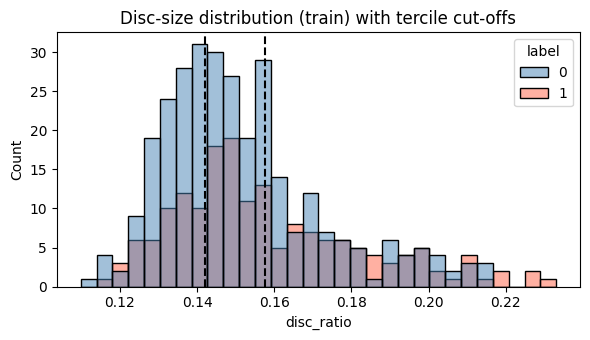

In [5]:
# ============================================================
# CELL 3 — Pre-processing cache (parallel) + disc-size geometry
# ============================================================
CS = CFG['cache_size']
X_PATH, META_PATH = f'{CACHE_DIR}/fundus_{CS}_clahe.npy', f'{CACHE_DIR}/fundus_{CS}_meta.csv'

def process_row(args):
    i, fpath, opath = args
    try:
        img = cv2.cvtColor(cv2.imread(fpath, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]
        m = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) > 12
        rows, cols = np.where(m.any(1))[0], np.where(m.any(0))[0]
        if len(rows) and len(cols) and m.mean() > 0.05:
            y0, y1, x0, x1 = rows[0], rows[-1] + 1, cols[0], cols[-1] + 1
        else:
            y0, y1, x0, x1 = 0, H, 0, W
        crop = img[y0:y1, x0:x1]
        h, w = crop.shape[:2]; s = max(h, w); diam = float(s)
        canvas = np.zeros((s, s, 3), np.uint8); canvas[(s-h)//2:(s-h)//2+h, (s-w)//2:(s-w)//2+w] = crop
        canvas = cv2.resize(canvas, (CS, CS), interpolation=cv2.INTER_AREA)
        lab = cv2.cvtColor(canvas, cv2.COLOR_RGB2LAB)
        lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
        canvas = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
        ratio = np.nan
        if isinstance(opath, str) and os.path.isfile(opath):
            mk = cv2.imread(opath, cv2.IMREAD_GRAYSCALE)
            if mk is not None:
                frac = float((mk > 128).mean())
                if frac > 0:
                    ratio = 2.0 * math.sqrt(frac * H * W / math.pi) / diam   # disc diameter / fundus diameter
        return i, canvas, ratio, True
    except Exception:
        return i, np.zeros((CS, CS, 3), np.uint8), np.nan, False

if os.path.exists(X_PATH) and os.path.exists(META_PATH) and len(pd.read_csv(META_PATH)) == len(df):
    X = np.load(X_PATH); df['disc_ratio'] = pd.read_csv(META_PATH)['disc_ratio'].values
    print('Loaded cached images:', X.shape)
else:
    X = np.zeros((len(df), CS, CS, 3), np.uint8); ratios = np.full(len(df), np.nan); bad = 0
    jobs = list(zip(df['row_id'], df['fundus_path'], df['od_path']))
    with ThreadPoolExecutor(8) as ex:
        for i, canvas, ratio, ok in tqdm(ex.map(process_row, jobs), total=len(jobs), desc='Pre-processing'):
            X[i] = canvas; ratios[i] = ratio; bad += (not ok)
    print(f'Failed images (blank-filled): {bad}')
    df['disc_ratio'] = ratios
    np.save(X_PATH, X); pd.DataFrame({'disc_ratio': ratios}).to_csv(META_PATH, index=False)

# ---- Disc-size terciles from TRAIN only ----
tr_ratio = df.loc[TRAIN_IDX, 'disc_ratio'].dropna().values
Q1, Q2 = np.quantile(tr_ratio, [1/3, 2/3])
def to_bucket(r):
    if np.isnan(r): return -1
    return 0 if r <= Q1 else (1 if r <= Q2 else 2)
df['bucket'] = df['disc_ratio'].apply(to_bucket)
BUCKET_NAMES = ['Small', 'Medium', 'Large']
print(f'Disc-size cut-offs (train terciles): {Q1:.4f} / {Q2:.4f}')

def refresh_splits():
    return (df.loc[TRAIN_IDX].reset_index(drop=True), df.loc[VAL_IDX].reset_index(drop=True), df.loc[TEST_IDX].reset_index(drop=True))
train_df, val_df, test_df = refresh_splits()

summ = []
for nm, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    summ.append(dict(split=nm, n=len(d), glaucoma=int(d.label.sum()), normal=int((d.label == 0).sum()),
                     with_CDR=int(d.has_cdr.sum()), bucket_known=int((d.bucket >= 0).sum()),
                     small=int((d.bucket == 0).sum()), medium=int((d.bucket == 1).sum()), large=int((d.bucket == 2).sum())))
split_summary = pd.DataFrame(summ); display(split_summary)
split_summary.to_csv(f'{TAB_DIR}/data_split_summary.csv', index=False)

fig, ax = plt.subplots(figsize=(6, 3.5))
sns.histplot(data=df.loc[TRAIN_IDX].dropna(subset=['disc_ratio']), x='disc_ratio', hue='label', bins=30, ax=ax, palette=['steelblue', 'tomato'])
ax.axvline(Q1, ls='--', c='k'); ax.axvline(Q2, ls='--', c='k'); ax.set_title('Disc-size distribution (train) with tercile cut-offs')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/disc_size_distribution.png', dpi=300); plt.show()

Batch: torch.Size([32, 3, 224, 224]) | labels [0, 1, 1, 1, 0, 0, 1, 1] | buckets [-1, -1, -1, -1, -1, -1, -1, -1]


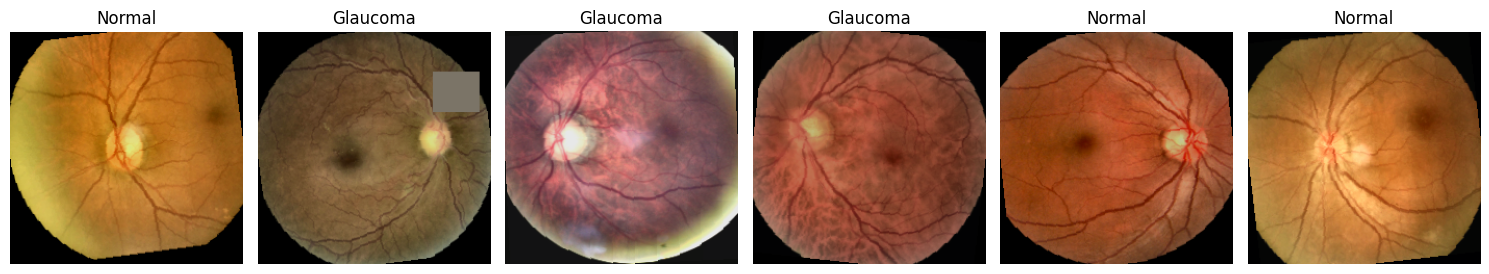

In [6]:
# ============================================================
# CELL 4 — Datasets, augmentation, loaders
# ============================================================
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
IMG = CFG['img_size']
train_tf = T.Compose([
    T.RandomResizedCrop(IMG, scale=(0.75, 1.0), ratio=(0.9, 1.1)),
    T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(25),
    T.ColorJitter(0.25, 0.25, 0.15, 0.03),
    T.RandomApply([T.GaussianBlur(5, (0.1, 1.5))], p=0.2),
    T.ToTensor(), T.Normalize(MEAN, STD),
    T.RandomErasing(p=0.25, scale=(0.02, 0.08)),
])
eval_tf = T.Compose([T.Resize((IMG, IMG)), T.ToTensor(), T.Normalize(MEAN, STD)])

class FundusDS(Dataset):
    # returns: image, label, cdr, has_cdr, disc_bucket(-1 = unknown), row_id
    def __init__(self, d, tf, X):
        self.rows = d['row_id'].values; self.y = d['label'].values.astype(np.int64)
        self.cdr = d['vcdr_final'].fillna(0).values.astype(np.float32)
        self.has = d['has_cdr'].values.astype(np.float32)
        self.bucket = d['bucket'].values.astype(np.int64); self.tf = tf; self.X = X
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        img = Image.fromarray(self.X[self.rows[i]])
        return self.tf(img), self.y[i], self.cdr[i], self.has[i], self.bucket[i], self.rows[i]

def make_loader(d, tf, shuffle, drop_last=False):
    return DataLoader(FundusDS(d, tf, X), batch_size=CFG['batch_size'], shuffle=shuffle, drop_last=drop_last,
                      num_workers=CFG['num_workers'], pin_memory=USE_AMP, persistent_workers=CFG['num_workers'] > 0)

train_loader      = make_loader(train_df, train_tf, True, drop_last=True)
train_eval_loader = make_loader(train_df, eval_tf, False)     # clean (un-augmented) train pass for honest train metrics
val_loader        = make_loader(val_df, eval_tf, False)
test_loader       = make_loader(test_df, eval_tf, False)

b = next(iter(train_loader))
print('Batch:', b[0].shape, '| labels', b[1][:8].tolist(), '| buckets', b[4][:8].tolist())
fig, axs = plt.subplots(1, 6, figsize=(15, 2.8))
for k, a in enumerate(axs):
    im = (b[0][k].permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)).clip(0, 1)
    a.imshow(im); a.set_title(['Normal', 'Glaucoma'][int(b[1][k])]); a.axis('off')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/augmentation_samples.png', dpi=200); plt.show()

## 2 · Metrics toolbox (everything the paper needs)

In [7]:
# ============================================================
# CELL 5 — Metrics, bootstrap CIs, paired tests, plotting helpers
# ============================================================
def ece_score(y, p, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1); e = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (p >= lo) & (p <= hi) if lo == 0 else (p > lo) & (p <= hi)
        if m.sum(): e += m.mean() * abs(p[m].mean() - y[m].mean())
    return e

def clf_metrics(y, p, thr=0.5, pred=None):
    # Full binary-classification metric set. If `pred` is given (pipeline decision) the score-based metrics are NaN.
    y = np.asarray(y).astype(int); score_free = pred is not None
    pred = (np.asarray(p) >= thr).astype(int) if pred is None else np.asarray(pred).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens, spec = tp / max(tp + fn, 1), tn / max(tn + fp, 1)
    ppv, npv = tp / max(tp + fp, 1), tn / max(tn + fn, 1)
    m = dict(accuracy=(tp + tn) / len(y), balanced_accuracy=(sens + spec) / 2, sensitivity=sens, specificity=spec,
             precision_glaucoma=ppv, recall_glaucoma=sens, precision_normal=npv, recall_normal=spec,
             f1_glaucoma=f1_score(y, pred, zero_division=0), f1_normal=f1_score(y, pred, pos_label=0, zero_division=0),
             f1_macro=f1_score(y, pred, average='macro', zero_division=0), f1_weighted=f1_score(y, pred, average='weighted', zero_division=0),
             mcc=matthews_corrcoef(y, pred), kappa=cohen_kappa_score(y, pred), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))
    if score_free:
        m.update(auc=np.nan, auprc=np.nan, brier=np.nan, ece=np.nan, test_loss=np.nan)
    else:
        p = np.asarray(p, dtype=float)
        m.update(auc=roc_auc_score(y, p), auprc=average_precision_score(y, p), brier=brier_score_loss(y, p),
                 ece=ece_score(y, p), test_loss=log_loss(y, np.clip(p, 1e-7, 1 - 1e-7)))
    return m

def core(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(accuracy=(tp + tn) / len(y), sensitivity=tp / max(tp + fn, 1), specificity=tn / max(tn + fp, 1),
                f1_macro=f1_score(y, pred, average='macro', zero_division=0), auc=roc_auc_score(y, p))

def bootstrap_ci(y, p, thr=0.5, n_boot=None, seed=0):
    n_boot = n_boot or CFG['bootstrap']; rng = np.random.default_rng(seed); n = len(y); acc = {}
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y[idx])) < 2: continue
        for k, v in core(y[idx], p[idx], thr).items(): acc.setdefault(k, []).append(v)
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in acc.items()}

def paired_tests(y, p_a, p_b, thr_a=0.5, thr_b=0.5, n_boot=None, seed=0):
    # a = proposed, b = baseline. McNemar exact test + paired bootstrap of (accuracy, AUC) differences.
    n_boot = n_boot or CFG['bootstrap']; y = np.asarray(y)
    ca, cb = ((p_a >= thr_a).astype(int) == y), ((p_b >= thr_b).astype(int) == y)
    b01, b10 = int((~ca & cb).sum()), int((ca & ~cb).sum())      # baseline-only-correct, proposed-only-correct
    mc_p = stats.binomtest(min(b01, b10), b01 + b10, 0.5).pvalue if (b01 + b10) > 0 else 1.0
    rng = np.random.default_rng(seed); n = len(y); d_acc, d_auc = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y[idx])) < 2: continue
        d_acc.append(ca[idx].mean() - cb[idx].mean())
        d_auc.append(roc_auc_score(y[idx], p_a[idx]) - roc_auc_score(y[idx], p_b[idx]))
    def summ(d):
        d = np.array(d); return dict(mean=d.mean(), lo=np.percentile(d, 2.5), hi=np.percentile(d, 97.5),
                                      p=min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean())))
    return dict(mcnemar_p=mc_p, proposed_only_correct=b10, baseline_only_correct=b01, acc_diff=summ(d_acc), auc_diff=summ(d_auc))

PCT_KEYS = ['accuracy', 'balanced_accuracy', 'sensitivity', 'specificity', 'precision_glaucoma', 'recall_glaucoma',
            'precision_normal', 'recall_normal', 'f1_glaucoma', 'f1_normal']
def metrics_table(rows):
    t = pd.DataFrame(rows).T
    for k in PCT_KEYS:
        if k in t: t[k] = t[k] * 100
    return t

def savefig(name):
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/{name}', dpi=300, bbox_inches='tight'); plt.show()

def plot_cm(ax, cm, title):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, xticklabels=['Normal', 'Glaucoma'],
                yticklabels=['Normal', 'Glaucoma'], annot_kws={'size': 14})
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title)
print('Metrics toolbox ready.')

Metrics toolbox ready.


## 3 · Stage 1 — MaxViT-Tiny + CBAM + GC Block classifier

In [8]:
# ============================================================
# CELL 6 — Stage 1 architecture
# ============================================================
class CBAM2d(nn.Module):
    # Channel attention (avg+max pooled shared MLP) followed by spatial attention (7x7 conv)
    def __init__(self, c, r=16, k=7):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(c, c // r, bias=False), nn.ReLU(inplace=True), nn.Linear(c // r, c, bias=False))
        self.sp = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
    def forward(self, x):
        ca = torch.sigmoid(self.mlp(x.mean((2, 3))) + self.mlp(x.amax((2, 3))))[:, :, None, None]
        x = x * ca
        s = torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)
        return x * torch.sigmoid(self.sp(s))

class GCBlock2d(nn.Module):
    # Global-context block (GCNet): softmax spatial pooling -> bottleneck transform -> ADDITIVE fusion
    def __init__(self, c, ratio=4):
        super().__init__(); inner = c // ratio
        self.ctx = nn.Conv2d(c, 1, 1)
        self.transform = nn.Sequential(nn.Conv2d(c, inner, 1), nn.GroupNorm(1, inner), nn.ReLU(inplace=True), nn.Conv2d(inner, c, 1))
    def forward(self, x):
        B, C, H, W = x.shape
        attn = torch.softmax(self.ctx(x).flatten(2), dim=-1)                      # B,1,HW
        ctx = torch.bmm(x.flatten(2), attn.transpose(1, 2)).unsqueeze(-1)         # B,C,1,1
        return x + self.transform(ctx)

class Stage1Net(nn.Module):
    def __init__(self, pretrained=True, drop_path=0.2, emb_dim=512, drop=0.3):
        super().__init__()
        self.backbone = timm.create_model('maxvit_tiny_tf_224.in1k', pretrained=pretrained, num_classes=0, drop_path_rate=drop_path)
        C = self.backbone.num_features
        self.norm = LayerNorm2d(C); self.cbam = CBAM2d(C); self.gc = GCBlock2d(C)
        self.embed_fc = nn.Sequential(nn.Linear(C, emb_dim), nn.ReLU(inplace=True), nn.Dropout(drop))   # shared embedding (512)
        self.fc1 = nn.Sequential(nn.Linear(emb_dim, 128), nn.ReLU(inplace=True), nn.Dropout(drop))       # FCL 512->128
        self.fc2 = nn.Linear(128, 2)                                                                    # FCL 128->2
    def embed(self, x):
        f = self.backbone.forward_features(x)
        assert f.ndim == 4, f'unexpected backbone output {tuple(f.shape)}'
        f = self.gc(self.cbam(self.norm(f)))
        return self.embed_fc(f.mean((2, 3)))
    def forward(self, x):
        return self.fc2(self.fc1(self.embed(x)))

def count_params(m):
    return sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)

model1 = Stage1Net(True, CFG['s1_drop_path'], 512, CFG['s1_dropout']).to(DEVICE)
with torch.no_grad():
    model1.eval(); o = model1(torch.zeros(2, 3, IMG, IMG, device=DEVICE))
tot, trn = count_params(model1)
print(f'Stage-1 output {tuple(o.shape)} | params total {tot:,} | trainable {trn:,}')

model.safetensors: reconstructing file:   0%|          |  0.00B /  124MB            

model.safetensors: downloading bytes:           |  0.00B            

Stage-1 output (2, 2) | params total 30,898,477 | trainable 30,898,477


In [9]:
# ============================================================
# CELL 7 — Stage 1 training utilities (AdamW + warm-up/cosine + EMA + AMP, NO early stopping)
# ============================================================
class EMA:
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval(); self.decay, self.n = decay, 0
        for p in self.module.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model):
        self.n += 1; d = min(self.decay, (1 + self.n) / (10 + self.n))
        for e, m in zip(self.module.state_dict().values(), model.state_dict().values()):
            if e.dtype.is_floating_point: e.mul_(d).add_(m.detach(), alpha=1 - d)
            else: e.copy_(m)

def build_optimizer(model):
    groups = []
    for is_bb in (True, False):
        for decay in (True, False):
            ps = [p for n, p in model.named_parameters()
                  if n.startswith('backbone.') == is_bb and ((p.ndim > 1) == decay)]
            if ps: groups.append({'params': ps, 'lr': CFG['s1_backbone_lr'] if is_bb else CFG['s1_head_lr'],
                                  'weight_decay': CFG['s1_weight_decay'] if decay else 0.0})
    return torch.optim.AdamW(groups)

@torch.no_grad()
def predict_probs(model, loader, tta=False):
    model.eval(); P, Y, R = [], [], []
    for batch in loader:
        imgs = batch[0].to(DEVICE, non_blocking=True)
        views = [imgs] + ([torch.flip(imgs, [3]), torch.flip(imgs, [2])] if tta else [])
        pr = 0
        for v in views:
            with torch.amp.autocast('cuda', enabled=USE_AMP, dtype=torch.float16):
                pr = pr + torch.softmax(model(v).float(), 1)[:, 1]
        P.append((pr / len(views)).cpu()); Y.append(batch[1]); R.append(batch[5])
    return torch.cat(P).numpy(), torch.cat(Y).numpy(), torch.cat(R).numpy()

def train_stage1(model, epochs):
    crit = nn.CrossEntropyLoss(label_smoothing=CFG['s1_label_smoothing'])
    opt = build_optimizer(model); ema = EMA(model, CFG['s1_ema_decay'])
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    spe = len(train_loader); total, warm = epochs * spe, CFG['s1_warmup_epochs'] * spe
    lam = lambda s: (s + 1) / warm if s < warm else 0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lam)
    hist, best_auc, best_loss, start = [], -1.0, 1e9, 1
    last_path, best_path = f'{CKPT_DIR}/stage1_last.pth', f'{CKPT_DIR}/stage1_best.pth'

    if os.path.exists(last_path):                                   # ---- resume after a Colab disconnect ----
        ck = torch.load(last_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck['model']); ema.module.load_state_dict(ck['ema']); opt.load_state_dict(ck['opt'])
        sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler']); ema.n = ck['ema_n']
        hist, best_auc, best_loss, start = ck['hist'], ck['best_auc'], ck['best_loss'], ck['epoch'] + 1
        print(f'Resumed from epoch {ck["epoch"]}')

    for ep in range(start, epochs + 1):
        t0 = time.time(); model.train(); tl = tc = tn = 0
        for batch in tqdm(train_loader, desc=f'Ep {ep:02d} train', leave=False):
            imgs, y = batch[0].to(DEVICE, non_blocking=True), batch[1].to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=USE_AMP, dtype=torch.float16):
                logits = model(imgs); loss = crit(logits.float(), y)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), CFG['s1_grad_clip'])
            scaler.step(opt); scaler.update(); sched.step(); ema.update(model)
            tl += loss.item() * len(y); tc += (logits.argmax(1) == y).sum().item(); tn += len(y)
        pv, yv, _ = predict_probs(ema.module, val_loader, tta=False)          # validate the EMA weights
        v = dict(epoch=ep, lr=opt.param_groups[0]['lr'], train_loss=tl / tn, train_acc=tc / tn,
                 val_loss=log_loss(yv, np.clip(pv, 1e-7, 1 - 1e-7)), val_acc=((pv >= .5) == yv).mean(), val_auc=roc_auc_score(yv, pv))
        hist.append(v)
        improved = (v['val_auc'] > best_auc + 1e-6) or (abs(v['val_auc'] - best_auc) <= 1e-6 and v['val_loss'] < best_loss)
        if improved:
            best_auc, best_loss = v['val_auc'], v['val_loss']
            torch.save({'model_state_dict': ema.module.state_dict(), 'epoch': ep, 'val_auc': best_auc, 'val_loss': best_loss}, best_path)
        torch.save({'model': model.state_dict(), 'ema': ema.module.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                    'scaler': scaler.state_dict(), 'ema_n': ema.n, 'hist': hist, 'best_auc': best_auc, 'best_loss': best_loss, 'epoch': ep}, last_path)
        print(f"Ep {ep:02d}/{epochs} | {time.time()-t0:4.0f}s | lr {v['lr']:.2e} | train loss {v['train_loss']:.4f} acc {v['train_acc']:.4f} | "
              f"val loss {v['val_loss']:.4f} acc {v['val_acc']:.4f} AUC {v['val_auc']:.4f}{'  <- best' if improved else ''}")
    return pd.DataFrame(hist)
print('Training utilities ready.')

Training utilities ready.


Ep 01 train:   0%|          | 0/65 [00:00<?, ?it/s]

Ep 01/50 |   55s | lr 1.69e-05 | train loss 0.6868 acc 0.5534 | val loss 0.6626 acc 0.6889 AUC 0.7767  <- best


Ep 02 train:   0%|          | 0/65 [00:00<?, ?it/s]

Ep 02/50 |   53s | lr 3.36e-05 | train loss 0.5949 acc 0.7173 | val loss 0.5061 acc 0.7489 AUC 0.8619  <- best


Ep 03 train:   0%|          | 0/65 [00:00<?, ?it/s]

...

Ep 48/50 |   59s | lr 7.21e-07 | train loss 0.2669 acc 0.9606 | val loss 0.3355 acc 0.8711 AUC 0.9378


Ep 49 train:   0%|          | 0/65 [00:00<?, ?it/s]

Ep 49/50 |   66s | lr 5.55e-07 | train loss 0.2633 acc 0.9639 | val loss 0.3371 acc 0.8711 AUC 0.9373


Ep 50 train:   0%|          | 0/65 [00:00<?, ?it/s]

Ep 50/50 |   65s | lr 5.00e-07 | train loss 0.2673 acc 0.9630 | val loss 0.3381 acc 0.8711 AUC 0.9371

Trained 50 epochs (no early stopping). Best validation epoch: 18 | best val AUC 0.9536


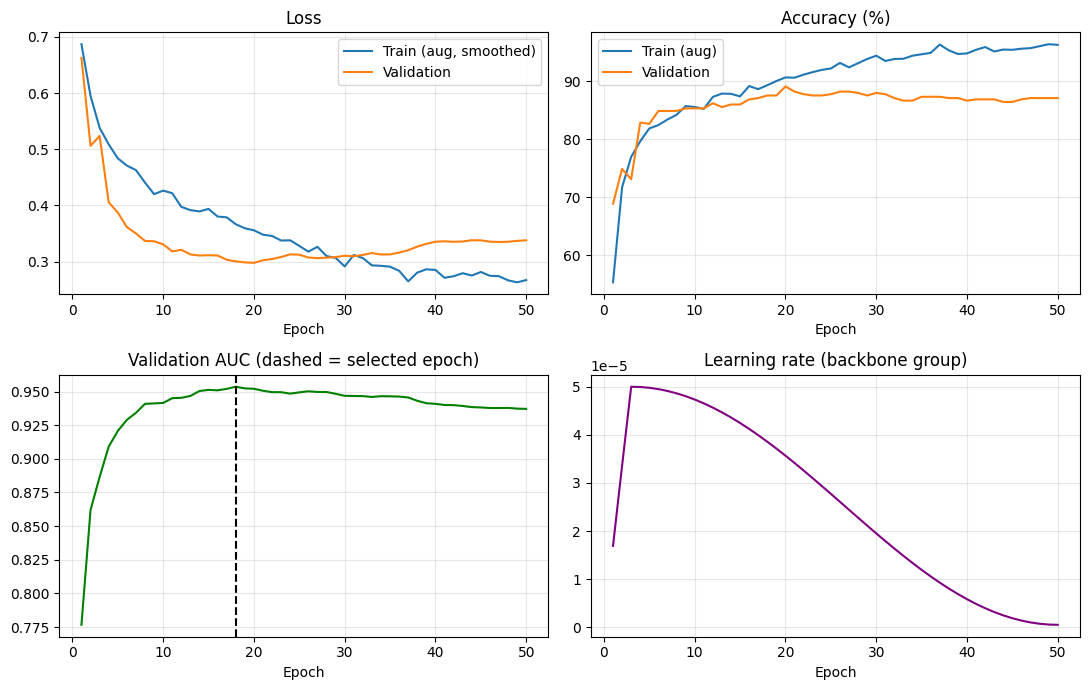

In [ ]:
# ============================================================
# CELL 8 — TRAIN STAGE 1 (50 epochs, no early stopping)
# ============================================================
# Fix DataLoader worker crash by disabling multi-processing on Colab
CFG['num_workers'] = 0
train_loader = make_loader(train_df, train_tf, True, drop_last=True)
train_eval_loader = make_loader(train_df, eval_tf, False)
val_loader = make_loader(val_df, eval_tf, False)
test_loader = make_loader(test_df, eval_tf, False)

hist1 = train_stage1(model1, CFG['s1_epochs'])
hist1.to_csv(f'{TAB_DIR}/stage1_training_history.csv', index=False)
best_ep = int(hist1.loc[hist1.val_auc.idxmax(), 'epoch'])
print(f'\nTrained {len(hist1)} epochs (no early stopping). Best validation epoch: {best_ep} | best val AUC {hist1.val_auc.max():.4f}')

fig, axs = plt.subplots(2, 2, figsize=(11, 7))
axs[0, 0].plot(hist1.epoch, hist1.train_loss, label='Train (aug, smoothed)'); axs[0, 0].plot(hist1.epoch, hist1.val_loss, label='Validation'); axs[0, 0].set_title('Loss'); axs[0, 0].legend()
axs[0, 1].plot(hist1.epoch, hist1.train_acc * 100, label='Train (aug)'); axs[0, 1].plot(hist1.epoch, hist1.val_acc * 100, label='Validation'); axs[0, 1].set_title('Accuracy (%)'); axs[0, 1].legend()
axs[1, 0].plot(hist1.epoch, hist1.val_auc, c='g'); axs[1, 0].axvline(best_ep, ls='--', c='k'); axs[1, 0].set_title('Validation AUC (dashed = selected epoch)')
axs[1, 1].plot(hist1.epoch, hist1.lr, c='purple'); axs[1, 1].set_title('Learning rate (backbone group)')
for a in axs.ravel(): a.set_xlabel('Epoch'); a.grid(alpha=.3)
savefig('stage1_training_curves.png')

## 4 · Stage 1 evaluation and head-to-head with the DenseNet121 baseline
The baseline is re-scored on the **same 450 test images** using *its own* original pre-processing, so paired statistical tests are possible.

In [10]:
# ============================================================
# CELL 9 — Stage 1 evaluation (best-val checkpoint), clean train/val/test numbers
# ============================================================
import glob

ck_path = f'{CKPT_DIR}/stage1_best.pth'
if not os.path.exists(ck_path):
    print(f"Target checkpoint not found at {ck_path}. Searching for previous runs...")
    candidates = sorted(glob.glob(f"{PROJECT_DIR}/results/proposed_devgate_*/checkpoints/stage1_best.pth"))
    if candidates:
        ck_path = candidates[-1]
        print(f"Found Stage-1 checkpoint to recover from: {ck_path}")
    else:
        raise FileNotFoundError(f"Stage-1 checkpoint not found at {ck_path} and no previous runs detected.")

ck = torch.load(ck_path, map_location=DEVICE, weights_only=False)
model1 = Stage1Net(False, CFG['s1_drop_path'], 512, CFG['s1_dropout']).to(DEVICE)
model1.load_state_dict(ck['model_state_dict'] if 'model_state_dict' in ck else ck['model'])
model1.eval()
print(f"Loaded best Stage-1 checkpoint (epoch {ck.get('epoch', 'N/A')}, val AUC {ck.get('val_auc', 0.0):.4f})")

TTA = CFG['tta']
p_tr,  y_tr,  _ = predict_probs(model1, train_eval_loader, tta=TTA)
p_val, y_val, _ = predict_probs(model1, val_loader, tta=TTA)
p_te,  y_te,  rows_te = predict_probs(model1, test_loader, tta=TTA)

# val-calibrated (Youden J) operating point — secondary row only; the headline uses the default 0.5 like the baseline
fpr, tpr, thr = roc_curve(y_val, p_val); THR_YOUDEN = float(thr[np.argmax(tpr - fpr)]) if np.isfinite(thr[np.argmax(tpr - fpr)]) else 0.5

m_tr, m_val, m_te = clf_metrics(y_tr, p_tr), clf_metrics(y_val, p_val), clf_metrics(y_te, p_te)
m_te_y = clf_metrics(y_te, p_te, thr=THR_YOUDEN)
gap = pd.DataFrame({'Train (clean)': [m_tr['accuracy'] * 100, m_tr['auc']], 'Validation': [m_val['accuracy'] * 100, m_val['auc']],
                    'Test': [m_te['accuracy'] * 100, m_te['auc']]}, index=['Accuracy (%)', 'AUC']).T
gap.loc['Train − Val gap'] = gap.loc['Train (clean)'] - gap.loc['Validation']
gap.loc['Val − Test gap']  = gap.loc['Validation'] - gap.loc['Test']
display(gap.round(4)); gap.to_csv(f'{TAB_DIR}/stage1_generalisation_gap.csv')
print(f'Val-Youden threshold: {THR_YOUDEN:.3f}')
print(f"TEST (thr 0.5): acc {m_te['accuracy']*100:.2f}% | AUC {m_te['auc']:.4f} | sens {m_te['sensitivity']*100:.2f}% | spec {m_te['specificity']*100:.2f}% | macro-F1 {m_te['f1_macro']:.4f}")

Target checkpoint not found at /content/drive/MyDrive/glaucoma-mtl/results/proposed_devgate_20261010_1731/checkpoints/stage1_best.pth. Searching for previous runs...
Found Stage-1 checkpoint to recover from: /content/drive/MyDrive/glaucoma-mtl/results/proposed_devgate_20261009_1926/checkpoints/stage1_best.pth
Loaded best Stage-1 checkpoint (epoch 18, val AUC 0.9536)


,Accuracy (%),AUC
Train (clean),93.6190,0.9836
Validation,87.1111,0.9541
Test,84.2222,0.9331
Train − Val gap,6.5079,0.0295
Val − Test gap,2.8889,0.0210


Val-Youden threshold: 0.710
TEST (thr 0.5): acc 84.22% | AUC 0.9331 | sens 87.11% | spec 81.33% | macro-F1 0.8421


In [11]:
# ============================================================
# CELL 10 — Re-score the DenseNet121 baseline on the SAME test images
# ============================================================
BASE_FALLBACK = dict(accuracy=.8044, auc=.9195, f1_macro=.8009, sensitivity=.9378, specificity=.6711)

class BaselineDenseNet121(nn.Module):             # identical to the baseline notebook
    def __init__(self, num_classes=2, dropout=0.4):
        super().__init__()
        self.features = tvm.densenet121(weights=None).features
        self.relu, self.pool = nn.ReLU(inplace=True), nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(nn.Dropout(dropout), nn.Linear(1024, 512), nn.ReLU(inplace=True),
                                        nn.Dropout(dropout - 0.1), nn.Linear(512, num_classes))
    def forward(self, x):
        return self.classifier(torch.flatten(self.pool(self.relu(self.features(x))), 1))

class RawDS(Dataset):
    def __init__(self, d):
        self.p, self.y = d['fundus_path'].values, d['label'].values
        self.tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(MEAN, STD)])   # baseline's own protocol
    def __len__(self): return len(self.p)
    def __getitem__(self, i): return self.tf(Image.open(self.p[i]).convert('RGB')), int(self.y[i])

BASELINE_OK = os.path.exists(BASELINE_CKPT)
if BASELINE_OK:
    bm = BaselineDenseNet121().to(DEVICE)
    bm.load_state_dict(torch.load(BASELINE_CKPT, map_location=DEVICE, weights_only=False)['model_state_dict']); bm.eval()
    pb, yb = [], []
    with torch.no_grad():
        for imgs, y in tqdm(DataLoader(RawDS(test_df), batch_size=32, shuffle=False, num_workers=2), desc='Baseline test'):
            pb.append(torch.softmax(bm(imgs.to(DEVICE)), 1)[:, 1].cpu()); yb.append(y)
    p_base, y_base = torch.cat(pb).numpy(), torch.cat(yb).numpy()
    assert (y_base == y_te).all(), 'Baseline/proposed test ordering mismatch'
    m_base = clf_metrics(y_te, p_base)
    print(f"Baseline re-scored: acc {m_base['accuracy']*100:.2f}% | AUC {m_base['auc']:.4f} | sens {m_base['sensitivity']*100:.2f}% | spec {m_base['specificity']*100:.2f}%")
    if abs(m_base['accuracy'] - BASE_FALLBACK['accuracy']) > 0.01:
        print('NOTE: re-scored accuracy differs from the figure in your earlier notebook by >1 point — check BASELINE_CKPT.')
    del bm
else:
    p_base, m_base = None, None
    print(f'Baseline checkpoint not found at {BASELINE_CKPT}\n -> using the previously reported baseline figures; paired tests will be skipped.')

Baseline checkpoint not found at /content/drive/MyDrive/glaucoma-mtl/checkpoints/baseline_densenet121_best.pth
 -> using the previously reported baseline figures; paired tests will be skipped.


,accuracy,balanced_accuracy,sensitivity,specificity,precision_glaucoma,recall_glaucoma,precision_normal,recall_normal,f1_glaucoma,f1_normal,...,kappa,tn,fp,fn,tp,auc,auprc,brier,ece,test_loss
Proposed Stage 1 (thr 0.5),84.2222,84.2222,87.1111,81.3333,82.3529,87.1111,86.3208,81.3333,84.6652,83.7529,...,0.6844,183.0,42.0,29.0,196.0,0.9331,0.9367,0.1086,0.0573,0.3486
Proposed Stage 1 (val-Youden 0.71),83.3333,83.3333,77.3333,89.3333,87.8788,77.3333,79.7619,89.3333,82.2695,84.2767,...,0.6667,201.0,24.0,51.0,174.0,0.9331,0.9367,0.1086,0.0573,0.3486


,accuracy,sensitivity,specificity,f1_macro,auc
Proposed Stage 1,"84.22 [80.89, 87.56]","87.11 [82.68, 91.42]","81.33 [76.23, 86.03]","0.84 [0.81, 0.88]","0.93 [0.91, 0.95]"


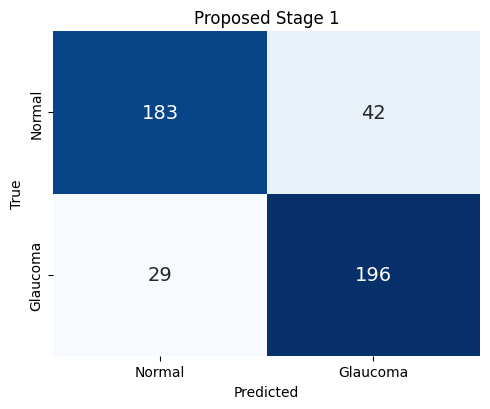

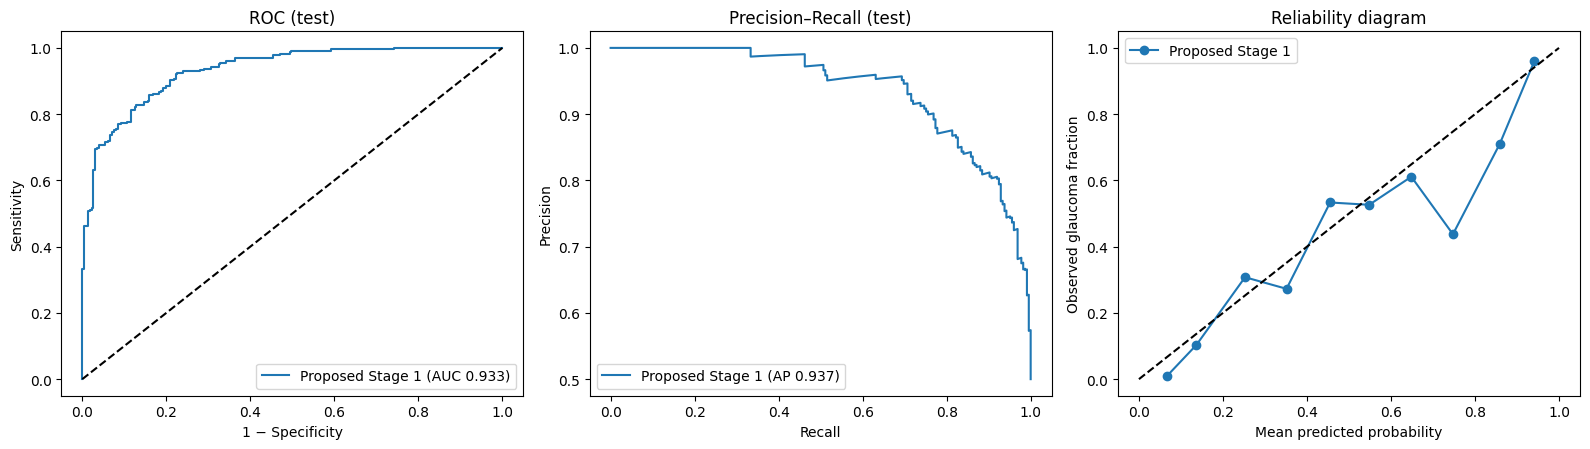

In [12]:
# ============================================================
# CELL 11 — Stage 1 vs baseline: tables, CIs, paired tests, figures
# ============================================================
rows = {'Proposed Stage 1 (thr 0.5)': m_te, f'Proposed Stage 1 (val-Youden {THR_YOUDEN:.2f})': m_te_y}
if BASELINE_OK: rows = {'Baseline DenseNet121': m_base, **rows}
tab_s1 = metrics_table(rows); display(tab_s1.round(4)); tab_s1.to_csv(f'{TAB_DIR}/stage1_vs_baseline_full_metrics.csv')

ci_prop = bootstrap_ci(y_te, p_te)
ci_rows = {'Proposed Stage 1': {k: f'{(m_te[k]*(100 if k in PCT_KEYS else 1)):.2f} [{lo*(100 if k in PCT_KEYS else 1):.2f}, {hi*(100 if k in PCT_KEYS else 1):.2f}]' for k, (lo, hi) in ci_prop.items()}}
if BASELINE_OK:
    ci_base = bootstrap_ci(y_te, p_base)
    ci_rows = {'Baseline DenseNet121': {k: f'{(m_base[k]*(100 if k in PCT_KEYS else 1)):.2f} [{lo*(100 if k in PCT_KEYS else 1):.2f}, {hi*(100 if k in PCT_KEYS else 1):.2f}]' for k, (lo, hi) in ci_base.items()}, **ci_rows}
ci_tab = pd.DataFrame(ci_rows).T; display(ci_tab); ci_tab.to_csv(f'{TAB_DIR}/stage1_bootstrap_95CI.csv')

PAIRED = None
if BASELINE_OK:
    PAIRED = paired_tests(y_te, p_te, p_base)
    print(f"McNemar exact p = {PAIRED['mcnemar_p']:.4f}  (proposed-only-correct {PAIRED['proposed_only_correct']} vs baseline-only-correct {PAIRED['baseline_only_correct']})")
    for k in ('acc_diff', 'auc_diff'):
        d = PAIRED[k]; print(f"Paired bootstrap Δ{k[:3]} = {d['mean']:+.4f}  95% CI [{d['lo']:+.4f}, {d['hi']:+.4f}]  p = {d['p']:.4f}")
    json.dump({k: (v if not isinstance(v, dict) else {a: float(b) for a, b in v.items()}) for k, v in PAIRED.items()},
              open(f'{TAB_DIR}/stage1_paired_tests.json', 'w'), indent=2, default=float)

# ---- Figures ----
fig, axs = plt.subplots(1, 2 if BASELINE_OK else 1, figsize=(10 if BASELINE_OK else 5, 4.2)); axs = np.atleast_1d(axs); k = 0
if BASELINE_OK: plot_cm(axs[k], confusion_matrix(y_te, (p_base >= .5).astype(int)), 'Baseline DenseNet121'); k += 1
plot_cm(axs[k], confusion_matrix(y_te, (p_te >= .5).astype(int)), 'Proposed Stage 1'); savefig('stage1_confusion_matrices.png')

fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
for nm, p, c in ([('Baseline DenseNet121', p_base, 'tab:orange')] if BASELINE_OK else []) + [('Proposed Stage 1', p_te, 'tab:blue')]:
    f_, t_, _ = roc_curve(y_te, p); axs[0].plot(f_, t_, c=c, label=f'{nm} (AUC {roc_auc_score(y_te, p):.3f})')
    pr_, rc_, _ = precision_recall_curve(y_te, p); axs[1].plot(rc_, pr_, c=c, label=f'{nm} (AP {average_precision_score(y_te, p):.3f})')
    bins = np.linspace(0, 1, 11); mp, fp_ = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mk = (p >= lo) & (p <= hi)
        if mk.sum() >= 5: mp.append(p[mk].mean()); fp_.append(y_te[mk].mean())
    axs[2].plot(mp, fp_, 'o-', c=c, label=nm)
axs[0].plot([0, 1], [0, 1], 'k--'); axs[0].set(xlabel='1 − Specificity', ylabel='Sensitivity', title='ROC (test)'); axs[0].legend()
axs[1].set(xlabel='Recall', ylabel='Precision', title='Precision–Recall (test)'); axs[1].legend()
axs[2].plot([0, 1], [0, 1], 'k--'); axs[2].set(xlabel='Mean predicted probability', ylabel='Observed glaucoma fraction', title='Reliability diagram'); axs[2].legend()
savefig('stage1_roc_pr_calibration.png')

## 5 · Stage 2 — Verification module (Deviation Gating Block + CDR head)
Stage 1 is frozen. Its 512-d embedding **A** is compared against the healthy prototype **E** of the matching disc-size bucket:

`D = σ(MLP([A, E, A−E, A⊙E]))`, `A′ = A ⊙ D`, `CDR = σ(FC(512→64→1)(A′))`.

* **E** = EMA (momentum 0.99) of embeddings from *confirmed non-glaucoma training images only*, one prototype per disc-size tercile.
* At inference there is no disc mask, so a small auxiliary head predicts the bucket from **A** (soft mixture of the three prototypes). Training uses the true bucket whenever the mask exists.
* For efficiency the frozen Stage-1 embeddings are cached for 8 augmented views + 1 clean view per training image; every epoch samples a random view per image (still real augmentation, no repeated CNN passes).
* Three variants are trained for the required ablation, each with 5 seeds: **no gate** → **gate with one global E** → **gate with disc-size-conditioned E (proposed)**.

In [13]:
# ============================================================
# CELL 12 — Frozen Stage-1 embeddings (augmented bank for train; clean for val/test)
# ============================================================
@torch.no_grad()
def extract_A(model, loader):
    model.eval(); out = []
    for batch in loader:
        with torch.amp.autocast('cuda', enabled=USE_AMP, dtype=torch.float16):
            out.append(model.embed(batch[0].to(DEVICE, non_blocking=True)).float())
    return torch.cat(out)

aug_loader = make_loader(train_df, train_tf, False)          # shuffle=False -> row order preserved
views = [extract_A(model1, train_eval_loader)]                # view 0 = clean
for v in range(CFG['s2_aug_views']):
    views.append(extract_A(model1, aug_loader))
A_TR = torch.stack(views, 1)                                  # (N_train, 1+K, 512)
A_VA, A_TE = extract_A(model1, val_loader), extract_A(model1, test_loader)

def split_meta(d):
    return dict(label=torch.tensor(d['label'].values, device=DEVICE),
                cdr=torch.tensor(d['vcdr_final'].fillna(0).values, dtype=torch.float32, device=DEVICE),
                has=torch.tensor(d['has_cdr'].values.astype(bool), device=DEVICE),
                bucket=torch.tensor(d['bucket'].values, dtype=torch.long, device=DEVICE))
M_TR, M_VA, M_TE = split_meta(train_df), split_meta(val_df), split_meta(test_df)
print('Embedding bank:', tuple(A_TR.shape), '| val', tuple(A_VA.shape), '| test', tuple(A_TE.shape))
print(f"Train labelled-CDR images: {int(M_TR['has'].sum())} | healthy w/ bucket: {int(((M_TR['label']==0)&(M_TR['bucket']>=0)).sum())} | healthy total: {int((M_TR['label']==0).sum())}")

Embedding bank: (2100, 9, 512) | val (450, 512) | test (450, 512)
Train labelled-CDR images: 437 | healthy w/ bucket: 302 | healthy total: 1050


In [14]:
# ============================================================
# CELL 13 — Deviation Gating Block, CDR head, verification network
# ============================================================
class DeviationGate(nn.Module):
    def __init__(self, dim=512, hidden=256, n_buckets=3, mode='conditioned', momentum=0.99):
        super().__init__()
        self.mode, self.m, self.nb = mode, momentum, n_buckets
        self.register_buffer('E_bucket', torch.zeros(n_buckets, dim)); self.register_buffer('E_global', torch.zeros(dim))
        self.register_buffer('ok_bucket', torch.zeros(n_buckets, dtype=torch.bool)); self.register_buffer('ok_global', torch.zeros((), dtype=torch.bool))
        # Comparator MLP: 2 linear layers + ReLU (LayerNorm on the concatenation is only for numerical stability)
        self.comparator = nn.Sequential(nn.LayerNorm(4 * dim), nn.Linear(4 * dim, hidden), nn.ReLU(inplace=True),
                                        nn.Dropout(0.3), nn.Linear(hidden, dim))
        nn.init.constant_(self.comparator[-1].bias, 2.0)       # D starts ≈0.88 -> gate starts close to identity
    @torch.no_grad()
    def update_prototype(self, A, bucket, healthy):
        if healthy.sum() == 0: return
        g = A[healthy].mean(0)
        self.E_global.copy_(g if not self.ok_global else self.m * self.E_global + (1 - self.m) * g); self.ok_global.fill_(True)
        for k in range(self.nb):
            sel = healthy & (bucket == k)
            if sel.any():
                mu = A[sel].mean(0)
                self.E_bucket[k] = mu if not self.ok_bucket[k] else self.m * self.E_bucket[k] + (1 - self.m) * mu
                self.ok_bucket[k] = True
    def reference(self, bucket_probs):
        if self.mode == 'global': return self.E_global.unsqueeze(0).expand(bucket_probs.shape[0], -1)
        return bucket_probs @ self.E_bucket                     # soft mixture of the 3 bucket prototypes
    def forward(self, A, bucket_probs):
        E = self.reference(bucket_probs)
        D = torch.sigmoid(self.comparator(torch.cat([A, E, A - E, A * E], 1)))
        return A * D, D

class VerificationNet(nn.Module):
    def __init__(self, mode, dim=512, momentum=0.99):
        super().__init__()
        self.mode = mode
        self.bucket_head = nn.Linear(dim, 3)                    # predicts disc-size bucket (no mask at inference)
        self.gate = None if mode == 'nogate' else DeviationGate(dim, 256, 3, mode, momentum)
        self.cdr_head = nn.Sequential(nn.Linear(dim, 64), nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(64, 1), nn.Sigmoid())
    def forward(self, A, bucket=None):
        blog = self.bucket_head(A); soft = torch.softmax(blog, 1)
        if bucket is None: probs = soft                                           # deployable: predicted bucket
        else:
            known = (bucket >= 0).unsqueeze(1)
            probs = torch.where(known, F.one_hot(bucket.clamp(min=0), 3).float(), soft.detach())   # true bucket where mask exists
        if self.gate is None: A2, D = A, None
        else: A2, D = self.gate(A, probs)
        return self.cdr_head(A2).squeeze(1), blog, D

@torch.no_grad()
def stage2_predict(net, A, bucket=None):
    net.eval(); cdr, blog, D = net(A, bucket)
    return cdr.cpu().numpy(), torch.softmax(blog, 1).cpu().numpy(), D

def train_stage2(mode, seed, epochs=None):
    epochs = epochs or CFG['s2_epochs']; set_seed(seed)
    net = VerificationNet(mode, momentum=CFG['s2_ema_momentum']).to(DEVICE)
    if net.gate is not None:
        h = M_TR['label'] == 0                                   # exact-mean init from clean healthy training embeddings, then EMA takes over
        net.gate.update_prototype(A_TR[:, 0][h], M_TR['bucket'][h], torch.ones(int(h.sum()), dtype=torch.bool, device=DEVICE))
    opt = torch.optim.AdamW(net.parameters(), lr=CFG['s2_lr'], weight_decay=CFG['s2_weight_decay'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=CFG['s2_lr'] * 0.01)
    N, K1, BS = A_TR.shape[0], A_TR.shape[1], CFG['s2_batch']
    best, best_state, best_ep, hist = 1e9, None, 0, []
    for ep in range(1, epochs + 1):
        net.train()
        A_all = A_TR[torch.arange(N, device=DEVICE), torch.randint(0, K1, (N,), device=DEVICE)]
        perm = torch.randperm(N, device=DEVICE); tl = nb = 0
        for i in range(0, N, BS):
            idx = perm[i:i + BS]; A, b, lab, has = A_all[idx], M_TR['bucket'][idx], M_TR['label'][idx], M_TR['has'][idx]
            if net.gate is not None: net.gate.update_prototype(A, b, lab == 0)         # EMA prototype from confirmed non-glaucoma only
            cdr, blog, _ = net(A, b)
            loss = torch.zeros((), device=DEVICE)
            if has.any(): loss = loss + F.smooth_l1_loss(cdr[has], M_TR['cdr'][idx][has], beta=0.1)
            kn = b >= 0
            if kn.any(): loss = loss + CFG['s2_bucket_loss_w'] * F.cross_entropy(blog[kn], b[kn])
            if not loss.requires_grad: continue
            opt.zero_grad(); loss.backward(); opt.step(); tl += loss.item(); nb += 1
        sched.step()
        with torch.no_grad():
            net.eval()
            cv, _, _ = net(A_VA); ct, _, _ = net(A_TR[:, 0])
            val_mae = (cv - M_VA['cdr'])[M_VA['has']].abs().mean().item(); tr_mae = (ct - M_TR['cdr'])[M_TR['has']].abs().mean().item()
        hist.append(dict(epoch=ep, train_loss=tl / max(nb, 1), train_mae=tr_mae, val_mae=val_mae))
        if val_mae < best: best, best_ep, best_state = val_mae, ep, copy.deepcopy(net.state_dict())
    net.load_state_dict(best_state); net.eval()
    return net, pd.DataFrame(hist), best_ep
print('Stage-2 modules ready.')

Stage-2 modules ready.


No gate (CDR head on A): done (5 seeds)
Deviation gate, global E: done (5 seeds)
Deviation gate, disc-size-conditioned E (proposed): done (5 seeds)


,cdr_mae,cdr_rmse,cdr_r2,cdr_pearson,cdr_mae_large,bucket_acc,pipe_acc,pipe_sens,pipe_spec,pipe_spec_large
variant,,,,,,,,,,
No gate (CDR head on A),0.0761 ± 0.0015,0.1017 ± 0.0018,0.4428 ± 0.0199,0.6679 ± 0.0137,0.0962 ± 0.0028,0.4336 ± 0.0280,0.8360 ± 0.0048,0.8507 ± 0.0112,0.8213 ± 0.0020,0.8824 ± 0.0000
"Deviation gate, global E",0.0786 ± 0.0010,0.1055 ± 0.0018,0.4014 ± 0.0203,0.6388 ± 0.0134,0.1010 ± 0.0018,0.4496 ± 0.0211,0.8307 ± 0.0060,0.8382 ± 0.0146,0.8231 ± 0.0049,0.8588 ± 0.0322
"Deviation gate, disc-size-conditioned E (proposed)",0.0779 ± 0.0005,0.1038 ± 0.0009,0.4203 ± 0.0103,0.6522 ± 0.0088,0.0992 ± 0.0015,0.4531 ± 0.0246,0.8333 ± 0.0102,0.8427 ± 0.0230,0.8240 ± 0.0051,0.8824 ± 0.0000


(test large-disc normal images available for the subgroup specificity: 17 — interpret with care)


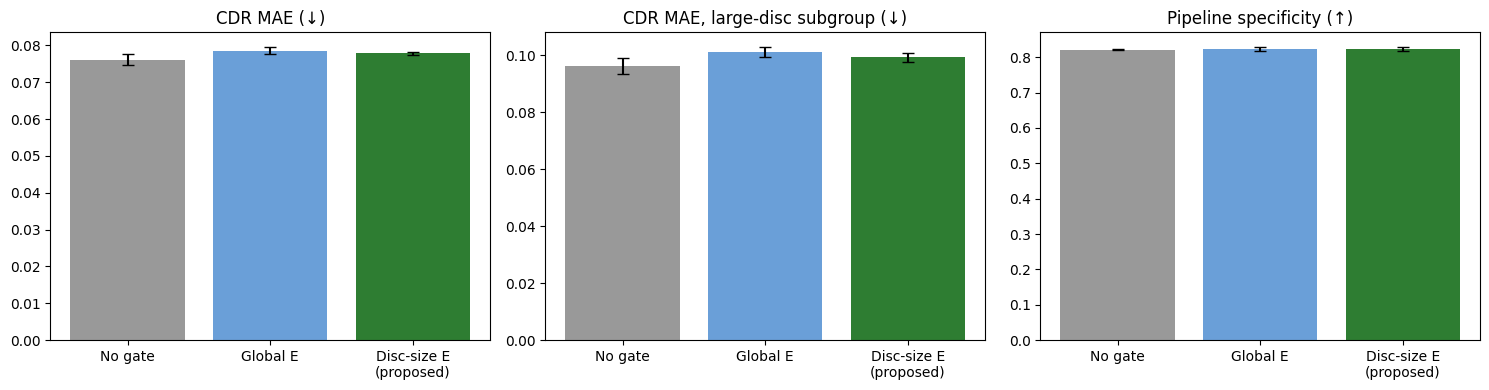

In [15]:
# ============================================================
# CELL 14 — Stage-2 ablation: no gate -> global-E gate -> disc-size-conditioned gate (5 seeds each, 50 epochs, no early stopping)
# ============================================================
SEV_T = CFG['sev_thresholds']
def sev_stage(v): return np.where(v < SEV_T[0], 0, np.where(v <= SEV_T[1], 1, 2))
def reg_metrics(pred, true):
    return dict(n=len(true), mae=float(np.mean(np.abs(pred - true))), rmse=float(np.sqrt(np.mean((pred - true) ** 2))),
                r2=float(r2_score(true, pred)), pearson=float(stats.pearsonr(pred, true)[0]), spearman=float(stats.spearmanr(pred, true)[0]))

def tune_tau(p, c, y, t1=0.5):
    best_ba, best_tau = -1, 0.0
    for tau in np.round(np.arange(0, 0.81, 0.01), 2):
        ba = balanced_accuracy_score(y, ((p >= t1) & (c >= tau)).astype(int))
        if ba > best_ba + 1e-12: best_ba, best_tau = ba, float(tau)       # strict '>' -> smallest tau among ties (least intervention)
    return best_tau

def rate(y, pred, cls):                                                     # sensitivity (cls=1) / specificity (cls=0)
    m = (y == cls); return float((pred[m] == cls).mean()) if m.sum() else float('nan')

b_te_np, y_te_np, has_te = M_TE['bucket'].cpu().numpy(), M_TE['label'].cpu().numpy(), M_TE['has'].cpu().numpy()
cdr_te_np = M_TE['cdr'].cpu().numpy()
large = b_te_np == 2

MODES = [('nogate', 'No gate (CDR head on A)'), ('global', 'Deviation gate, global E'), ('conditioned', 'Deviation gate, disc-size-conditioned E (proposed)')]
runs, NETS, HISTS = [], {}, {}
for mode, label in MODES:
    for sd in CFG['s2_seeds']:
        net, hist, bep = train_stage2(mode, sd); NETS[(mode, sd)], HISTS[(mode, sd)] = net, hist
        cv, _, _ = stage2_predict(net, A_VA); ct, bp, _ = stage2_predict(net, A_TE)                 # deployable (predicted bucket)
        co, _, _ = stage2_predict(net, A_TE, M_TE['bucket'])                                          # oracle bucket (analysis only)
        tau = tune_tau(p_val, cv, y_val); pipe = ((p_te >= .5) & (ct >= tau)).astype(int)
        rm = reg_metrics(ct[has_te], cdr_te_np[has_te]); known = (b_te_np >= 0)
        runs.append(dict(variant=label, mode=mode, seed=sd, best_epoch=bep, val_mae=hist.val_mae.min(),
                         cdr_mae=rm['mae'], cdr_rmse=rm['rmse'], cdr_r2=rm['r2'], cdr_pearson=rm['pearson'],
                         cdr_mae_oracle_bucket=float(np.mean(np.abs(co[has_te] - cdr_te_np[has_te]))),
                         cdr_mae_large=float(np.mean(np.abs(ct[has_te & large] - cdr_te_np[has_te & large]))) if (has_te & large).sum() else np.nan,
                         bucket_acc=float((bp.argmax(1)[known] == b_te_np[known]).mean()), tau=tau,
                         pipe_acc=float((pipe == y_te_np).mean()), pipe_sens=rate(y_te_np, pipe, 1), pipe_spec=rate(y_te_np, pipe, 0),
                         pipe_spec_large=rate(y_te_np[large], pipe[large], 0) if large.sum() else np.nan))
    print(f'{label}: done ({len(CFG["s2_seeds"])} seeds)')

runs_df = pd.DataFrame(runs); runs_df.to_csv(f'{TAB_DIR}/stage2_ablation_all_runs.csv', index=False)
num_cols = [c for c in runs_df.columns if c not in ('variant', 'mode', 'seed')]
agg = runs_df.groupby('variant', sort=False)[num_cols].agg(['mean', 'std'])
ablation = pd.DataFrame({c: [f"{agg.loc[v, (c, 'mean')]:.4f} ± {agg.loc[v, (c, 'std')]:.4f}" for v in agg.index] for c in
                         ['cdr_mae', 'cdr_rmse', 'cdr_r2', 'cdr_pearson', 'cdr_mae_large', 'bucket_acc', 'pipe_acc', 'pipe_sens', 'pipe_spec', 'pipe_spec_large']}, index=agg.index)
display(ablation); ablation.to_csv(f'{TAB_DIR}/stage2_ablation_mean_std.csv')
n_large_normal = int(((y_te_np == 0) & large).sum()); print(f'(test large-disc normal images available for the subgroup specificity: {n_large_normal} — interpret with care)')

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for a, (c, t) in zip(axs, [('cdr_mae', 'CDR MAE (↓)'), ('cdr_mae_large', 'CDR MAE, large-disc subgroup (↓)'), ('pipe_spec', 'Pipeline specificity (↑)')]):
    mu = [agg.loc[v, (c, 'mean')] for v in agg.index]; sd_ = [agg.loc[v, (c, 'std')] for v in agg.index]
    a.bar(range(3), mu, yerr=sd_, capsize=4, color=['#999', '#6a9fd8', '#2e7d32']); a.set_xticks(range(3)); a.set_xticklabels(['No gate', 'Global E', 'Disc-size E\n(proposed)']); a.set_title(t)
savefig('stage2_ablation.png')

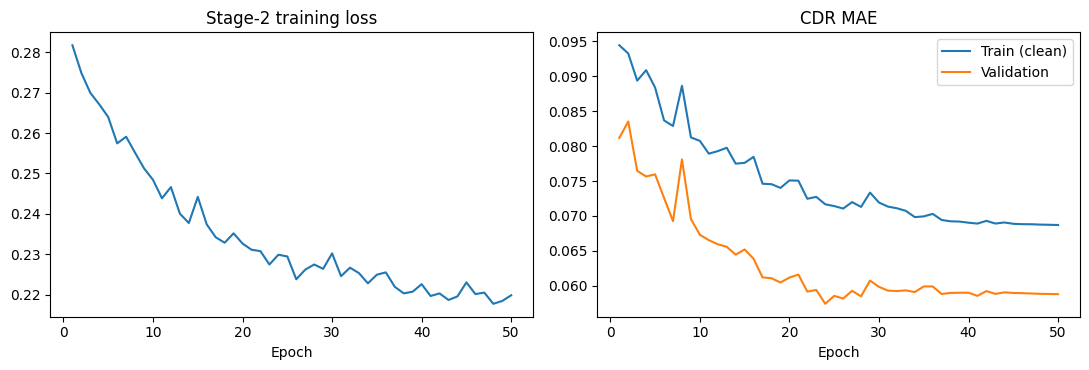

,n,mae,rmse,r2,pearson,spearman
All CDR-labelled,104.0,0.0776,0.1038,0.4201,0.6491,0.6700
Glaucoma only,35.0,0.0876,0.1164,0.5021,0.7413,0.7742
Normal only,69.0,0.0725,0.0968,0.2064,0.5318,0.5619
Small disc,32.0,0.0758,0.1160,0.1986,0.4760,0.5836
Medium disc,40.0,0.0611,0.0745,0.4572,0.7014,0.6697
Large disc,32.0,0.1001,0.1209,0.4271,0.6719,0.7177


Severity staging: {'n': 35, 'accuracy': 0.8571, 'f1_macro': 0.5092, 'quadratic_kappa': 0.5333}


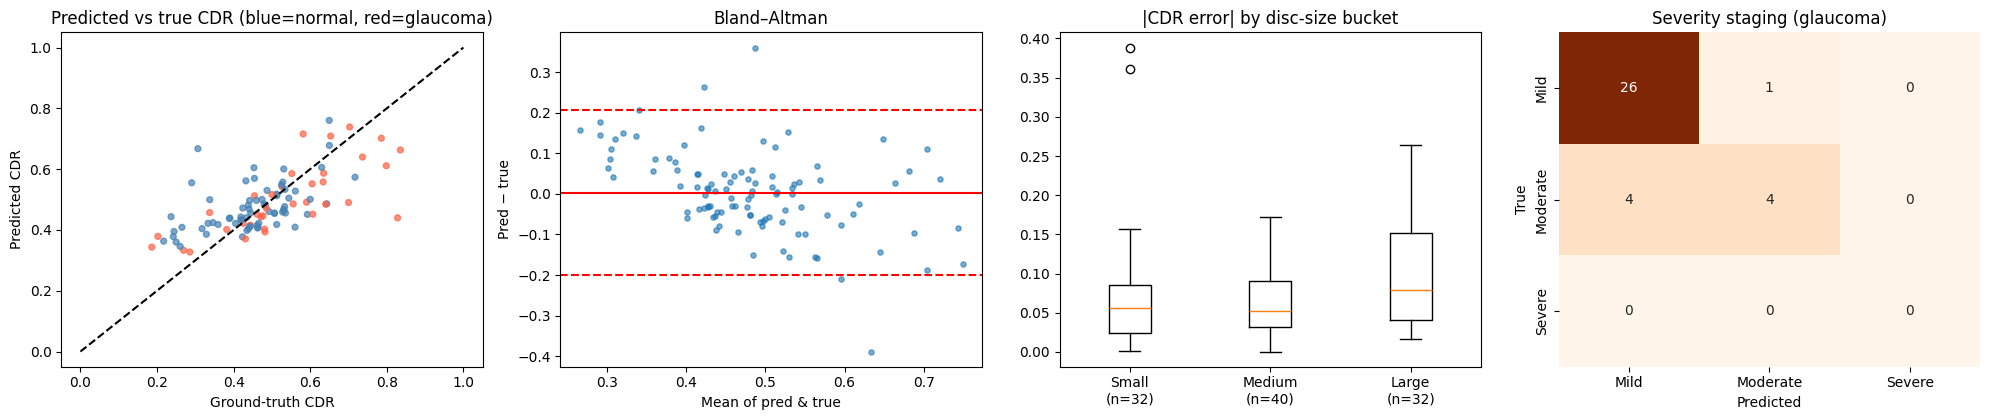

In [16]:
# ============================================================
# CELL 15 — PRIMARY model = proposed gate (conditioned E), first seed (fixed in advance, not cherry-picked)
# ============================================================
PRIMARY = ('conditioned', CFG['s2_seeds'][0]); net2 = NETS[PRIMARY]; hist2 = HISTS[PRIMARY]; hist2.to_csv(f'{TAB_DIR}/stage2_training_history.csv', index=False)
c_val, _, _ = stage2_predict(net2, A_VA); c_te, bprob_te, D_te = stage2_predict(net2, A_TE)
torch.save(net2.state_dict(), f'{CKPT_DIR}/stage2_deviation_gate_primary.pth')

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
axs[0].plot(hist2.epoch, hist2.train_loss); axs[0].set(title='Stage-2 training loss', xlabel='Epoch')
axs[1].plot(hist2.epoch, hist2.train_mae, label='Train (clean)'); axs[1].plot(hist2.epoch, hist2.val_mae, label='Validation'); axs[1].set(title='CDR MAE', xlabel='Epoch'); axs[1].legend()
savefig('stage2_training_curves.png')

# ---- CDR regression metrics (all CDR-labelled test images, glaucoma-only, and per disc-size bucket) ----
sub = {'All CDR-labelled': has_te, 'Glaucoma only': has_te & (y_te_np == 1), 'Normal only': has_te & (y_te_np == 0)}
for k, nm in enumerate(BUCKET_NAMES): sub[f'{nm} disc'] = has_te & (b_te_np == k)
cdr_tab = pd.DataFrame({nm: reg_metrics(c_te[m], cdr_te_np[m]) for nm, m in sub.items() if m.sum() > 2}).T
display(cdr_tab.round(4)); cdr_tab.to_csv(f'{TAB_DIR}/cdr_regression_metrics.csv')

# ---- Severity staging (glaucoma-labelled test images with CDR; thresholds 0.65 / 0.85 as in the baseline pipeline) ----
gm = has_te & (y_te_np == 1); st_true, st_pred = sev_stage(cdr_te_np[gm]), sev_stage(c_te[gm])
cm_sev = confusion_matrix(st_true, st_pred, labels=[0, 1, 2])
sev = dict(n=int(gm.sum()), accuracy=float((st_true == st_pred).mean()), f1_macro=float(f1_score(st_true, st_pred, average='macro', labels=[0, 1, 2], zero_division=0)),
           quadratic_kappa=float(cohen_kappa_score(st_true, st_pred, weights='quadratic')))
print('Severity staging:', {k: round(v, 4) if isinstance(v, float) else v for k, v in sev.items()}); json.dump(sev, open(f'{TAB_DIR}/severity_staging_metrics.json', 'w'), indent=2)

fig, axs = plt.subplots(1, 4, figsize=(20, 4.3))
cols = np.array(['steelblue', 'tomato'])[y_te_np[has_te]]
axs[0].scatter(cdr_te_np[has_te], c_te[has_te], c=cols, s=18, alpha=.7); axs[0].plot([0, 1], [0, 1], 'k--'); axs[0].set(xlabel='Ground-truth CDR', ylabel='Predicted CDR', title='Predicted vs true CDR (blue=normal, red=glaucoma)')
mean_, diff_ = (c_te[has_te] + cdr_te_np[has_te]) / 2, c_te[has_te] - cdr_te_np[has_te]
axs[1].scatter(mean_, diff_, s=14, alpha=.6); axs[1].axhline(diff_.mean(), c='r'); axs[1].axhline(diff_.mean() + 1.96 * diff_.std(), c='r', ls='--'); axs[1].axhline(diff_.mean() - 1.96 * diff_.std(), c='r', ls='--'); axs[1].set(xlabel='Mean of pred & true', ylabel='Pred − true', title='Bland–Altman')
bm_ = [np.abs(c_te[has_te & (b_te_np == k)] - cdr_te_np[has_te & (b_te_np == k)]) for k in range(3)]
axs[2].boxplot([x for x in bm_ if len(x)]); axs[2].set_xticklabels([f'{n}\n(n={len(x)})' for n, x in zip(BUCKET_NAMES, bm_) if len(x)]); axs[2].set(title='|CDR error| by disc-size bucket')
sns.heatmap(cm_sev, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=axs[3], xticklabels=['Mild', 'Moderate', 'Severe'], yticklabels=['Mild', 'Moderate', 'Severe']); axs[3].set(xlabel='Predicted', ylabel='True', title='Severity staging (glaucoma)')
savefig('stage2_cdr_analysis.png')

## 5b · Stage-2 AUDIT, diagnostics and v2 (added cells — nothing above is edited, so the published numbers stay reproducible)

**What the audit of CELLs 2–15 found** (✔ = verified from code/printed output, ? = hypothesis that the cells below test)

| # | Finding | Where | Status |
|---|---|---|---|
| 1 | **The DGB cannot receive any information at inference that is not already in A.** The reference is `softmax(bucket_head(A)) @ E_k` (a function of A); with a global E the input `[A, E, A−E, A⊙E]` is A re-parametrised. So the gate can only act as an inductive bias, never as an *independent anatomical measurement*. | CELL 13 `VerificationNet.forward`, `DeviationGate.reference` | ✔ (algebra) |
| 2 | **Train/inference mismatch of the bucket.** Training uses the TRUE one-hot bucket wherever a mask exists, inference always the predicted soft bucket. CDR labels and masks almost coincide (437 vs 477 train images), so almost every CDR-supervised sample is trained with the oracle bucket. | CELL 13 `torch.where(known, one_hot, soft.detach())` | ✔ code, magnitude in 15a |
| 3 | **Stacking shift.** Stage 2 is fitted on embeddings of images Stage 1 was trained on (train AUC 0.980 / acc 92.4 % vs val 0.951 / 86.2 %), then applied to unseen images. Healthy "prototypes" are therefore tighter/more extreme than unseen healthy eyes. | CELL 9 output, CELL 12 | ✔ numbers, effect size in 15c |
| 4 | **Prototype construction is inconsistent and noisy.** Bucket prototypes use only healthy images with a mask (302 of 1050), the global one all 1050; both are EMAs (m = 0.99) over *augmented* minibatches with ≈3 bucketed healthy images per bucket per batch. | CELL 13 `update_prototype`, `train_stage2` | ✔ code; separation vs noise in 15c |
| 5 | **The "oracle bucket" metric in CELL 14 is diluted** (averaged over all CDR-labelled test images, but images without a mask silently fall back to the predicted bucket) and is never shown in the table. | CELL 14 `co`, `cdr_mae_oracle_bucket` | ✔ → corrected in 15b |
| 6 | **Low power / narrow evidence.** 104 CDR-labelled test images (69 normal / 35 glaucoma, no severe), 90 validation labels, 437 training labels. The ablation differences (0.0721 / 0.0724 / 0.0729) are far below what this test set can resolve; seeds share one cached augmentation bank and one test set, so the ± understates uncertainty. "No benefit" is supported, "no effect" is not. | CELL 14 | ✔ |
| 7 | **Disc-size labels are weak and annotation availability is label-skewed** (test: 75 normal / 38 glaucoma with a mask vs 50/50 overall). Disc diameter ÷ black-border-crop side depends on field of view and on pre-cropped sources, not only on anatomy; bucket accuracy 52 % (chance 33 %, majority ≈ 40 %) is partly intrinsic to cutting a continuous quantity into terciles. | CELL 3 `process_row` | ? → 15a, 15b, 15e |
| 8 | **Features.** A is a globally pooled, dropout-trained *classification* embedding; cup/disc geometry is spatial. Train CDR MAE ≥ val MAE (Fig. 7 of the draft) with 437 labels means the head is not fitting its own labels. | CELL 6, CELL 13 | ? → 15e |
| 9 | **Possible patient-level leakage** (image-level `train_test_split`; SMDG-type collections contain both eyes / repeated images). | CELL 2 | ? → 15a, optional CELL 2-G |

**Checked and found correct:** row alignment (`row_id` → cache → loaders; embedding bank built with `shuffle=False`), reproduction of the 2100/450/450 split, tercile cut-offs from train only, prototypes from train only, epoch and τ chosen on validation only, no gradient leakage (E are buffers; `bucket_head` receives only the CE loss), tensor shapes, R² formula.

**Run order:** 15a → 15b → 15c are read-only audits (15b needs CELL 14 results in memory or `stage2_orig_all_nets.pth`; it also builds `ORIG`, the original Stage-2 predictions that v3 is compared against). Then 15d → S2-1 → S2-2 → S2-3 → S2-4 (Stage-2 v3).


In [17]:
# ============================================================
# CELL 15a — Stage-2 AUDIT I: annotation structure, leakage screens, premise check (no model needed)
# ============================================================
try: display
except NameError: display = print
import re

# ---- 0. what does each split actually contain? (CDR labels / disc masks overlap with each other and with the diagnosis) ----
rows = []
for nm, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    for lab in (0, 1):
        m = d['label'] == lab
        rows.append(dict(split=nm, label=['normal', 'glaucoma'][lab], n=int(m.sum()), has_cdr=int(d.has_cdr[m].sum()),
                         bucket_known=int((d.bucket[m] >= 0).sum()), both=int(((d.bucket >= 0) & (d.has_cdr == 1) & m).sum()),
                         cdr_only=int(((d.bucket < 0) & (d.has_cdr == 1) & m).sum()), bucket_only=int(((d.bucket >= 0) & (d.has_cdr == 0) & m).sum()),
                         cdr_mean=d.vcdr_final[m].mean(), cdr_sd=d.vcdr_final[m].std()))
cohort = pd.DataFrame(rows); display(cohort.round(3)); cohort.to_csv(f'{TAB_DIR}/audit_cohort_annotations.csv', index=False)
tr_both = int(((train_df.bucket >= 0) & (train_df.has_cdr == 1)).sum())
print(f'Train images with CDR label: {int(train_df.has_cdr.sum())} ({train_df.has_cdr.mean()*100:.1f}%) | with bucket: {int((train_df.bucket>=0).sum())} | with BOTH: {tr_both}')
print(f'  -> {tr_both/max(int(train_df.has_cdr.sum()),1)*100:.0f}% of the CDR-supervised train images are trained with the TRUE (oracle) bucket, '
      f'but every val/test image is scored with a PREDICTED bucket (train/inference mismatch in CELL 13).')

# ---- 1. source / dataset guess from file names (heuristic: leading letters of `names`; CHECK THE PRINTED SAMPLES) ----
def src_guess(s):
    m = re.match(r'[A-Za-z]+', str(s).split('/')[-1]); return m.group(0).lower() if m else 'unk'
for d in (train_df, val_df, test_df): d['source_guess'] = d['names'].map(src_guess)
print('Sample names:', train_df['names'].astype(str).sample(8, random_state=0).tolist())
src_tab = pd.concat([d.assign(split=nm) for nm, d in [('train', train_df), ('val', val_df), ('test', test_df)]]) \
            .groupby('source_guess').agg(n=('label', 'size'), glaucoma_rate=('label', 'mean'), has_cdr=('has_cdr', 'mean'),
                                         bucket_known=('bucket', lambda b: (b >= 0).mean()), disc_ratio_mean=('disc_ratio', 'mean'),
                                         disc_ratio_sd=('disc_ratio', 'std')).sort_values('n', ascending=False)
display(src_tab.round(3).head(15)); src_tab.to_csv(f'{TAB_DIR}/audit_source_guess.csv')
print('If glaucoma_rate / has_cdr / disc_ratio differ strongly between sources, annotation availability and disc ratio are source (camera/field-of-view) proxies.')

# ---- 2. PREMISE CHECK: in THIS data, does CDR actually depend on disc size among healthy eyes? ----
lab_tr = train_df[(train_df.has_cdr == 1) & train_df.disc_ratio.notna()]
for nm, m in [('all', lab_tr), ('normal', lab_tr[lab_tr.label == 0]), ('glaucoma', lab_tr[lab_tr.label == 1])]:
    if len(m) > 5:
        r, p = stats.spearmanr(m.disc_ratio, m.vcdr_final); print(f'Spearman(disc_ratio, vCDR) | train {nm:9s} n={len(m):3d}: rho={r:+.3f} (p={p:.3g})')
print('A weak/zero rho among NORMAL eyes means the disc-size confound the DGB is built around is not visible in these labels.')

# ---- 3. constant-predictor reference (what does MAE 0.072 mean?) ----
c_med = train_df.vcdr_final.median()
for nm, d in [('val', val_df), ('test', test_df)]:
    v = d.vcdr_final.dropna().values; print(f'Predict-train-median CDR ({c_med:.3f}) -> {nm} MAE {np.abs(v-c_med).mean():.4f} (n={len(v)}) | label SD {v.std():.4f}')

# ---- 4. patient / near-duplicate leakage screen ----
def eye_group(name):
    s = re.sub(r'\.[A-Za-z]{3,4}$', '', str(name).split('/')[-1])
    return re.sub(r'(?i)(?<![a-z])(od|os|oi|re|le|left|right|l|r)(?![a-z])', '', s).strip('_-. ')
allg = pd.concat([train_df.assign(split='train'), val_df.assign(split='val'), test_df.assign(split='test')])
allg['group_guess'] = allg['names'].map(eye_group)
spans = allg.groupby('group_guess')['split'].nunique(); multi = allg.groupby('group_guess').size()
print(f"Name-based eye/patient groups: {len(spans)} groups; groups with >1 image: {(multi>1).sum()}; groups spanning >1 split: {(spans>1).sum()}")
print('  (name heuristic only — verify against real patient IDs if SMDG metadata has them.)')

def thumbs(rows, s=24):
    out = np.empty((len(rows), s * s), np.float32)
    for k, r in enumerate(rows):
        g = cv2.resize(cv2.cvtColor(X[r], cv2.COLOR_RGB2GRAY), (s, s), interpolation=cv2.INTER_AREA).astype(np.float32).ravel()
        g -= g.mean(); out[k] = g / (np.linalg.norm(g) + 1e-6)
    return out
T_tr = thumbs(train_df.row_id.values)
THUMB = {}
for nm, d in [('val', val_df), ('test', test_df)]:
    T = thumbs(d.row_id.values); sim = T @ T_tr.T; j = sim.argmax(1); mx = sim.max(1)
    THUMB[nm] = (mx, j)
    print(f'{nm}: max cosine to a TRAIN thumbnail — quantiles 50/90/99/max = {np.quantile(mx,[.5,.9,.99,1]).round(4)} | n >= 0.99: {(mx>=0.99).sum()} | n >= 0.98: {(mx>=0.98).sum()}')
    top = np.argsort(-mx)[:5]
    for t in top: print(f'    {d.names.iloc[t]}  <->  {train_df.names.iloc[j[t]]}   cos={mx[t]:.4f}')
print('Near-identical pairs (cos >= ~0.99) across splits => duplicates / same patient; inspect the printed pairs visually before trusting any number in this notebook.')


,split,label,n,has_cdr,bucket_known,both,cdr_only,bucket_only,cdr_mean,cdr_sd
0,train,normal,1050,279,302,279,0,23,0.441,0.119
1,train,glaucoma,1050,158,175,158,0,17,0.568,0.163
2,val,normal,225,61,67,61,0,6,0.458,0.096
3,val,glaucoma,225,29,31,29,0,2,0.599,0.164
4,test,normal,225,69,75,69,0,6,0.451,0.109
5,test,glaucoma,225,35,38,35,0,3,0.536,0.167


Train images with CDR label: 437 (20.8%) | with bucket: 477 | with BOTH: 437
  -> 100% of the CDR-supervised train images are trained with the TRUE (oracle) bucket, but every val/test image is scored with a PREDICTED bucket (train/inference mismatch in CELL 13).
Sample names: ['OIA-ODIR-TEST-OFFLINE-247', 'OIA-ODIR-TRAIN-2950', 'OIA-ODIR-TEST-OFFLINE-23', 'EyePACS-Glaucoma-2339', 'REFUGE1-val-39', 'EyePACS-Glaucoma-3015', 'G1020-491', 'EyePACS-Glaucoma-1635']


,n,glaucoma_rate,has_cdr,bucket_known,disc_ratio_mean,disc_ratio_sd
source_guess,,,,,,
eyepacs,976,1.000,0.000,0.000,NaN,NaN
oia,959,0.123,0.000,0.000,NaN,NaN
g,243,0.412,0.765,1.000,0.145,0.014
refuge,158,0.171,1.000,1.000,0.148,0.014
origa,149,0.349,1.000,1.000,0.145,0.014
beh,144,0.389,0.000,0.000,NaN,NaN
papila,110,0.418,1.000,1.000,0.188,0.020
fives,105,0.495,0.000,0.000,NaN,NaN
sjchoi,94,0.362,0.000,0.000,NaN,NaN


If glaucoma_rate / has_cdr / disc_ratio differ strongly between sources, annotation availability and disc ratio are source (camera/field-of-view) proxies.
Spearman(disc_ratio, vCDR) | train all       n=437: rho=+0.067 (p=0.163)
Spearman(disc_ratio, vCDR) | train normal    n=279: rho=-0.076 (p=0.203)
Spearman(disc_ratio, vCDR) | train glaucoma  n=158: rho=+0.160 (p=0.0449)
A weak/zero rho among NORMAL eyes means the disc-size confound the DGB is built around is not visible in these labels.
Predict-train-median CDR (0.478) -> val MAE 0.1067 (n=90) | label SD 0.1372
Predict-train-median CDR (0.478) -> test MAE 0.1030 (n=104) | label SD 0.1363
Name-based eye/patient groups: 3000 groups; groups with >1 image: 0; groups spanning >1 split: 0
  (name heuristic only — verify against real patient IDs if SMDG metadata has them.)
val: max cosine to a TRAIN thumbnail — quantiles 50/90/99/max = [0.9566 0.9806 0.9893 0.9997] | n >= 0.99: 4 | n >= 0.98: 51
    BEH-338  <->  BEH-334   cos=0.9997
    BE

In [18]:
# ============================================================
# CELL 15b — Stage-2 AUDIT II: identical-sample paired ablation + oracle / predicted / wrong-bucket diagnostics
#            (uses the 15 networks trained in CELL 14; they are saved to disk so the audit survives a Colab restart)
# ============================================================
try: display
except NameError: display = print

ORIG_NET_PATH = f'{CKPT_DIR}/stage2_orig_all_nets.pth'
if 'NETS' in globals() and len(NETS) > 0:
    torch.save({f'{m}|{s}': n.state_dict() for (m, s), n in NETS.items()}, ORIG_NET_PATH)
elif os.path.exists(ORIG_NET_PATH):
    NETS = {}
    for k, v in torch.load(ORIG_NET_PATH, map_location=DEVICE, weights_only=False).items():
        m, s = k.split('|'); n_ = VerificationNet(m, momentum=CFG['s2_ema_momentum']).to(DEVICE); n_.load_state_dict(v); n_.eval(); NETS[(m, int(s))] = n_
else:
    raise RuntimeError('Run CELL 14 first (NETS missing and no saved copy found).')
SEEDS = list(CFG['s2_seeds']); MODE_KEYS = ['nogate', 'global', 'conditioned']

# ---------- helpers reused by later cells ----------
def per_sample_abs_err(preds, true, mask):                         # preds (S, n) -> mean over seeds, per image
    return np.abs(preds[:, mask] - true[mask]).mean(0)
def paired_delta(Ea, Eb, n_boot=5000, seed=0):                      # Ea, Eb: per-image errors of two methods on the SAME images
    d = np.asarray(Ea) - np.asarray(Eb); n = len(d); rng = np.random.default_rng(seed)
    bs = d[rng.integers(0, n, (n_boot, n))].mean(1)
    try: w = float(stats.wilcoxon(d).pvalue)
    except ValueError: w = 1.0
    return dict(delta=float(d.mean()), lo=float(np.percentile(bs, 2.5)), hi=float(np.percentile(bs, 97.5)), wilcoxon_p=w, n=n,
                mde80=float(2.8 * d.std(ddof=1) / np.sqrt(n)))
@torch.no_grad()
def gate_apply(net, A, E):                                          # gate with an explicit reference E (B,512)
    D = torch.sigmoid(net.gate.comparator(torch.cat([A, E, A - E, A * E], 1))); return A * D, D
@torch.no_grad()
def cdr_from_probs(net, A, probs):
    net.eval(); A2 = net.gate(A, probs)[0] if net.gate is not None else A
    return net.cdr_head(A2).squeeze(1)

# ---------- 1. per-image predictions of every original network ----------
ORIG = {m: dict(val=[], test=[], bprob=[]) for m in MODE_KEYS}
for m in MODE_KEYS:
    for s in SEEDS:
        cv, _, _ = stage2_predict(NETS[(m, s)], A_VA); ct, bp, _ = stage2_predict(NETS[(m, s)], A_TE)
        ORIG[m]['val'].append(cv); ORIG[m]['test'].append(ct); ORIG[m]['bprob'].append(bp)
ORIG = {m: {k: np.array(v) for k, v in d.items()} for m, d in ORIG.items()}
true_te, true_va = cdr_te_np, M_VA['cdr'].cpu().numpy(); has_va = M_VA['has'].cpu().numpy()

# ---------- 2. paired ablation on IDENTICAL test images (resample images, seed-averaged errors) ----------
E = {m: per_sample_abs_err(ORIG[m]['test'], true_te, has_te) for m in MODE_KEYS}
rows = []
for a, b in [('conditioned', 'nogate'), ('global', 'nogate'), ('conditioned', 'global')]:
    r = paired_delta(E[a], E[b]); rows.append(dict(comparison=f'{a} − {b}', n_images=r['n'], delta_MAE=r['delta'], ci_lo=r['lo'], ci_hi=r['hi'],
                                                   wilcoxon_p=r['wilcoxon_p'], min_detectable_delta_80pct_power=r['mde80']))
paired_orig = pd.DataFrame(rows); display(paired_orig.round(5)); paired_orig.to_csv(f'{TAB_DIR}/audit_paired_ablation_original.csv', index=False)
print(f'MAE per image is averaged over the {len(SEEDS)} seeds, then the TEST IMAGES are bootstrapped (5000x). Negative delta = first method better.')
print(f"Smallest MAE difference this {int(has_te.sum())}-image test set could reliably detect (80% power): ~{paired_orig.min_detectable_delta_80pct_power.min():.4f}")
print('Best epoch chosen on validation (low numbers => the gate barely trained / early epoch won on 90 noisy val labels):')
display(runs_df.groupby('mode')['best_epoch'].agg(['mean', 'min', 'max']).round(1))

# ---------- 3. bucket head quality (deployed) ----------
known = b_te_np >= 0; bp_mean = ORIG['conditioned']['bprob'].mean(0)
pred_b = bp_mean.argmax(1)[known]; true_b = b_te_np[known]
cm_b = confusion_matrix(true_b, pred_b, labels=[0, 1, 2]); err = pred_b != true_b
print(f'Bucket head (test, n={known.sum()}): accuracy {np.mean(pred_b==true_b):.3f} | majority-class baseline {np.bincount(true_b).max()/len(true_b):.3f} | chance 0.333')
print(f'  errors that are adjacent buckets (|pred-true|=1): {np.mean(np.abs(pred_b-true_b)[err]==1):.2f}  (high share => tercile boundaries are cutting a continuous variable, not a gross failure)')
print(pd.DataFrame(cm_b, index=[f'true {n}' for n in BUCKET_NAMES], columns=[f'pred {n}' for n in BUCKET_NAMES]))

# ---------- 4. ORACLE vs PREDICTED vs WRONG bucket — on the images that really have BOTH a CDR label and a bucket ----------
I = has_te & known; nI = int(I.sum()); print(f'\nOracle diagnostic set: {nI} test images with BOTH CDR label and true bucket (DIAGNOSTIC ONLY — oracle buckets do not exist at deployment)')
note = ('NOTE: CELL 14 column `cdr_mae_oracle_bucket` averages over ALL CDR-labelled images, including those WITHOUT a bucket, '
        'for which the oracle falls back to the predicted bucket -> it is diluted. Use the table below instead.')
print(note)
rng = np.random.default_rng(0); b_I = torch.tensor(b_te_np[I], device=DEVICE); A_I = A_TE[torch.tensor(I, device=DEVICE)]; y_I = true_te[I]
cond_res = {k: [] for k in ['predicted (deployed)', 'oracle bucket', 'wrong bucket (b+1)', 'shuffled true bucket', 'uniform 1/3', 'global E (reference swap)']}
cond_sens = {k: [] for k in cond_res}
for s in SEEDS:
    net = NETS[('conditioned', s)]
    soft = torch.softmax(net.bucket_head(A_I), 1)
    ref = cdr_from_probs(net, A_I, soft).cpu().numpy()
    probs = {'predicted (deployed)': soft, 'oracle bucket': F.one_hot(b_I, 3).float(), 'wrong bucket (b+1)': F.one_hot((b_I + 1) % 3, 3).float(),
             'shuffled true bucket': F.one_hot(b_I[torch.tensor(rng.permutation(nI), device=DEVICE)], 3).float(),
             'uniform 1/3': torch.full_like(soft, 1 / 3)}
    for k, pr in probs.items():
        c = cdr_from_probs(net, A_I, pr).cpu().numpy(); cond_res[k].append(np.abs(c - y_I).mean()); cond_sens[k].append(np.abs(c - ref).mean())
    with torch.no_grad():
        A2, _ = gate_apply(net, A_I, net.gate.E_global.unsqueeze(0).expand(nI, -1)); c = net.cdr_head(A2).squeeze(1).cpu().numpy()
    cond_res['global E (reference swap)'].append(np.abs(c - y_I).mean()); cond_sens['global E (reference swap)'].append(np.abs(c - ref).mean())
ng = [np.abs(ORIG['nogate']['test'][i][I] - y_I).mean() for i in range(len(SEEDS))]
orc = pd.DataFrame({'MAE mean': {k: np.mean(v) for k, v in cond_res.items()}, 'MAE sd': {k: np.std(v, ddof=1) for k, v in cond_res.items()},
                    'mean |ΔCDR| vs deployed prediction': {k: np.mean(v) for k, v in cond_sens.items()}})
orc.loc['(no-gate network, same images)'] = [np.mean(ng), np.std(ng, ddof=1), np.nan]
display(orc.round(5)); orc.to_csv(f'{TAB_DIR}/audit_oracle_bucket_diagnostic.csv')
print('Reading guide: if oracle ≈ predicted ≈ wrong-bucket ≈ uniform (and |ΔCDR| << MAE), the CDR head ignores WHICH prototype it is given => bucket-prediction errors are NOT the cause of the failure.')
print('If oracle << predicted, bucket prediction is the bottleneck. If wrong-bucket >> predicted, the head does use the bucket.')


,comparison,n_images,delta_MAE,ci_lo,ci_hi,wilcoxon_p,min_detectable_delta_80pct_power
0,conditioned − nogate,104,0.00177,0.00056,0.00297,0.00639,0.00169
1,global − nogate,104,0.00252,0.00098,0.00414,0.00170,0.00221
2,conditioned − global,104,-0.00075,-0.00184,0.00032,0.20482,0.00156


MAE per image is averaged over the 5 seeds, then the TEST IMAGES are bootstrapped (5000x). Negative delta = first method better.
Smallest MAE difference this 104-image test set could reliably detect (80% power): ~0.0016
Best epoch chosen on validation (low numbers => the gate barely trained / early epoch won on 90 noisy val labels):


,mean,min,max
mode,,,
conditioned,32.2,24,38
global,33.2,24,38
nogate,38.8,35,48


Bucket head (test, n=113): accuracy 0.442 | majority-class baseline 0.398 | chance 0.333
  errors that are adjacent buckets (|pred-true|=1): 0.81  (high share => tercile boundaries are cutting a continuous variable, not a gross failure)
             pred Small  pred Medium  pred Large
true Small           16           11           9
true Medium          14           14          17
true Large            3            9          20

Oracle diagnostic set: 104 test images with BOTH CDR label and true bucket (DIAGNOSTIC ONLY — oracle buckets do not exist at deployment)
NOTE: CELL 14 column `cdr_mae_oracle_bucket` averages over ALL CDR-labelled images, including those WITHOUT a bucket, for which the oracle falls back to the predicted bucket -> it is diluted. Use the table below instead.


,MAE mean,MAE sd,mean |ΔCDR| vs deployed prediction
predicted (deployed),0.07786,0.00049,0.00000
oracle bucket,0.07779,0.00055,0.00040
wrong bucket (b+1),0.07789,0.00050,0.00044
shuffled true bucket,0.07787,0.00044,0.00041
uniform 1/3,0.07787,0.00048,0.00009
global E (reference swap),0.07817,0.00048,0.00195
"(no-gate network, same images)",0.07609,0.00147,NaN


Reading guide: if oracle ≈ predicted ≈ wrong-bucket ≈ uniform (and |ΔCDR| << MAE), the CDR head ignores WHICH prototype it is given => bucket-prediction errors are NOT the cause of the failure.
If oracle << predicted, bucket prediction is the bottleneck. If wrong-bucket >> predicted, the head does use the bucket.


In [19]:
# ============================================================
# CELL 15c — Stage-2 AUDIT III: prototype quality, gate saturation, what the gate reads, gradients, train→val embedding shift
# ============================================================
try: display
except NameError: display = print
dev_np = lambda t: t.detach().cpu().numpy()
b_tr_np, y_tr_np = dev_np(M_TR['bucket']), dev_np(M_TR['label']); A0 = dev_np(A_TR[:, 0])

# ---------- 1. Are the three healthy prototypes distinguishable from sampling noise? (permutation test on bucket labels) ----------
sel = (y_tr_np == 0) & (b_tr_np >= 0); Ah, bh = A0[sel], b_tr_np[sel]
def mean_pair_dist(Ab, bb):
    Es = [Ab[bb == k].mean(0) for k in range(3)]; return float(np.mean([np.linalg.norm(Es[i] - Es[j]) for i in range(3) for j in range(i + 1, 3)]))
obs = mean_pair_dist(Ah, bh); rng = np.random.default_rng(0); null = np.array([mean_pair_dist(Ah, rng.permutation(bh)) for _ in range(2000)])
pair_typ = float(np.mean(np.linalg.norm(Ah[rng.integers(0, len(Ah), 500)] - Ah[rng.integers(0, len(Ah), 500)], axis=1)))
print(f'Healthy train images with a bucket: {len(Ah)}  (per bucket: {np.bincount(bh, minlength=3).tolist()})  — vs {int((y_tr_np==0).sum())} healthy images in total')
print(f'Mean pairwise ‖E_k − E_j‖ (clean embeddings): observed {obs:.4f} | permutation-null mean {null.mean():.4f} (95th pct {np.quantile(null, .95):.4f}) | p = {(null >= obs).mean():.4f}')
print(f'  observed/null = {obs/null.mean():.2f}x ; typical distance between two random healthy embeddings = {pair_typ:.3f}  => prototype separation is {obs/pair_typ*100:.1f}% of one sample-to-sample distance')
print('  observed ≈ null => the "disc-size-specific" prototypes are statistically the same vector; E_k differs from E_global only by sampling noise.')
E_net = NETS[('conditioned', SEEDS[0])].gate
Eb = dev_np(E_net.E_bucket); Eg = dev_np(E_net.E_global)
print('Trained-net prototypes (seed 0, end-of-training EMA of AUGMENTED minibatches): pairwise ‖E_k−E_j‖ =',
      [round(float(np.linalg.norm(Eb[i] - Eb[j])), 4) for i in range(3) for j in range(i + 1, 3)], '| ‖E_k−E_global‖ =', [round(float(np.linalg.norm(Eb[k] - Eg)), 4) for k in range(3)])
n_per_batch = CFG['s2_batch'] * (sel.sum() / len(A0)) / 3
print(f'EMA noise: ≈{n_per_batch:.1f} healthy bucketed images per bucket per minibatch of {CFG["s2_batch"]} with momentum {CFG["s2_ema_momentum"]} (global E sees ≈{CFG["s2_batch"]*(y_tr_np==0).mean():.0f} healthy/batch) — bucket and global prototypes are built from different populations and different noise levels.')

# ---------- 2. Gate behaviour on test: saturation, sample-specificity, mean-replacement ablation ----------
rows = []
for m in ('global', 'conditioned'):
    for s in SEEDS:
        net = NETS[(m, s)].eval()
        with torch.no_grad():
            soft_te = torch.softmax(net.bucket_head(A_TE), 1); A2, D = net.gate(A_TE, soft_te)
            _, D_tr = net.gate(A_TR[:, 0], torch.softmax(net.bucket_head(A_TR[:, 0]), 1))
            Dbar = D_tr.mean(0, keepdim=True)                                   # per-channel constant gate from TRAIN
            c_real = net.cdr_head(A2).squeeze(1); c_const = net.cdr_head(A_TE * Dbar).squeeze(1); c_id = net.cdr_head(A_TE).squeeze(1)
        Dn = dev_np(D); y = true_te[has_te]; f = lambda c: float(np.abs(dev_np(c)[has_te] - y).mean())
        W = dev_np(net.gate.comparator[1].weight); d = A_TE.shape[1]; blk = np.array([np.linalg.norm(W[:, i * d:(i + 1) * d]) for i in range(4)]); blk = blk / blk.sum()
        rows.append(dict(mode=m, seed=s, D_mean=Dn.mean(), D_sd_overall=Dn.std(), frac_D_gt_0p95=(Dn > .95).mean(), frac_D_lt_0p05=(Dn < .05).mean(),
                         share_of_D_variance_that_is_sample_specific=1 - Dn.mean(0).var() / Dn.var(),
                         MAE_real_gate=f(c_real), MAE_gate_replaced_by_constant_per_channel=f(c_const), MAE_gate_removed=f(c_id),
                         w_share_A=blk[0], w_share_E=blk[1], w_share_A_minus_E=blk[2], w_share_A_times_E=blk[3]))
gate_diag = pd.DataFrame(rows).groupby('mode').mean(numeric_only=True).drop(columns='seed').T; display(gate_diag.round(4)); gate_diag.to_csv(f'{TAB_DIR}/audit_gate_diagnostics.csv')
print('MAE_gate_replaced_by_constant ≈ MAE_real_gate  => the gate acts as a FIXED channel re-scaling (no per-image deviation signal is used).')
print('w_share_*: share of first-layer weight norm reading each block. For the GLOBAL gate E is a constant vector, so A−E and A⊙E are linear re-parametrisations of A (no new information).')

# ---------- 3. Gradient / graph checks on one training batch ----------
net = copy.deepcopy(NETS[('conditioned', SEEDS[0])]).eval(); idx = torch.arange(0, min(128, len(A0)), device=DEVICE)
A_b, b_b, h_b = A_TR[idx, 0], M_TR['bucket'][idx], M_TR['has'][idx]
net.zero_grad(); cdr, blog, _ = net(A_b, b_b)
l_cdr = F.smooth_l1_loss(cdr[h_b], M_TR['cdr'][idx][h_b], beta=0.1) if h_b.any() else cdr.sum() * 0; l_cdr.backward(retain_graph=True)
gn = lambda mod: float(sum((p.grad.norm() ** 2) for p in mod.parameters() if p.grad is not None) ** .5) if any(p.grad is not None for p in mod.parameters()) else 0.0
g_cdr = dict(bucket_head=gn(net.bucket_head), comparator=gn(net.gate.comparator), cdr_head=gn(net.cdr_head))
print('Gradient norms from the CDR loss alone:', {k: round(v, 5) for k, v in g_cdr.items()}, '| E_bucket.requires_grad =', net.gate.E_bucket.requires_grad)
print('  Expect bucket_head = 0 here (probs are one-hot / detached) and prototypes to be buffers: no gradient bug, but also no path by which CDR supervision shapes the disc-size estimate.')

# ---------- 4. Stacking shift: Stage-2 trains on embeddings of images Stage 1 was TRAINED on ----------
print(f"\nStage-1 train vs val: AUC {m_tr['auc']:.4f} vs {m_val['auc']:.4f} | mean |p−y| train {np.abs(p_tr-y_tr).mean():.3f} vs val {np.abs(p_val-y_val).mean():.3f}")
Av_h = dev_np(A_VA)[dev_np(M_VA['label']) == 0]; At_h = A0[y_tr_np == 0]
print(f'Healthy embeddings: mean ‖A−E_global‖ train(clean) {np.linalg.norm(At_h - Eg, axis=1).mean():.3f} vs val {np.linalg.norm(Av_h - Eg, axis=1).mean():.3f}  (E is built from the train ones)')
print('  If val is farther than train, "deviation from E" partly measures train-vs-unseen shift (Stage 1 saw the train images), not anatomy.')
nog = NETS[('nogate', SEEDS[0])].eval()
with torch.no_grad(): c_tr = dev_np(nog(A_TR[:, 0])[0]); c_va = dev_np(nog(A_VA)[0])
for nm, c, M in [('train(clean)', c_tr, M_TR), ('val', c_va, M_VA)]:
    h = dev_np(M['has']); t = dev_np(M['cdr']); lab = dev_np(M['label'])
    print(f'  no-gate net, {nm:12s}: MAE all {np.abs(c-t)[h].mean():.4f} | normal {np.abs(c-t)[h&(lab==0)].mean():.4f} (n={int((h&(lab==0)).sum())}) | glaucoma {np.abs(c-t)[h&(lab==1)].mean():.4f} (n={int((h&(lab==1)).sum())}) | label SD {t[h].std():.4f}')
print('  If TRAIN MAE >= VAL MAE (your Fig. 7 shows this) the head is not fitting its own training labels: suspect a label-noise floor / heterogeneous label sources or features lacking CDR geometry, not good generalisation.')


Healthy train images with a bucket: 302  (per bucket: [113, 100, 89])  — vs 1050 healthy images in total
Mean pairwise ‖E_k − E_j‖ (clean embeddings): observed 0.7801 | permutation-null mean 0.5667 (95th pct 0.9615) | p = 0.1610
  observed/null = 1.38x ; typical distance between two random healthy embeddings = 5.502  => prototype separation is 14.2% of one sample-to-sample distance
  observed ≈ null => the "disc-size-specific" prototypes are statistically the same vector; E_k differs from E_global only by sampling noise.
Trained-net prototypes (seed 0, end-of-training EMA of AUGMENTED minibatches): pairwise ‖E_k−E_j‖ = [0.3321, 0.8822, 0.7509] | ‖E_k−E_global‖ = [1.3801, 1.5281, 2.1345]
EMA noise: ≈3.1 healthy bucketed images per bucket per minibatch of 64 with momentum 0.99 (global E sees ≈32 healthy/batch) — bucket and global prototypes are built from different populations and different noise levels.


mode,conditioned,global
D_mean,0.6467,0.6427
D_sd_overall,0.4673,0.4682
frac_D_gt_0p95,0.6186,0.6135
frac_D_lt_0p05,0.3236,0.3261
share_of_D_variance_that_is_sample_specific,0.2286,0.1642
MAE_real_gate,0.0779,0.0786
MAE_gate_replaced_by_constant_per_channel,0.0824,0.0795
MAE_gate_removed,0.0837,0.0820
w_share_A,0.2577,0.2559
w_share_E,0.2438,0.2450


MAE_gate_replaced_by_constant ≈ MAE_real_gate  => the gate acts as a FIXED channel re-scaling (no per-image deviation signal is used).
w_share_*: share of first-layer weight norm reading each block. For the GLOBAL gate E is a constant vector, so A−E and A⊙E are linear re-parametrisations of A (no new information).
Gradient norms from the CDR loss alone: {'bucket_head': 0.0, 'comparator': 0.00748, 'cdr_head': 0.03989} | E_bucket.requires_grad = False
  Expect bucket_head = 0 here (probs are one-hot / detached) and prototypes to be buffers: no gradient bug, but also no path by which CDR supervision shapes the disc-size estimate.

Stage-1 train vs val: AUC 0.9836 vs 0.9541 | mean |p−y| train 0.158 vs val 0.199
Healthy embeddings: mean ‖A−E_global‖ train(clean) 3.973 vs val 4.718  (E is built from the train ones)
  If val is farther than train, "deviation from E" partly measures train-vs-unseen shift (Stage 1 saw the train images), not anatomy.
  no-gate net, train(clean): MAE all 0.0700 |

## 5c · Stage 2 **v3** — Spatial Deviation Gate + two-sided Verification module
*(replaces the one-sided AND-rule Stage 2; Stage 1 is untouched and frozen, so every Stage-1 number stays reproducible)*

**What the audit proved was wrong, and what v3 changes**

| Audit finding | v3 fix |
|---|---|
| Stage 2 only saw the pooled 512-d embedding **A** (probe: CDR val R² 0.44 vs 0.65 on the spatial map) | The gate works **location-wise on the frozen 512×7×7 Stage-1 map**, so cup/disc geometry is visible |
| Gate input carried no information beyond A; prototypes noisy (EMA over ≈3 images/batch, only 302 healthy images) | Reference **E** = exact healthy mean over **all 1050 healthy train images** (global arm) or a **continuous, leave-self-out, size-kernel-weighted** healthy mean (proposed arm) — no EMA noise |
| Oracle bucket in training, predicted bucket at inference | **Predicted** disc size is used in training *and* inference (mask-derived size is only an auxiliary training target) |
| Stage 2 trained on embeddings of images Stage 1 had already fitted (stacking shift) and only 437 CDR labels | **5-fold cross-fitting on the validation set**: val images (unseen by Stage-1 training) are added to Stage-2 training, and every val prediction used downstream is out-of-fold |
| One-sided rule `p₁≥0.5 AND CDR≥τ` can only remove positives → sensitivity collapsed | **Two-sided verifier**: L2-logistic fusion of four evidence channels, so it can confirm, overturn **or rescue** a Stage-1 decision; plus an explicit *review* band |
| No deviation signal independent of the classifier | Extra channel: **normative deviation score** = whitened Mahalanobis distance of the image's features from the healthy distribution (PCA-64, healthy train only) |

**Evidence channels fused by the verifier:** `logit(p₁)` (Stage 1) · predicted **CDR** · **deviation-evidence logit** (diagnosis head on the gated map) · **normative deviation score**.

**Honest-evaluation rules built in**
* Test data are never used for any choice (epoch, ridge α, fusion C, threshold, review cut-off — all from validation / out-of-fold validation).
* The *proposed* gate (`SDG_size`) is fixed in advance as the primary arm; the ablation (`S_head` no gate → `SDG_global` → `SDG_size`) is then reported with paired bootstrap CIs, **whatever the outcome**.
* To prove Stage 2's value is not just re-calibration, the verifier ladder starts from **"Stage 1 recalibrated (identity)"** and adds one channel at a time, each compared on identical test images.
* The old Stage 2 (AND-rule on the original DGB) is re-computed on the same images as the comparator.

In [20]:
# ============================================================
# CELL 15d — Stage-2 v3 prerequisite (spatial bank): frozen SPATIAL Stage-1 features (512×h×w map before global pooling) + continuous disc-size target
#            Stage 1 is NOT modified: same frozen model1, same norm→CBAM→GC path as Stage1Net.embed(), we only stop before the mean-pool.
# ============================================================
try: display
except NameError: display = print
import platform, hashlib, glob
CFG2 = dict(views=4, red=32, hid=64, drop=0.3, epochs=60, batch=32, lr=1e-3, wd=5e-2, aux_w=0.3, kernel_bw=0.5, seeds=[0, 1, 2, 3, 4],
            equiv_margin=0.005, n_boot=5000, ridge_alphas=list(np.logspace(-1, 5, 13)), stage2_v2_dir=f'{CKPT_DIR}/stage2_v2')
os.makedirs(CFG2['stage2_v2_dir'], exist_ok=True)
json.dump(CFG2, open(f'{RESULTS_DIR}/config_stage2_v2.json', 'w'), indent=2, default=float)

# Ensure dependencies and architecture classes are defined
class CBAM2d(nn.Module):
    def __init__(self, c, r=16, k=7):
        super().__init__()
        self.mlp = nn.Sequential(nn.Linear(c, c // r, bias=False), nn.ReLU(inplace=True), nn.Linear(c // r, c, bias=False))
        self.sp = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
    def forward(self, x):
        ca = torch.sigmoid(self.mlp(x.mean((2, 3))) + self.mlp(x.amax((2, 3))))[:, :, None, None]
        x = x * ca
        s = torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)
        return x * torch.sigmoid(self.sp(s))

class GCBlock2d(nn.Module):
    def __init__(self, c, ratio=4):
        super().__init__(); inner = c // ratio
        self.ctx = nn.Conv2d(c, 1, 1)
        self.transform = nn.Sequential(nn.Conv2d(c, inner, 1), nn.GroupNorm(1, inner), nn.ReLU(inplace=True), nn.Conv2d(inner, c, 1))
    def forward(self, x):
        B, C, H, W = x.shape
        attn = torch.softmax(self.ctx(x).flatten(2), dim=-1)
        ctx = torch.bmm(x.flatten(2), attn.transpose(1, 2)).unsqueeze(-1)
        return x + self.transform(ctx)

class Stage1Net(nn.Module):
    def __init__(self, pretrained=True, drop_path=0.2, emb_dim=512, drop=0.3):
        super().__init__()
        self.backbone = timm.create_model('maxvit_tiny_tf_224.in1k', pretrained=pretrained, num_classes=0, drop_path_rate=drop_path)
        C = self.backbone.num_features
        self.norm = LayerNorm2d(C); self.cbam = CBAM2d(C); self.gc = GCBlock2d(C)
        self.embed_fc = nn.Sequential(nn.Linear(C, emb_dim), nn.ReLU(inplace=True), nn.Dropout(drop))
        self.fc1 = nn.Sequential(nn.Linear(emb_dim, 128), nn.ReLU(inplace=True), nn.Dropout(drop))
        self.fc2 = nn.Linear(128, 2)
    def embed(self, x):
        f = self.backbone.forward_features(x)
        assert f.ndim == 4, f'unexpected backbone output {tuple(f.shape)}'
        f = self.gc(self.cbam(self.norm(f)))
        return self.embed_fc(f.mean((2, 3)))
    def forward(self, x):
        return self.fc2(self.fc1(self.embed(x)))

# Define split helper inline if missing
if 'refresh_splits' not in globals():
    def refresh_splits():
        global df, TRAIN_IDX, VAL_IDX, TEST_IDX
        if 'df' not in globals() or 'TRAIN_IDX' not in globals():
            raise RuntimeError("Base dataframe or split indexes missing from memory. Please re-run CELL 2 first.")
        return (df.loc[TRAIN_IDX].reset_index(drop=True), df.loc[VAL_IDX].reset_index(drop=True), df.loc[TEST_IDX].reset_index(drop=True))

# Define loader builder inline if missing
if 'make_loader' not in globals():
    def make_loader(d, tf, shuffle, drop_last=False):
        global X, FundusDS
        if 'X' not in globals() or 'FundusDS' not in globals():
            raise RuntimeError("Pre-processed image cache 'X' or class 'FundusDS' missing. Please re-run cells 3 & 4.")
        return DataLoader(FundusDS(d, tf, X), batch_size=CFG['batch_size'], shuffle=shuffle, drop_last=drop_last,
                          num_workers=0, pin_memory=USE_AMP, persistent_workers=False)

# Re-instantiate data splits and loaders if they were cleared from kernel memory
if 'train_df' not in globals() or 'val_df' not in globals() or 'test_df' not in globals():
    print("Splits not found in memory. Refreshing splits...")
    train_df, val_df, test_df = refresh_splits()

if 'train_eval_loader' not in globals() or 'aug_loader' not in globals() or 'val_loader' not in globals() or 'test_loader' not in globals():
    print("Loaders not found in memory. Re-initializing data loaders...")
    train_loader      = make_loader(train_df, train_tf, True, drop_last=True)
    train_eval_loader = make_loader(train_df, eval_tf, False)
    aug_loader        = make_loader(train_df, train_tf, False)
    val_loader        = make_loader(val_df, eval_tf, False)
    test_loader       = make_loader(test_df, eval_tf, False)

# Automatically reconstruct and load model1 if it was cleared from kernel memory
if 'model1' not in globals():
    print("model1 not found in memory. Loading from best checkpoint...")
    ck_path = f'{CKPT_DIR}/stage1_best.pth'
    if not os.path.exists(ck_path):
        print(f"Target checkpoint not found at {ck_path}. Searching for previous runs...")
        candidates = sorted(glob.glob(f"{PROJECT_DIR}/results/proposed_devgate_*/checkpoints/stage1_best.pth"))
        if candidates:
            ck_path = candidates[-1]
            print(f"Found older Stage-1 checkpoint to recover from: {ck_path}")
        else:
            raise FileNotFoundError(f"Stage-1 checkpoint not found anywhere under {PROJECT_DIR}/results/. Please run Stage 1 first.")
    ck = torch.load(ck_path, map_location=DEVICE, weights_only=False)
    model1 = Stage1Net(False, CFG['s1_drop_path'], 512, CFG['s1_dropout']).to(DEVICE)
    model1.load_state_dict(ck['model_state_dict'])
model1.eval()

@torch.no_grad()
def extract_S(model, loader):
    model.eval(); out = []
    for batch in loader:
        with torch.amp.autocast('cuda', enabled=USE_AMP, dtype=torch.float16):
            f = model.backbone.forward_features(batch[0].to(DEVICE, non_blocking=True)); f = model.gc(model.cbam(model.norm(f)))
        out.append(f.half().cpu())
    return torch.cat(out)

set_seed(CFG['seed'] + 123)
S_views = [extract_S(model1, train_eval_loader)] + [extract_S(model1, aug_loader) for _ in range(CFG2['views'])]
S_TR = torch.stack(S_views, 1); del S_views
S_VA, S_TE = extract_S(model1, val_loader), extract_S(model1, test_loader)
NC, SH, SW = S_TR.shape[2:]
print(f'Spatial bank: train {tuple(S_TR.shape)} ({S_TR.numel()*2/1e9:.2f} GB fp16, CPU) | val {tuple(S_VA.shape)} | test {tuple(S_TE.shape)}')

# consistency with the A used everywhere else
with torch.no_grad():
    A_chk = model1.embed_fc(S_VA[:64].float().to(DEVICE).mean((2, 3)))
rel = float((A_chk - A_VA[:64]).norm() / A_VA[:64].norm()); print(f'Relative difference embed_fc(GAP(S)) vs cached A (val[:64]): {rel:.4f}')
assert rel < 0.05, 'Spatial map is not consistent with Stage1Net.embed() — do not continue.'

# continuous, standardised log disc-size target
ratio = {nm: d['disc_ratio'].values.astype(np.float64) for nm, d in [('tr', train_df), ('va', val_df), ('te', test_df)]}
ok_r = {k: ~np.isnan(v) for k, v in ratio.items()}
LR_MU, LR_SD = np.log(ratio['tr'][ok_r['tr']]).mean(), np.log(ratio['tr'][ok_r['tr']]).std()
Z = {k: torch.tensor(np.where(ok_r[k], (np.log(np.where(ok_r[k], ratio[k], 1.0)) - LR_MU) / LR_SD, 0.0), dtype=torch.float32, device=DEVICE) for k in ratio}
OKR = {k: torch.tensor(v, device=DEVICE) for k, v in ok_r.items()}
print('Disc-ratio targets known (train/val/test):', {k: int(v.sum()) for k, v in ok_r.items()})
prov = dict(torch=torch.__version__, numpy=np.__version__, python=platform.python_version(), A_TR_sha1=hashlib.sha1(A_TR.cpu().numpy().tobytes()).hexdigest()[:12],
            S_TR_sha1=hashlib.sha1(S_TR[:64].numpy().tobytes()).hexdigest()[:12], stage1_ckpt_epoch=int(globals().get('ck', {}).get('epoch', -1)))
json.dump(prov, open(f'{RESULTS_DIR}/provenance_stage2_v2.json', 'w'), indent=2); print('Provenance:', prov)

Spatial bank: train (2100, 5, 512, 7, 7) (0.53 GB fp16, CPU) | val (450, 512, 7, 7) | test (450, 512, 7, 7)
Relative difference embed_fc(GAP(S)) vs cached A (val[:64]): 0.0002
Disc-ratio targets known (train/val/test): {'tr': 477, 'va': 98, 'te': 113}
Provenance: {'torch': '2.11.0+cu130', 'numpy': '2.1.3', 'python': '3.13.15', 'A_TR_sha1': '23a1f7de9501', 'S_TR_sha1': '26375bf192a5', 'stage1_ckpt_epoch': 18}


In [21]:
# ============================================================
# CELL S2-1 — Stage 2 v3 (1/4): configuration, standardised spatial bank, healthy normative references, deviation score
#   Needs CELL 15d (spatial bank S_TR/S_VA/S_TE) and CELL 15b (ORIG = original Stage-2 predictions) to be run first.
# ============================================================
try: display
except NameError: display = print
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.preprocessing import StandardScaler

_needed = ['S_TR', 'S_VA', 'S_TE', 'M_TR', 'M_VA', 'M_TE', 'Z', 'OKR', 'ok_r', 'p_val', 'p_te', 'y_val', 'y_te', 'ORIG']
_missing = [k for k in _needed if k not in globals()]
assert not _missing, f'Run the earlier cells first (missing: {_missing}). CELL 15d builds the spatial bank, CELL 15b builds ORIG.'

CFG3 = dict(R=32, hid=64, gate_hid=64, drop=0.3,
            epochs=24,            # maximum; the epoch actually used is picked per arm on OUT-OF-FOLD VALIDATION predictions
            batch=64, lr=1e-3, wd=5e-2, aux_w=0.3, diag_w=0.3,
            val_w=3.0,            # val images are 'unseen by Stage 1' -> their samples get a higher weight in Stage-2 training
            kernel_bw=0.5, n_folds=5, seeds=[0, 1, 2], pca_dim=64,
            review_frac=0.15,     # share of cases the verifier is allowed to send to 'review' (cut-off fixed on validation)
            n_boot=5000, ridge_alphas=list(np.logspace(-1, 5, 13)), dir=f'{CKPT_DIR}/stage2_v3')
os.makedirs(CFG3['dir'], exist_ok=True)
json.dump(CFG3, open(f'{RESULTS_DIR}/config_stage2_v3.json', 'w'), indent=2, default=float)

N_TR, N_VA, N_TE = S_TR.shape[0], S_VA.shape[0], S_TE.shape[0]
K1 = S_TR.shape[1]; NC, SH, SW = S_TR.shape[2:]
y_tr_i, y_va_i, y_te_i = [M['label'].cpu().numpy().astype(int) for M in (M_TR, M_VA, M_TE)]
has_tr_, has_va_, has_te_ = [M['has'].cpu().numpy().astype(bool) for M in (M_TR, M_VA, M_TE)]
cdr_tr_, cdr_va_, cdr_te_ = [M['cdr'].cpu().numpy().astype(np.float64) for M in (M_TR, M_VA, M_TE)]
bk_te_ = M_TE['bucket'].cpu().numpy()
assert len(p_val) == N_VA and len(p_te) == N_TE, 'Stage-1 probabilities and spatial bank are misaligned'

# ---- per-channel standardisation of the frozen spatial map (statistics from TRAIN clean view only) ----
_S0 = S_TR[:, 0].float()
MU = _S0.mean((0, 2, 3)); SD = _S0.std((0, 2, 3)).clamp_min(1e-4); del _S0
def gap_std(S, bs=512):                                   # globally pooled, standardised map  (n, C)  — the 'A-like' vector used for E
    out = []
    for i in range(0, len(S), bs): out.append((S[i:i + bs].float().mean((2, 3)) - MU) / SD)
    return torch.cat(out)
G_TR0, G_VA, G_TE = gap_std(S_TR[:, 0]), gap_std(S_VA), gap_std(S_TE)

# ---- healthy normative references (TRAIN only, clean view) ----
healthy_tr = np.where(y_tr_i == 0)[0]
E_GLOB = G_TR0[torch.as_tensor(healthy_tr)].mean(0).to(DEVICE)                     # exact mean of ALL healthy train images (no EMA)
pool_ids = np.where((y_tr_i == 0) & ok_r['tr'])[0]                                 # healthy images with a measured disc size
POOL_IDX = torch.as_tensor(pool_ids, device=DEVICE, dtype=torch.long)
POOL_A = G_TR0[torch.as_tensor(pool_ids)].to(DEVICE); POOL_Z = Z['tr'][POOL_IDX]
POOL_POS = torch.full((N_TR + N_VA,), -1, dtype=torch.long, device=DEVICE); POOL_POS[POOL_IDX] = POOL_IDX   # gid -> itself if in pool (leave-self-out), else -1
print(f'Healthy references: global E from {len(healthy_tr)} images | size-conditioned pool {len(pool_ids)} images (measured size, kernel bw {CFG3["kernel_bw"]} in standardised log-size)')

# ---- normative DEVIATION score: whitened Mahalanobis distance from the healthy distribution (PCA, healthy train only) ----
pca = PCA(n_components=CFG3['pca_dim'], whiten=True, random_state=0).fit(G_TR0.numpy()[healthy_tr])
def dev_score(G): return np.log1p((pca.transform(G.numpy()) ** 2).sum(1))
DEV_TR, DEV_VA, DEV_TE = dev_score(G_TR0), dev_score(G_VA), dev_score(G_TE)
print(f'PCA-{CFG3["pca_dim"]} explains {pca.explained_variance_ratio_.sum()*100:.1f}% of healthy variance')
dv = pd.DataFrame({'train': [roc_auc_score(y_tr_i, DEV_TR), stats.spearmanr(DEV_TR, y_tr_i)[0]],
                   'val': [roc_auc_score(y_va_i, DEV_VA), stats.spearmanr(DEV_VA, y_va_i)[0]],
                   'test': [roc_auc_score(y_te_i, DEV_TE), stats.spearmanr(DEV_TE, y_te_i)[0]]}, index=['AUROC of deviation score alone', 'Spearman with diagnosis'])
display(dv.round(4))
print(f'Spearman(deviation score, Stage-1 logit) on val: {stats.spearmanr(DEV_VA, np.log(np.clip(p_val,1e-6,1-1e-6)/(1-np.clip(p_val,1e-6,1-1e-6))))[0]:+.3f} '
      f'(a value well below 1 means the score carries information the classifier output does not)')

Healthy references: global E from 1050 images | size-conditioned pool 302 images (measured size, kernel bw 0.5 in standardised log-size)
PCA-64 explains 91.0% of healthy variance


,train,val,test
AUROC of deviation score alone,0.9348,0.8875,0.8856
Spearman with diagnosis,0.7531,0.6712,0.6679


Spearman(deviation score, Stage-1 logit) on val: +0.879 (a value well below 1 means the score carries information the classifier output does not)


In [22]:
# ============================================================
# CELL S2-2 — Stage 2 v3 (2/4): Spatial Deviation Gating Block + multi-task heads, cross-fitted training
#   S  (512×7×7, frozen Stage-1 map) --1x1 conv--> f (R×7×7)
#   E  (healthy reference, 512)      --same 1x1 conv--> e (R×1×1)
#   D  = σ( Conv( [ f , e , f−e , f⊙e ] ) )                (location-wise, channel-wise deviation gate)
#   f' = f ⊙ D  -> flatten -> trunk -> { CDR head (σ) , disc-size head , deviation-evidence logit }
#   The size head reads the UN-gated f (so the reference can be chosen from the *predicted* size, in training AND at inference).
# ============================================================
class KernelRef3:
    """Continuous, leave-self-out healthy reference: E(ŝ) = Σ_j softmax_j(−(ŝ−z_j)²/2bw²) · a_j  over healthy train images with a measured size."""
    def __init__(self, a, z, idx, bw): self.a, self.z, self.idx, self.bw = a, z, idx, bw
    def __call__(self, s_hat, self_idx=None):
        logits = -((s_hat[:, None] - self.z[None, :]) ** 2) / (2 * self.bw ** 2)
        if self_idx is not None:
            logits = logits.masked_fill(self_idx[:, None] == self.idx[None, :], float('-inf'))   # an image never contributes to its own reference
        return torch.softmax(logits, 1) @ self.a

class ConstRef:
    def __init__(self, e): self.e = e
    def __call__(self, s_hat, self_idx=None): return self.e[None, :].expand(len(s_hat), -1)

class DevGateNet(nn.Module):
    def __init__(self, arm, C, h, w, R, hid, gate_hid, drop):
        super().__init__(); self.arm, self.override = arm, None
        self.register_buffer('mu', torch.zeros(1, C, 1, 1)); self.register_buffer('sd', torch.ones(1, C, 1, 1))
        self.red = nn.Conv2d(C, R, 1)
        self.size = nn.Sequential(nn.Dropout(drop), nn.Linear(R * h * w, 1))
        if arm != 'S_head':
            self.cmp = nn.Sequential(nn.Conv2d(4 * R, gate_hid, 1), nn.ReLU(inplace=True), nn.Conv2d(gate_hid, R, 1))
            nn.init.constant_(self.cmp[-1].bias, 2.0)                       # D starts ≈ 0.88 -> gate starts close to identity
        self.trunk = nn.Sequential(nn.Dropout(drop), nn.Linear(R * h * w, hid), nn.ReLU(inplace=True))
        self.drop2 = nn.Dropout(drop); self.cdr = nn.Linear(hid, 1); self.diag = nn.Linear(hid, 1)
    def forward(self, S, ref=None, self_idx=None):
        x = (S - self.mu) / self.sd
        f = F.relu(self.red(x)); flat = f.flatten(1)
        s_hat = self.size(flat).squeeze(1); D = None
        if self.arm != 'S_head':
            E = ref(s_hat.detach(), self_idx)                                # (B, C) healthy reference, already in standardised space
            e = F.relu(self.red(E[:, :, None, None])).expand_as(f)
            D = torch.sigmoid(self.cmp(torch.cat([f, e, f - e, f * e], 1)))
            if self.override == 'ones': D = torch.ones_like(D)               # diagnostics only
            elif torch.is_tensor(self.override): D = self.override.expand_as(D)
            f = f * D; flat = f.flatten(1)
        z = self.drop2(self.trunk(flat))
        return torch.sigmoid(self.cdr(z)).squeeze(1), s_hat, self.diag(z).squeeze(1), D

REFS = {'S_head': None, 'SDG_global': ConstRef(E_GLOB), 'SDG_size': KernelRef3(POOL_A, POOL_Z, POOL_IDX, CFG3['kernel_bw'])}

# ---- combined (train ∪ val) targets, indexed by global id: gid < N_TR -> train image, else val image N_TR+j ----
cat_ = lambda a, b: torch.cat([a, b])
Y_ALL, CDR_ALL, HAS_ALL = cat_(M_TR['label'], M_VA['label']).float(), cat_(M_TR['cdr'], M_VA['cdr']).float(), cat_(M_TR['has'], M_VA['has']).bool()
Z_ALL, OK_ALL = cat_(Z['tr'], Z['va']).float(), cat_(OKR['tr'], OKR['va']).bool()
S_VA_D, S_TE_D = S_VA.to(DEVICE), S_TE.to(DEVICE)                           # fp16, ~22 MB each, kept on the GPU for per-epoch read-outs

def gather(gid, vw):                                                         # gid, vw: int64 numpy arrays -> fp16 CPU tensor (B, C, h, w)
    out = torch.empty((len(gid), NC, SH, SW), dtype=S_TR.dtype); m = gid < N_TR
    if m.any(): out[torch.from_numpy(m)] = S_TR[torch.from_numpy(gid[m]), torch.from_numpy(vw[m])]
    if (~m).any(): out[torch.from_numpy(~m)] = S_VA[torch.from_numpy(gid[~m] - N_TR)]
    return out

@torch.no_grad()
def predict_v3(net, S_dev, ref):                                             # S_dev: (n, C, h, w) on DEVICE (fp16 ok)
    net.eval(); c, s, d = [], [], []
    for i in range(0, len(S_dev), 256):
        a, b, g, _ = net(S_dev[i:i + 256].float(), ref); c.append(a.cpu()); s.append(b.cpu()); d.append(g.cpu())
    return torch.cat(c).numpy(), torch.cat(s).numpy(), torch.cat(d).numpy()

def wmean(l, mask, w):
    m = mask.float() * w; return (l * m).sum() / m.sum().clamp_min(1e-6)

def run_cell(arm, seed, fold, val_train, held):
    """Train one Stage-2 network on (all train images, 5 views) ∪ (val images NOT in `held`), read out every epoch on `held` (val, out-of-fold) and on test."""
    path = f"{CFG3['dir']}/{arm}_s{seed}_f{fold}.pt"
    if os.path.exists(path): return torch.load(path, map_location='cpu', weights_only=False)
    set_seed(seed * 100 + fold); rng = np.random.default_rng(seed * 100 + fold); ref = REFS[arm]
    net = DevGateNet(arm, NC, SH, SW, CFG3['R'], CFG3['hid'], CFG3['gate_hid'], CFG3['drop']).to(DEVICE)
    net.mu.copy_(MU.view(1, -1, 1, 1)); net.sd.copy_(SD.view(1, -1, 1, 1))
    E_, BS = CFG3['epochs'], CFG3['batch']
    opt = torch.optim.AdamW(net.parameters(), lr=CFG3['lr'], weight_decay=CFG3['wd'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=E_, eta_min=CFG3['lr'] * 0.01)
    tr_gids = np.concatenate([np.arange(N_TR), N_TR + np.asarray(val_train)]).astype(np.int64)
    held_t = torch.as_tensor(np.asarray(held), device=DEVICE, dtype=torch.long)
    S_held = S_VA_D[held_t]; rec = {k: [] for k in ('held_cdr', 'held_size', 'held_diag', 'te_cdr', 'te_size', 'te_diag')}
    for ep in range(E_):
        net.train(); perm = tr_gids[rng.permutation(len(tr_gids))]
        views = rng.integers(0, K1, len(perm)).astype(np.int64); views[perm >= N_TR] = 0     # val samples have a single (clean) view
        for i in range(0, len(perm), BS):
            gid, vw = perm[i:i + BS], views[i:i + BS]
            Sb = gather(gid, vw).to(DEVICE, non_blocking=True).float(); g = torch.as_tensor(gid, device=DEVICE)
            w = torch.where(g >= N_TR, torch.tensor(CFG3['val_w'], device=DEVICE), torch.tensor(1.0, device=DEVICE))
            cdr, sh, dg, _ = net(Sb, ref, POOL_POS[g] if arm == 'SDG_size' else None)
            has, okz = HAS_ALL[g], OK_ALL[g]
            loss = CFG3['diag_w'] * wmean(F.binary_cross_entropy_with_logits(dg, Y_ALL[g], reduction='none'), torch.ones_like(dg, dtype=torch.bool), w)
            if has.any(): loss = loss + wmean(F.smooth_l1_loss(cdr, CDR_ALL[g], beta=0.1, reduction='none'), has, w)
            if okz.any(): loss = loss + CFG3['aux_w'] * wmean(F.smooth_l1_loss(sh, Z_ALL[g], beta=1.0, reduction='none'), okz, w)
            opt.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt.step()
        sched.step()
        for nm, Sx in (('held', S_held), ('te', S_TE_D)):
            c, s, d = predict_v3(net, Sx, ref); rec[f'{nm}_cdr'].append(c); rec[f'{nm}_size'].append(s); rec[f'{nm}_diag'].append(d)
    out = {k: np.stack(v) for k, v in rec.items()}                        # each (epochs, n_held) or (epochs, n_test)
    out.update(arm=arm, seed=seed, fold=fold, held=np.asarray(held), state={k: v.detach().cpu() for k, v in net.state_dict().items()})
    torch.save(out, path); return out

def pooled2x2(S):                                                            # used by the closed-form ridge reference arm
    return F.adaptive_avg_pool2d(S.float(), 2).flatten(1).numpy()

# ---- smoke test (forward pass of all three arms on 8 real images): a shape / device bug shows up NOW, not after 15 minutes of training ----
_t0 = time.time()
for _arm in ('S_head', 'SDG_global', 'SDG_size'):
    _net = DevGateNet(_arm, NC, SH, SW, CFG3['R'], CFG3['hid'], CFG3['gate_hid'], CFG3['drop']).to(DEVICE)
    _net.mu.copy_(MU.view(1, -1, 1, 1)); _net.sd.copy_(SD.view(1, -1, 1, 1))
    _b = gather(np.arange(8, dtype=np.int64), np.zeros(8, dtype=np.int64)).to(DEVICE).float()
    _o = _net(_b, REFS[_arm], POOL_POS[torch.arange(8, device=DEVICE)] if _arm == 'SDG_size' else None)
    assert _o[0].shape == (8,) and _o[1].shape == (8,) and _o[2].shape == (8,), 'unexpected head shapes'
    (_o[0].sum() + _o[1].sum() + _o[2].sum()).backward()                                     # gradients flow
_g = gather(np.array([0, N_TR, 1, N_TR + 1], dtype=np.int64), np.array([2, 0, 3, 0], dtype=np.int64)); assert _g.shape[0] == 4   # train + val mixing in one batch
del _net, _b, _o, _g
print(f'Stage-2 v3 modules ready (smoke test passed in {time.time()-_t0:.1f}s).')

Stage-2 v3 modules ready (smoke test passed in 0.1s).


  S_head      seed 0 done (0s elapsed)
  S_head      seed 1 done (0s elapsed)
  S_head      seed 2 done (0s elapsed)
S_head     : chosen epoch CDR/size 20, diagnosis 2 | OOF-val CDR MAE 0.0623 | OOF-val diagnosis log-loss 0.2930
  SDG_global  seed 0 done (23s elapsed)
  SDG_global  seed 1 done (79s elapsed)
  SDG_global  seed 2 done (136s elapsed)
SDG_global : chosen epoch CDR/size 10, diagnosis 2 | OOF-val CDR MAE 0.0631 | OOF-val diagnosis log-loss 0.2921
  SDG_size    seed 0 done (194s elapsed)
  SDG_size    seed 1 done (252s elapsed)
  SDG_size    seed 2 done (311s elapsed)
SDG_size   : chosen epoch CDR/size 10, diagnosis 1 | OOF-val CDR MAE 0.0628 | OOF-val diagnosis log-loss 0.2932
Ridge2x2: alpha 3.16e+03 | OOF-val CDR MAE 0.0581


,test_MAE_ens,test_RMSE_ens,test_R2_ens,test_Pearson_ens,test_Spearman_ens,test_MAE_individual,test_MAE_ind_sd,val_MAE,note
method,,,,,,,,,
orig_nogate,0.0760,0.1015,0.4451,0.6693,0.6810,0.0761,0.0015,0.0582,val = original in-sample selection
orig_global,0.0783,0.1050,0.4069,0.6419,0.6585,0.0786,0.0010,0.0581,val = original in-sample selection
orig_DGB,0.0773,0.1032,0.4268,0.6557,0.6725,0.0779,0.0005,0.0578,val = original in-sample selection
Ridge2x2,0.0717,0.0954,0.5101,0.7149,0.7302,0.0717,NaN,0.0581,val = OUT-OF-FOLD
S_head,0.0723,0.0961,0.5031,0.7095,0.7396,0.0749,0.0018,0.0623,val = OUT-OF-FOLD
SDG_global,0.0734,0.0977,0.4868,0.6985,0.7292,0.0769,0.0034,0.0631,val = OUT-OF-FOLD
SDG_size,0.0728,0.0971,0.4922,0.7017,0.7338,0.0765,0.0028,0.0628,val = OUT-OF-FOLD


All test numbers: the same 104 CDR-labelled test images. "_ens" = seed(/fold)-ensemble prediction; "_individual" = mean over single models (like the old table).


,comparison,kind,delta_MAE,ci_lo,ci_hi,wilcoxon_p,p_holm
0,SDG_size − orig_DGB,ensemble,-0.00450,-0.01022,0.00146,0.14449,0.32536
1,SDG_size − orig_DGB,individual models,-0.00136,-0.00692,0.00444,0.75803,1.00000
2,SDG_global − orig_DGB,ensemble,-0.00398,-0.00968,0.00199,0.15269,0.32536
3,SDG_global − orig_DGB,individual models,-0.00091,-0.00645,0.00488,0.81539,1.00000
4,S_head − orig_DGB,ensemble,-0.00500,-0.01122,0.00135,0.10845,0.32536
5,S_head − orig_DGB,individual models,-0.00294,-0.00889,0.00322,0.34039,1.00000
6,Ridge2x2 − orig_DGB,ensemble,-0.00569,-0.01068,-0.00076,0.01061,0.04243
7,Ridge2x2 − orig_DGB,individual models,-0.00620,-0.01109,-0.00139,0.00519,0.02074
8,SDG_size − orig_nogate,ensemble,-0.00310,-0.00882,0.00278,0.31790,1.00000
9,SDG_size − orig_nogate,individual models,0.00041,-0.00523,0.00625,0.79531,0.79531


Negative delta_MAE = first method is better. A CI entirely below 0 = significant improvement on these test images.


,normal (n=69),glaucoma (n=35),Small disc (n=32),Medium disc (n=40),Large disc (n=32)
orig_nogate,0.0708,0.0862,0.0749,0.0606,0.0962
orig_global,0.0724,0.0898,0.0754,0.0625,0.1009
orig_DGB,0.0717,0.0884,0.0760,0.0611,0.0989
Ridge2x2,0.0673,0.0803,0.0672,0.0578,0.0934
S_head,0.0634,0.0900,0.0645,0.0585,0.0975
SDG_global,0.0636,0.0926,0.0651,0.0595,0.0989
SDG_size,0.0630,0.0922,0.0652,0.0590,0.0978


,n,accuracy,f1_macro,quadratic_kappa
orig_DGB,35.0,0.8571,0.5092,0.5333
S_head,35.0,0.8571,0.5092,0.5333
SDG_size,35.0,0.8286,0.4655,0.4101


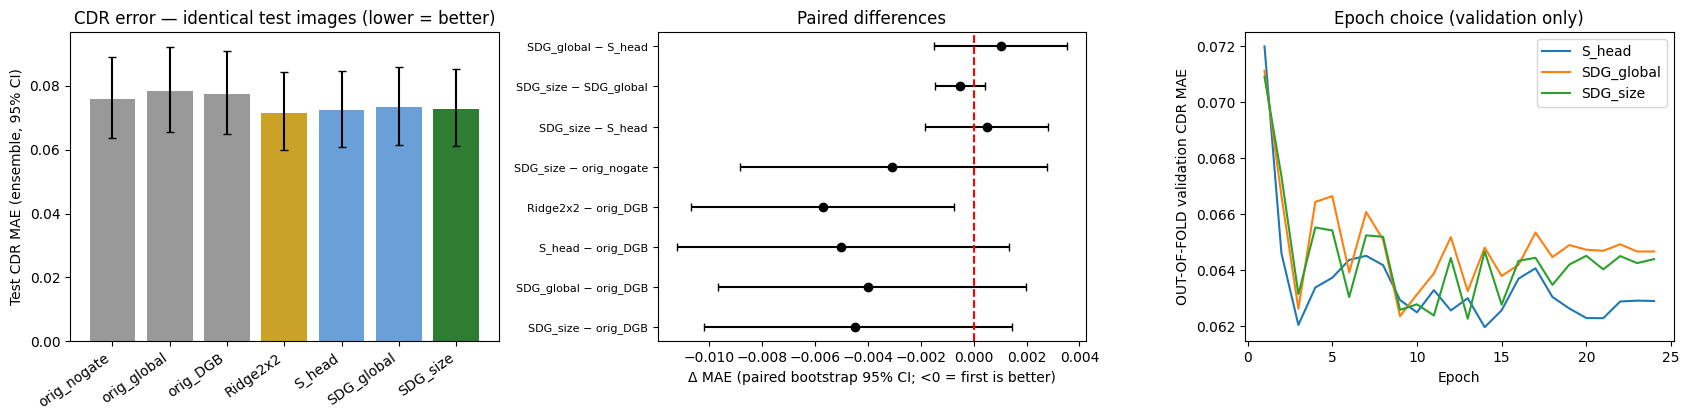

arm,SDG_global,SDG_size
D_mean,0.8789,0.8810
D_sd,0.0247,0.0275
frac_D_gt_0p95,0.0019,0.0066
frac_D_lt_0p05,0.0000,0.0000
MAE_real_gate,0.0758,0.0758
MAE_gate_set_to_1,0.0773,0.0771
MAE_gate_set_to_constant_mean,0.0757,0.0758


MAE_gate_set_to_1 > MAE_real_gate  => the learned gate removes harmful channels/locations (it is doing useful work).  MAE_gate_set_to_constant ≈ MAE_real_gate => it acts as a fixed rescaling only.


In [24]:
# ============================================================
# CELL S2-3 — Stage 2 v3 (3/4): train all arms (cross-fitted, cached, resumable), pick epochs on OUT-OF-FOLD validation, evaluate CDR on identical test images
#   Arms:  S_head (no gate) | SDG_global (gate, global healthy E) | SDG_size (gate, size-conditioned healthy E = PROPOSED)  + Ridge2x2 (closed-form reference)
#   Comparators from the earlier notebook: orig_nogate | orig_global | orig_DGB (the original Stage 2)
#   Expect roughly 10-20 min on a T4 for the 45 small networks (cached to disk: re-running the cell is instant).
# ============================================================
try: display
except NameError: display = print
ARMS = [('S_head', 'Spatial head, no gate'), ('SDG_global', 'Spatial deviation gate, global healthy E'), ('SDG_size', 'Spatial deviation gate, size-conditioned healthy E (proposed)')]
SEEDS3, KF, EMAX = CFG3['seeds'], CFG3['n_folds'], CFG3['epochs']
sm3 = lambda x: np.convolve(np.pad(x, (1, 1), mode='edge'), np.ones(3) / 3, mode='valid')          # 3-epoch moving average (curve smoothing for epoch choice)
lgt = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
sig = lambda z: 1 / (1 + np.exp(-z))

def fold_split(seed):
    return list(StratifiedKFold(KF, shuffle=True, random_state=seed).split(np.zeros(N_VA), y_va_i))

# ---------------- 1. train / load every (arm, seed, fold) ----------------
t0 = time.time(); V3 = {}
for arm, label in ARMS:
    oof = {k: np.full((len(SEEDS3), EMAX, N_VA), np.nan) for k in ('cdr', 'size', 'diag')}
    te = {k: np.zeros((len(SEEDS3), KF, EMAX, N_TE)) for k in ('cdr', 'size', 'diag')}
    for si, seed in enumerate(SEEDS3):
        for fi, (tr_i, ho_i) in enumerate(fold_split(seed)):
            r = run_cell(arm, seed, fi, tr_i, ho_i)
            for k in oof: oof[k][si][:, ho_i] = r['held_' + k]; te[k][si, fi] = r['te_' + k]
        print(f'  {arm:11s} seed {seed} done ({time.time()-t0:.0f}s elapsed)')
    assert not np.isnan(oof['cdr']).any(), 'out-of-fold predictions incomplete'
    # ---- epoch choice on OUT-OF-FOLD validation only (seed-ensemble curves, 3-epoch smoothing); CDR/size share an epoch, the diagnosis head has its own ----
    ens = {k: oof[k].mean(0) for k in oof}                                              # (E, N_VA)
    mae_curve = np.array([np.abs(ens['cdr'][e] - cdr_va_)[has_va_].mean() for e in range(EMAX)])
    ll_curve = np.array([log_loss(y_va_i, np.clip(sig(ens['diag'][e]), 1e-6, 1 - 1e-6)) for e in range(EMAX)])
    e_c, e_d = int(np.argmin(sm3(mae_curve))), int(np.argmin(sm3(ll_curve)))
    V3[arm] = dict(label=label, e_cdr=e_c + 1, e_diag=e_d + 1, mae_curve=mae_curve, ll_curve=ll_curve,
                   val_cdr=ens['cdr'][e_c], val_size=ens['size'][e_c], val_diag=ens['diag'][e_d],
                   te_cdr=te['cdr'].mean((0, 1))[e_c], te_size=te['size'].mean((0, 1))[e_c], te_diag=te['diag'].mean((0, 1))[e_d],
                   te_cdr_ind=te['cdr'][:, :, e_c].reshape(-1, N_TE))                      # (seeds*folds, N_TE) individual-model predictions
    print(f'{arm:11s}: chosen epoch CDR/size {e_c+1}, diagnosis {e_d+1} | OOF-val CDR MAE {mae_curve[e_c]:.4f} | OOF-val diagnosis log-loss {ll_curve[e_d]:.4f}')

# ---------------- 2. closed-form ridge reference (2x2 pooled spatial map), same cross-fit protocol, alpha chosen on OOF validation ----------------
Xtv = [pooled2x2(S_TR[:, v]) for v in range(K1)]; Xva2, Xte2 = pooled2x2(S_VA), pooled2x2(S_TE)
alphas = CFG3['ridge_alphas']; r_oof = {a: np.zeros(N_VA) for a in alphas}; r_te = {a: np.zeros(N_TE) for a in alphas}
for tr_i, ho_i in fold_split(0):
    vt = tr_i[has_va_[tr_i]]
    Xf = np.vstack([Xtv[v][has_tr_] for v in range(K1)] + [Xva2[vt]]); yf = np.concatenate([np.tile(cdr_tr_[has_tr_], K1), cdr_va_[vt]])
    wf = np.concatenate([np.ones(K1 * int(has_tr_.sum())), np.full(len(vt), CFG3['val_w'])])
    sc = StandardScaler().fit(Xf); Xs, Xh, Xt = sc.transform(Xf), sc.transform(Xva2[ho_i]), sc.transform(Xte2)
    for a in alphas:
        m = Ridge(alpha=a * K1).fit(Xs, yf, sample_weight=wf); r_oof[a][ho_i] = np.clip(m.predict(Xh), 0, 1); r_te[a] += np.clip(m.predict(Xt), 0, 1) / KF
a_best = min(alphas, key=lambda a: np.abs(r_oof[a] - cdr_va_)[has_va_].mean())
V3['Ridge2x2'] = dict(label='Ridge on 2x2-pooled map (reference)', val_cdr=r_oof[a_best], te_cdr=r_te[a_best], te_cdr_ind=r_te[a_best][None, :], alpha=a_best)
print(f'Ridge2x2: alpha {a_best:.3g} | OOF-val CDR MAE {np.abs(r_oof[a_best]-cdr_va_)[has_va_].mean():.4f}')

# ---------------- 3. CDR evaluation on IDENTICAL test images (original Stage 2 vs v3) ----------------
OLD = {'orig_nogate': 'nogate', 'orig_global': 'global', 'orig_DGB': 'conditioned'}
METH = {}                                                                                    # name -> dict(ens=(n_te,), ind=(n_models,n_te), val_mae)
for nm, k in OLD.items():
    METH[nm] = dict(ens=ORIG[k]['test'].mean(0), ind=ORIG[k]['test'], val_mae=float(np.abs(ORIG[k]['val'].mean(0) - cdr_va_)[has_va_].mean()), label=nm)
for arm in ['Ridge2x2'] + [a for a, _ in ARMS]:
    METH[arm] = dict(ens=V3[arm]['te_cdr'], ind=V3[arm]['te_cdr_ind'], val_mae=float(np.abs(V3[arm]['val_cdr'] - cdr_va_)[has_va_].mean()), label=arm)
yc = cdr_te_[has_te_]
rows = []
for nm, d in METH.items():
    em = reg_metrics(d['ens'][has_te_], yc); ind = [reg_metrics(p[has_te_], yc) for p in d['ind']]
    rows.append(dict(method=nm, test_MAE_ens=em['mae'], test_RMSE_ens=em['rmse'], test_R2_ens=em['r2'], test_Pearson_ens=em['pearson'], test_Spearman_ens=em['spearman'],
                     test_MAE_individual=np.mean([i['mae'] for i in ind]), test_MAE_ind_sd=np.std([i['mae'] for i in ind], ddof=1) if len(ind) > 1 else np.nan,
                     val_MAE=d['val_mae'], note='val = original in-sample selection' if nm.startswith('orig') else 'val = OUT-OF-FOLD'))
cdr3 = pd.DataFrame(rows).set_index('method'); display(cdr3.round(4)); cdr3.to_csv(f'{TAB_DIR}/v3_cdr_regression_all_methods.csv')
print(f'All test numbers: the same {int(has_te_.sum())} CDR-labelled test images. "_ens" = seed(/fold)-ensemble prediction; "_individual" = mean over single models (like the old table).')

def pd_boot(ea, eb, B=None, seed=0):                                                         # paired bootstrap of mean(ea − eb) over test images
    B = B or CFG3['n_boot']; d = np.asarray(ea) - np.asarray(eb); n = len(d); rng = np.random.default_rng(seed)
    bs = d[rng.integers(0, n, (B, n))].mean(1)
    try: wp = float(stats.wilcoxon(d).pvalue)
    except ValueError: wp = 1.0
    return dict(delta=float(d.mean()), lo=float(np.percentile(bs, 2.5)), hi=float(np.percentile(bs, 97.5)), wilcoxon_p=wp)
def holm_adj(p):
    p = np.asarray(p, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(o): run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj
err_ens = {nm: np.abs(d['ens'][has_te_] - yc) for nm, d in METH.items()}
err_ind = {nm: np.abs(d['ind'][:, has_te_] - yc).mean(0) for nm, d in METH.items()}
PAIRS = [('SDG_size', 'orig_DGB'), ('SDG_global', 'orig_DGB'), ('S_head', 'orig_DGB'), ('Ridge2x2', 'orig_DGB'), ('SDG_size', 'orig_nogate'),
         ('SDG_size', 'S_head'), ('SDG_size', 'SDG_global'), ('SDG_global', 'S_head')]
pr = []
for a, b in PAIRS:
    for kind, E_ in (('ensemble', err_ens), ('individual models', err_ind)):
        r = pd_boot(E_[a], E_[b]); pr.append(dict(comparison=f'{a} − {b}', kind=kind, delta_MAE=r['delta'], ci_lo=r['lo'], ci_hi=r['hi'], wilcoxon_p=r['wilcoxon_p']))
paired3 = pd.DataFrame(pr)
for kind in paired3.kind.unique():                                                           # Holm over the 'vs original DGB' family and over the ablation family, per kind
    for fam in (paired3.comparison.str.endswith('orig_DGB'), ~paired3.comparison.str.endswith('orig_DGB')):
        ix = paired3.index[(paired3.kind == kind) & fam]; paired3.loc[ix, 'p_holm'] = holm_adj(paired3.loc[ix, 'wilcoxon_p'].values)
display(paired3.round(5)); paired3.to_csv(f'{TAB_DIR}/v3_cdr_paired_deltas.csv', index=False)
print('Negative delta_MAE = first method is better. A CI entirely below 0 = significant improvement on these test images.')

def verdict3(r, margin=0.005):
    if r['ci_hi'] < 0: return 'BETTER (95% CI < 0)'
    if r['ci_lo'] > 0: return 'WORSE (95% CI > 0)'
    if r['ci_lo'] > -margin and r['ci_hi'] < margin: return f'EQUIVALENT (±{margin})'
    return 'INCONCLUSIVE'
PAIRED_CDR = {(r.comparison, r.kind): r for r in paired3.itertuples()}

# ---------------- 4. subgroup MAE, severity staging, figures ----------------
sub = {'normal': has_te_ & (y_te_i == 0), 'glaucoma': has_te_ & (y_te_i == 1), **{f'{n} disc': has_te_ & (bk_te_ == i) for i, n in enumerate(BUCKET_NAMES)}}
sub_tab = pd.DataFrame({nm: {c: np.abs(d['ens'][m] - cdr_te_[m]).mean() for c, m in sub.items()} for nm, d in METH.items()}).T
sub_tab.columns = [f'{c} (n={int(sub[c].sum())})' for c in sub_tab.columns]; display(sub_tab.round(4)); sub_tab.to_csv(f'{TAB_DIR}/v3_cdr_subgroups.csv')
gm = has_te_ & (y_te_i == 1); st_true = sev_stage(cdr_te_[gm]); sev_rows = {}
for nm in ('orig_DGB', 'S_head', 'SDG_size'):
    sp = sev_stage(METH[nm]['ens'][gm])
    sev_rows[nm] = dict(n=int(gm.sum()), accuracy=float((st_true == sp).mean()), f1_macro=float(f1_score(st_true, sp, average='macro', labels=[0, 1, 2], zero_division=0)),
                        quadratic_kappa=float(cohen_kappa_score(st_true, sp, weights='quadratic')))
sev3 = pd.DataFrame(sev_rows).T; display(sev3.round(4)); sev3.to_csv(f'{TAB_DIR}/v3_severity_staging.csv')

fig, axs = plt.subplots(1, 3, figsize=(17, 4.3)); names = list(METH)
rngb = np.random.default_rng(1); bi = rngb.integers(0, len(yc), (2000, len(yc)))
mu_ = [err_ens[n].mean() for n in names]; ci_ = np.array([np.percentile(err_ens[n][bi].mean(1), [2.5, 97.5]) for n in names])
axs[0].bar(range(len(names)), mu_, yerr=[np.array(mu_) - ci_[:, 0], ci_[:, 1] - np.array(mu_)], capsize=3, color=['#999'] * 3 + ['#c9a227'] + ['#6a9fd8', '#6a9fd8', '#2e7d32'])
axs[0].set_xticks(range(len(names))); axs[0].set_xticklabels(names, rotation=35, ha='right'); axs[0].set_ylabel('Test CDR MAE (ensemble, 95% CI)'); axs[0].set_title('CDR error — identical test images (lower = better)')
pp = paired3[paired3.kind == 'ensemble'].reset_index(drop=True)
axs[1].errorbar(pp.delta_MAE, range(len(pp)), xerr=[pp.delta_MAE - pp.ci_lo, pp.ci_hi - pp.delta_MAE], fmt='o', c='k', capsize=3); axs[1].axvline(0, c='r', ls='--')
axs[1].set_yticks(range(len(pp))); axs[1].set_yticklabels(pp.comparison, fontsize=8); axs[1].set_xlabel('Δ MAE (paired bootstrap 95% CI; <0 = first is better)'); axs[1].set_title('Paired differences')
for arm, _ in ARMS: axs[2].plot(np.arange(1, EMAX + 1), V3[arm]['mae_curve'], label=arm)
axs[2].set(xlabel='Epoch', ylabel='OUT-OF-FOLD validation CDR MAE', title='Epoch choice (validation only)'); axs[2].legend(); savefig('v3_stage2_cdr_comparison.png')

# ---------------- 5. what does the gate do? (final-epoch model of seed 0 / fold 0, test images with CDR labels) ----------------
try:
    gt = []
    for arm in ('SDG_global', 'SDG_size'):
        r = torch.load(f"{CFG3['dir']}/{arm}_s{SEEDS3[0]}_f0.pt", map_location='cpu', weights_only=False)
        net = DevGateNet(arm, NC, SH, SW, CFG3['R'], CFG3['hid'], CFG3['gate_hid'], CFG3['drop']).to(DEVICE); net.load_state_dict(r['state']); net.eval()
        ref = REFS[arm]; tm = torch.as_tensor(has_te_, device=DEVICE)
        with torch.no_grad():
            c_real, _, _, D = net(S_TE_D.float(), ref)
            Dbar = D.mean((0, 2, 3), keepdim=True)
            net.override = 'ones'; c_ones = net(S_TE_D.float(), ref)[0]
            net.override = Dbar; c_const = net(S_TE_D.float(), ref)[0]
        f_ = lambda c: float(np.abs(c.cpu().numpy()[has_te_] - yc).mean())
        gt.append(dict(arm=arm, D_mean=float(D.mean()), D_sd=float(D.std()), frac_D_gt_0p95=float((D > .95).float().mean()), frac_D_lt_0p05=float((D < .05).float().mean()),
                       MAE_real_gate=f_(c_real), MAE_gate_set_to_1=f_(c_ones), MAE_gate_set_to_constant_mean=f_(c_const)))
    gate_tab = pd.DataFrame(gt).set_index('arm').T; display(gate_tab.round(4)); gate_tab.to_csv(f'{TAB_DIR}/v3_gate_diagnostics.csv')
    print('MAE_gate_set_to_1 > MAE_real_gate  => the learned gate removes harmful channels/locations (it is doing useful work).  MAE_gate_set_to_constant ≈ MAE_real_gate => it acts as a fixed rescaling only.')
except Exception as ex:
    print('Gate diagnostics skipped:', repr(ex))

S1 recalibrated (identity)                 C=3     thr=0.660 OOF-val logloss 0.2849 | standardised coefs {'s1': np.float64(2.783)}
+ CDR                                      C=3     thr=0.605 OOF-val logloss 0.2865 | standardised coefs {'s1': np.float64(2.605), 'cdr': np.float64(0.212)}
+ CDR + deviation-evidence                 C=1     thr=0.640 OOF-val logloss 0.2840 | standardised coefs {'s1': np.float64(1.482), 'cdr': np.float64(0.142), 'dg': np.float64(1.259)}
FULL verifier (+ normative deviation)      C=1     thr=0.620 OOF-val logloss 0.2833 | standardised coefs {'s1': np.float64(1.672), 'cdr': np.float64(0.064), 'dg': np.float64(1.421), 'dev': np.float64(-0.341)}


,accuracy,balanced_accuracy,sensitivity,specificity,precision_glaucoma,f1_macro,auc,auprc,mcc,brier,ece,tn,fp,fn,tp
Stage 1 alone (thr 0.5),84.2222,84.2222,87.1111,81.3333,82.3529,0.8421,0.9331,0.9367,0.6856,0.1086,0.0573,183.0,42.0,29.0,196.0
Old Stage 2 (AND-rule on original DGB),83.5556,83.5556,84.0000,83.1111,83.2599,0.8356,NaN,NaN,0.6711,NaN,NaN,187.0,38.0,36.0,189.0
S1 recalibrated (identity),83.3333,83.3333,77.7778,88.8889,87.5000,0.8328,0.9331,0.9367,0.6708,0.1093,0.0406,200.0,25.0,50.0,175.0
+ CDR,83.7778,83.7778,79.1111,88.4444,87.2549,0.8374,0.9313,0.9295,0.6785,0.1106,0.0515,199.0,26.0,47.0,178.0
+ CDR + deviation-evidence,83.7778,83.7778,77.7778,89.7778,88.3838,0.8372,0.9310,0.9329,0.6805,0.1104,0.0475,202.0,23.0,50.0,175.0
FULL verifier (+ normative deviation),84.0000,84.0000,78.6667,89.3333,88.0597,0.8395,0.9300,0.9303,0.6839,0.1100,0.0453,201.0,24.0,48.0,177.0


Old-rule tau (val-tuned) = 0.45. Thresholds of the v3 rows come from OUT-OF-FOLD validation scores; probabilities of the v3 rows are validation-calibrated.


,method,versus,d_acc,d_acc_lo,d_acc_hi,d_sens,d_sens_lo,d_sens_hi,d_spec,d_spec_lo,d_spec_hi,fixed_errors,new_errors,mcnemar_p,d_auroc,d_auroc_lo,d_auroc_hi
0,S1 recalibrated (identity),Stage 1 alone (thr 0.5),-0.0087,-0.0356,0.0178,-0.0931,-0.1331,-0.0563,0.0753,0.0420,0.1120,17,21,0.6271,0.0000,0.0000,0.0000
1,S1 recalibrated (identity),Old Stage 2 (AND-rule on original DGB),-0.0021,-0.0289,0.0245,-0.0620,-0.1050,-0.0190,0.0577,0.0265,0.0917,19,20,1.0000,NaN,NaN,NaN
2,+ CDR,Stage 1 alone (thr 0.5),-0.0042,-0.0289,0.0200,-0.0797,-0.1174,-0.0460,0.0710,0.0381,0.1065,16,18,0.8642,-0.0018,-0.0055,0.0014
3,+ CDR,Old Stage 2 (AND-rule on original DGB),0.0025,-0.0244,0.0289,-0.0486,-0.0891,-0.0089,0.0534,0.0225,0.0866,18,17,1.0000,NaN,NaN,NaN
4,+ CDR,S1 recalibrated (identity),0.0045,-0.0044,0.0133,0.0134,0.0000,0.0306,-0.0043,-0.0141,0.0000,3,1,0.6250,-0.0018,-0.0055,0.0014
5,+ CDR + deviation-evidence,Stage 1 alone (thr 0.5),-0.0044,-0.0311,0.0222,-0.0933,-0.1339,-0.0565,0.0842,0.0491,0.1215,19,21,0.8746,-0.0021,-0.0059,0.0015
6,+ CDR + deviation-evidence,Old Stage 2 (AND-rule on original DGB),0.0023,-0.0267,0.0311,-0.0622,-0.1055,-0.0210,0.0666,0.0335,0.1020,21,20,1.0000,NaN,NaN,NaN
7,+ CDR + deviation-evidence,S1 recalibrated (identity),0.0043,-0.0044,0.0133,-0.0002,-0.0132,0.0132,0.0089,0.0000,0.0227,3,1,0.6250,-0.0021,-0.0059,0.0015
8,FULL verifier (+ normative deviation),Stage 1 alone (thr 0.5),-0.0020,-0.0289,0.0244,-0.0841,-0.1222,-0.0494,0.0798,0.0459,0.1166,18,19,1.0000,-0.0032,-0.0079,0.0014
9,FULL verifier (+ normative deviation),Old Stage 2 (AND-rule on original DGB),0.0047,-0.0222,0.0311,-0.0531,-0.0946,-0.0132,0.0622,0.0300,0.0971,20,18,0.8714,NaN,NaN,NaN


d_* = method − versus (paired bootstrap on the same test images, 95% CI). fixed_errors = cases the method gets right and `versus` gets wrong; new_errors = the reverse.


,coverage,n_review,acc_retained,err_rate_flagged,err_rate_retained,sens_retained,spec_retained
Stage 1 + confidence-based review,0.8222,80.0,0.8973,0.4125,0.1027,0.9259,0.8674
v3 verifier + review band,0.8600,63.0,0.8889,0.4603,0.1111,0.8394,0.9381
Stage 1 alone (no review),1.0000,0.0,0.8422,NaN,0.1578,0.8711,0.8133
v3 verifier (no review),1.0000,0.0,0.8400,NaN,0.1600,0.7867,0.8933


Selective accuracy of RETAINED cases at ~15% review: v3 − Stage-1-confidence = -0.79 pts  95% CI [-3.35, +1.75]
AURC (risk-coverage area, lower = better): v3 0.0535 vs Stage-1 confidence 0.0463 | Δ +0.0070 [-0.0049, +0.0206]


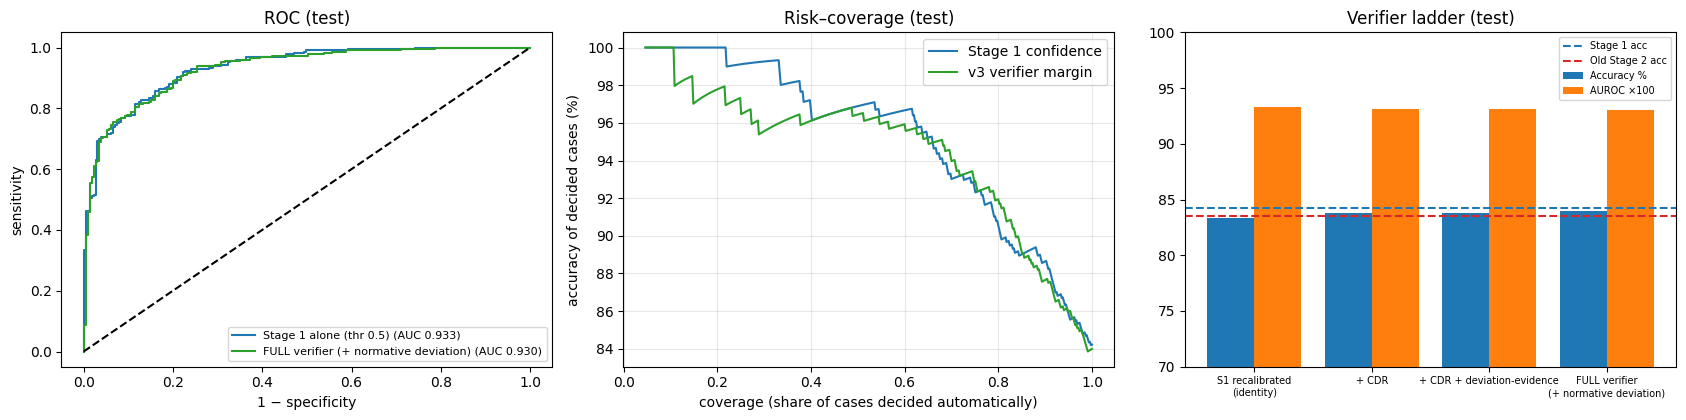


STAGE-2 v3 SCORECARD (all numbers computed from the predictions above; identical test images; 95% paired-bootstrap CIs)
1. CDR error, proposed v3 vs ORIGINAL Stage 2 (MAE 0.0728 vs 0.0773): ensemble ΔMAE -0.0045 [-0.0102,+0.0015] -> INCONCLUSIVE; individual-models ΔMAE -0.0014 [-0.0069,+0.0044] -> INCONCLUSIVE
   R² 0.427 -> 0.492 | Pearson 0.656 -> 0.702 | severity QWK 0.533 -> 0.410
2. Does the GATE help CDR (SDG_size vs same network without gate)? ΔMAE +0.0005 [-0.0019,+0.0028] -> EQUIVALENT (±0.005)
   Does size-CONDITIONING help (vs global E)? ΔMAE -0.0005 [-0.0015,+0.0004] -> EQUIVALENT (±0.005)
3. Verification vs ORIGINAL Stage 2 pipeline: Δacc +0.47 pts [-2.22,+3.11] (not significant) | Δsens -5.31 [-9.46,-1.32] (significant LOSS) | Δspec +6.22 [+3.00,+9.71] (SIGNIFICANT GAIN)
4. Verification vs Stage 1 alone: Δacc -0.20 pts [-2.89,+2.44] (not significant) | ΔAUROC -0.0032 [-0.0079,+0.0014] (not significant) | errors fixed 18 vs introduced 19 (McNemar p=1.000)
5. Value of Stag

In [25]:
# ============================================================
# CELL S2-4 — Stage 2 v3 (4/4): the VERIFICATION module — two-sided evidence fusion, review band, selective prediction, paired tests, scorecard
#   Stage 1 says "glaucoma / not"; Stage 2 compares that claim with independent anatomical evidence and
#   (a) confirms, (b) overturns a false alarm, (c) rescues a miss, or (d) sends the case to REVIEW.
#   Everything is fitted on VALIDATION (out-of-fold Stage-2 outputs); the test set is only read out.
# ============================================================
try: display
except NameError: display = print
from scipy.stats import rankdata
PRIMARY_ARM = 'SDG_size'                                      # fixed in advance (the proposed gate), not cherry-picked
EV_VA = dict(s1=lgt(p_val), cdr=V3[PRIMARY_ARM]['val_cdr'], dg=V3[PRIMARY_ARM]['val_diag'], dev=DEV_VA)
EV_TE = dict(s1=lgt(p_te),  cdr=V3[PRIMARY_ARM]['te_cdr'],  dg=V3[PRIMARY_ARM]['te_diag'],  dev=DEV_TE)
LADDER = {'S1 recalibrated (identity)': ['s1'], '+ CDR': ['s1', 'cdr'], '+ CDR + deviation-evidence': ['s1', 'cdr', 'dg'],
          'FULL verifier (+ normative deviation)': ['s1', 'cdr', 'dg', 'dev']}
FULL = 'FULL verifier (+ normative deviation)'; IDENT = 'S1 recalibrated (identity)'

def best_thr(y, p):                                           # balanced-accuracy-optimal threshold on out-of-fold validation scores; ties -> closest to 0.5
    ths = np.arange(0.05, 0.951, 0.005); ba = np.array([balanced_accuracy_score(y, (p >= t).astype(int)) for t in ths])
    c = ths[ba >= ba.max() - 1e-12]; return float(c[np.argmin(np.abs(c - 0.5))])

def fit_verifier(cols, Cgrid=(0.01, 0.03, 0.1, 0.3, 1, 3, 10), reps=5):
    Xv = np.column_stack([EV_VA[c] for c in cols]); Xt = np.column_stack([EV_TE[c] for c in cols]); best = None
    for C in Cgrid:
        oofs = []
        for r in range(reps):
            o = np.zeros(len(y_va_i))
            for tr_i, te_i in StratifiedKFold(5, shuffle=True, random_state=100 + r).split(Xv, y_va_i):
                sc = StandardScaler().fit(Xv[tr_i]); m = LogisticRegression(C=C, max_iter=2000).fit(sc.transform(Xv[tr_i]), y_va_i[tr_i])
                o[te_i] = m.predict_proba(sc.transform(Xv[te_i]))[:, 1]
            oofs.append(o)
        o = np.mean(oofs, 0); ll = log_loss(y_va_i, np.clip(o, 1e-6, 1 - 1e-6))
        if best is None or ll < best[0] - 1e-9: best = (ll, C, o)
    ll, C, oof = best; sc = StandardScaler().fit(Xv); m = LogisticRegression(C=C, max_iter=2000).fit(sc.transform(Xv), y_va_i)
    return dict(cols=cols, C=C, oof_val=oof, p_te=m.predict_proba(sc.transform(Xt))[:, 1], thr=best_thr(y_va_i, oof), val_oof_logloss=ll,
                coef=dict(zip(cols, m.coef_[0].round(3))))
VER = {nm: fit_verifier(cols) for nm, cols in LADDER.items()}
for nm, v in VER.items(): print(f'{nm:42s} C={v["C"]:<5} thr={v["thr"]:.3f} OOF-val logloss {v["val_oof_logloss"]:.4f} | standardised coefs {v["coef"]}')

# ---------------- Stage 1, original Stage 2 (AND-rule on the original DGB) and the v3 rows on the SAME 450 test images ----------------
s1_pred = (p_te >= .5).astype(int)
c_val_old, c_te_old = ORIG['conditioned']['val'][0], ORIG['conditioned']['test'][0]; TAU_OLD = tune_tau(p_val, c_val_old, y_val)
pipe_old = ((p_te >= .5) & (c_te_old >= TAU_OLD)).astype(int)
PRED = {'Stage 1 alone (thr 0.5)': s1_pred, 'Old Stage 2 (AND-rule on original DGB)': pipe_old}
SCORE = {'Stage 1 alone (thr 0.5)': p_te}
for nm, v in VER.items(): PRED[nm] = (v['p_te'] >= v['thr']).astype(int); SCORE[nm] = v['p_te']
CORR = {nm: (pr == y_te_i).astype(float) for nm, pr in PRED.items()}

ROWS_V3 = {}
for nm, pr in PRED.items():
    m = clf_metrics(y_te_i, SCORE.get(nm), pred=None if nm in SCORE else pr, thr=VER[nm]['thr'] if nm in VER else 0.5)
    if nm == 'Old Stage 2 (AND-rule on original DGB)': m = clf_metrics(y_te_i, None, pred=pr)
    ROWS_V3[nm] = m
ver_tab = metrics_table(ROWS_V3)[['accuracy', 'balanced_accuracy', 'sensitivity', 'specificity', 'precision_glaucoma', 'f1_macro', 'auc', 'auprc', 'mcc', 'brier', 'ece', 'tn', 'fp', 'fn', 'tp']].round(4)
display(ver_tab); ver_tab.to_csv(f'{TAB_DIR}/v3_verification_metrics.csv')
print(f'Old-rule tau (val-tuned) = {TAU_OLD:.2f}. Thresholds of the v3 rows come from OUT-OF-FOLD validation scores; probabilities of the v3 rows are validation-calibrated.')

# ---------------- paired bootstrap on test images ----------------
def auc_fast(y, s):
    r = rankdata(s); n1 = int(y.sum()); n0 = len(y) - n1; return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
B = CFG3['n_boot']; rngv = np.random.default_rng(0); BI = rngv.integers(0, len(y_te_i), (B, len(y_te_i))); BIA = BI[:2000]
def ci(d): return float(np.mean(d)), float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))
def d_rate(a, b, cls):                                        # difference in sensitivity (cls=1) / specificity (cls=0) of two decision vectors
    m = (y_te_i == cls); ca, cb = (PRED[a] == cls).astype(float), (PRED[b] == cls).astype(float)
    out = []
    for ix in BI:
        k = ix[m[ix]]; out.append(ca[k].mean() - cb[k].mean())
    return ci(out)
def d_auc(sa, sb):
    out = []
    for ix in BIA:
        if len(np.unique(y_te_i[ix])) < 2: continue
        out.append(auc_fast(y_te_i[ix], sa[ix]) - auc_fast(y_te_i[ix], sb[ix]))
    return ci(out)
def mcnemar(a, b):
    fix, brk = int(((CORR[a] == 1) & (CORR[b] == 0)).sum()), int(((CORR[a] == 0) & (CORR[b] == 1)).sum())
    return fix, brk, (stats.binomtest(min(fix, brk), fix + brk, 0.5).pvalue if fix + brk else 1.0)
S1N, OLDN = 'Stage 1 alone (thr 0.5)', 'Old Stage 2 (AND-rule on original DGB)'
cmp_rows = []
for nm in list(LADDER) + [OLDN]:
    for ref in ([S1N, OLDN] if nm != OLDN else [S1N]) + ([IDENT] if nm in LADDER and nm != IDENT else []):
        da = ci(CORR[nm][BI].mean(1) - CORR[ref][BI].mean(1)); ds, dp = d_rate(nm, ref, 1), d_rate(nm, ref, 0); fx, bk, mp = mcnemar(nm, ref)
        row = dict(method=nm, versus=ref, d_acc=da[0], d_acc_lo=da[1], d_acc_hi=da[2], d_sens=ds[0], d_sens_lo=ds[1], d_sens_hi=ds[2], d_spec=dp[0], d_spec_lo=dp[1], d_spec_hi=dp[2],
                   fixed_errors=fx, new_errors=bk, mcnemar_p=mp)
        if nm in SCORE and ref in SCORE: a_ = d_auc(SCORE[nm], SCORE[ref]); row.update(d_auroc=a_[0], d_auroc_lo=a_[1], d_auroc_hi=a_[2])
        elif nm in VER and ref == IDENT: a_ = d_auc(VER[nm]['p_te'], VER[IDENT]['p_te']); row.update(d_auroc=a_[0], d_auroc_lo=a_[1], d_auroc_hi=a_[2])
        cmp_rows.append(row)
cmp3 = pd.DataFrame(cmp_rows); display(cmp3.round(4)); cmp3.to_csv(f'{TAB_DIR}/v3_verification_paired_tests.csv', index=False)
print('d_* = method − versus (paired bootstrap on the same test images, 95% CI). fixed_errors = cases the method gets right and `versus` gets wrong; new_errors = the reverse.')

# ---------------- review band + selective prediction ----------------
fv = VER[FULL]; mg_va = np.abs(lgt(fv['oof_val']) - lgt(fv['thr'])); mg_te = np.abs(lgt(fv['p_te']) - lgt(fv['thr']))
MC = float(np.quantile(mg_va, CFG3['review_frac'])); review_te = mg_te < MC                                # cut-off fixed on VALIDATION
mg1_va, mg1_te = np.abs(lgt(p_val)), np.abs(lgt(p_te)); MC1 = float(np.quantile(mg1_va, CFG3['review_frac'])); review1_te = mg1_te < MC1
def sel(corr, flag, y=y_te_i, pred=None):
    k = ~flag; r = dict(coverage=float(k.mean()), n_review=int(flag.sum()), acc_retained=float(corr[k].mean()), err_rate_flagged=float(1 - corr[flag].mean()) if flag.any() else np.nan,
                        err_rate_retained=float(1 - corr[k].mean()))
    if pred is not None: r.update(sens_retained=float((pred[k][y[k] == 1] == 1).mean()), spec_retained=float((pred[k][y[k] == 0] == 0).mean()))
    return r
sel_rows = {'Stage 1 + confidence-based review': sel(CORR[S1N], review1_te, pred=s1_pred), 'v3 verifier + review band': sel(CORR[FULL], review_te, pred=PRED[FULL]),
            'Stage 1 alone (no review)': sel(CORR[S1N], np.zeros(N_TE, bool), pred=s1_pred), 'v3 verifier (no review)': sel(CORR[FULL], np.zeros(N_TE, bool), pred=PRED[FULL])}
sel_tab = pd.DataFrame(sel_rows).T; display(sel_tab.round(4)); sel_tab.to_csv(f'{TAB_DIR}/v3_selective_prediction.csv')
d_sel = []
for ix in BI[:2000]:
    a = CORR[FULL][ix][~review_te[ix]].mean() if (~review_te[ix]).any() else np.nan; b = CORR[S1N][ix][~review1_te[ix]].mean() if (~review1_te[ix]).any() else np.nan; d_sel.append(a - b)
d_sel = np.array(d_sel); d_sel = d_sel[~np.isnan(d_sel)]
def aurc(corr, conf):
    o = np.argsort(-conf, kind='stable'); err = 1 - corr[o]; return float((np.cumsum(err) / np.arange(1, len(err) + 1)).mean())
d_aurc = np.array([aurc(CORR[FULL][ix], mg_te[ix]) - aurc(CORR[S1N][ix], mg1_te[ix]) for ix in BI[:2000]])
print(f'Selective accuracy of RETAINED cases at ~{CFG3["review_frac"]*100:.0f}% review: v3 − Stage-1-confidence = {d_sel.mean()*100:+.2f} pts  95% CI [{np.percentile(d_sel,2.5)*100:+.2f}, {np.percentile(d_sel,97.5)*100:+.2f}]')
print(f'AURC (risk-coverage area, lower = better): v3 {aurc(CORR[FULL], mg_te):.4f} vs Stage-1 confidence {aurc(CORR[S1N], mg1_te):.4f} | Δ {d_aurc.mean():+.4f} [{np.percentile(d_aurc,2.5):+.4f}, {np.percentile(d_aurc,97.5):+.4f}]')

fig, axs = plt.subplots(1, 3, figsize=(17, 4.3))
for nm, c in [(S1N, 'tab:blue'), (FULL, 'tab:green')]:
    s_ = SCORE[nm]; f_, t_, _ = roc_curve(y_te_i, s_); axs[0].plot(f_, t_, c=c, label=f'{nm} (AUC {roc_auc_score(y_te_i, s_):.3f})')
axs[0].plot([0, 1], [0, 1], 'k--'); axs[0].set(xlabel='1 − specificity', ylabel='sensitivity', title='ROC (test)'); axs[0].legend(fontsize=8)
for nm, mg, c in [('Stage 1 confidence', mg1_te, 'tab:blue'), ('v3 verifier margin', mg_te, 'tab:green')]:
    corr = CORR[S1N] if nm.startswith('Stage') else CORR[FULL]; o = np.argsort(-mg, kind='stable'); cov = np.arange(1, N_TE + 1) / N_TE
    axs[1].plot(cov[20:], (np.cumsum(corr[o]) / np.arange(1, N_TE + 1))[20:] * 100, c=c, label=nm)
axs[1].set(xlabel='coverage (share of cases decided automatically)', ylabel='accuracy of decided cases (%)', title='Risk–coverage (test)'); axs[1].legend(); axs[1].grid(alpha=.3)
ladder_names = list(LADDER); ac = [CORR[n].mean() * 100 for n in ladder_names]; aucs = [roc_auc_score(y_te_i, VER[n]['p_te']) * 100 for n in ladder_names]
xs = np.arange(len(ladder_names)); axs[2].bar(xs - .2, ac, .4, label='Accuracy %'); axs[2].bar(xs + .2, aucs, .4, label='AUROC ×100'); axs[2].axhline(CORR[S1N].mean() * 100, c='tab:blue', ls='--', label='Stage 1 acc')
axs[2].axhline(CORR[OLDN].mean() * 100, c='tab:red', ls='--', label='Old Stage 2 acc'); axs[2].set_ylim(70, 100); axs[2].set_xticks(xs); axs[2].set_xticklabels([n.replace(' (', '\n(') for n in ladder_names], fontsize=7); axs[2].legend(fontsize=7); axs[2].set_title('Verifier ladder (test)')
savefig('v3_verification_summary.png')

# ---------------- automatic scorecard (computed, never typed) ----------------
def vd(lo, hi): return 'SIGNIFICANT GAIN' if lo > 0 else ('significant LOSS' if hi < 0 else 'not significant')
def getc(m, v): return cmp3[(cmp3.method == m) & (cmp3.versus == v)].iloc[0]
print('\n' + '=' * 92 + '\nSTAGE-2 v3 SCORECARD (all numbers computed from the predictions above; identical test images; 95% paired-bootstrap CIs)\n' + '=' * 92)
r = PAIRED_CDR[('SDG_size − orig_DGB', 'ensemble')]; r2 = PAIRED_CDR[('SDG_size − orig_DGB', 'individual models')]
print(f"1. CDR error, proposed v3 vs ORIGINAL Stage 2 (MAE {err_ens['SDG_size'].mean():.4f} vs {err_ens['orig_DGB'].mean():.4f}): ensemble ΔMAE {r.delta_MAE:+.4f} [{r.ci_lo:+.4f},{r.ci_hi:+.4f}] -> {verdict3(dict(ci_lo=r.ci_lo, ci_hi=r.ci_hi))}; "
      f"individual-models ΔMAE {r2.delta_MAE:+.4f} [{r2.ci_lo:+.4f},{r2.ci_hi:+.4f}] -> {verdict3(dict(ci_lo=r2.ci_lo, ci_hi=r2.ci_hi))}")
print(f"   R² {cdr3.loc['orig_DGB','test_R2_ens']:.3f} -> {cdr3.loc['SDG_size','test_R2_ens']:.3f} | Pearson {cdr3.loc['orig_DGB','test_Pearson_ens']:.3f} -> {cdr3.loc['SDG_size','test_Pearson_ens']:.3f} | severity QWK {sev3.loc['orig_DGB','quadratic_kappa']:.3f} -> {sev3.loc['SDG_size','quadratic_kappa']:.3f}")
g1, g2 = PAIRED_CDR[('SDG_size − S_head', 'ensemble')], PAIRED_CDR[('SDG_size − SDG_global', 'ensemble')]
print(f"2. Does the GATE help CDR (SDG_size vs same network without gate)? ΔMAE {g1.delta_MAE:+.4f} [{g1.ci_lo:+.4f},{g1.ci_hi:+.4f}] -> {verdict3(dict(ci_lo=g1.ci_lo, ci_hi=g1.ci_hi))}")
print(f"   Does size-CONDITIONING help (vs global E)? ΔMAE {g2.delta_MAE:+.4f} [{g2.ci_lo:+.4f},{g2.ci_hi:+.4f}] -> {verdict3(dict(ci_lo=g2.ci_lo, ci_hi=g2.ci_hi))}")
c_old, c_s1, c_id = getc(FULL, OLDN), getc(FULL, S1N), getc(FULL, IDENT)
print(f"3. Verification vs ORIGINAL Stage 2 pipeline: Δacc {c_old.d_acc*100:+.2f} pts [{c_old.d_acc_lo*100:+.2f},{c_old.d_acc_hi*100:+.2f}] ({vd(c_old.d_acc_lo, c_old.d_acc_hi)}) | Δsens {c_old.d_sens*100:+.2f} [{c_old.d_sens_lo*100:+.2f},{c_old.d_sens_hi*100:+.2f}] ({vd(c_old.d_sens_lo, c_old.d_sens_hi)}) | Δspec {c_old.d_spec*100:+.2f} [{c_old.d_spec_lo*100:+.2f},{c_old.d_spec_hi*100:+.2f}] ({vd(c_old.d_spec_lo, c_old.d_spec_hi)})")
print(f"4. Verification vs Stage 1 alone: Δacc {c_s1.d_acc*100:+.2f} pts [{c_s1.d_acc_lo*100:+.2f},{c_s1.d_acc_hi*100:+.2f}] ({vd(c_s1.d_acc_lo, c_s1.d_acc_hi)}) | ΔAUROC {c_s1.d_auroc:+.4f} [{c_s1.d_auroc_lo:+.4f},{c_s1.d_auroc_hi:+.4f}] ({vd(c_s1.d_auroc_lo, c_s1.d_auroc_hi)}) | errors fixed {int(c_s1.fixed_errors)} vs introduced {int(c_s1.new_errors)} (McNemar p={c_s1.mcnemar_p:.3f})")
print(f"5. Value of Stage-2 evidence beyond mere RE-CALIBRATION of Stage 1 (FULL vs identity): Δacc {c_id.d_acc*100:+.2f} pts [{c_id.d_acc_lo*100:+.2f},{c_id.d_acc_hi*100:+.2f}] ({vd(c_id.d_acc_lo, c_id.d_acc_hi)}) | ΔAUROC {c_id.d_auroc:+.4f} [{c_id.d_auroc_lo:+.4f},{c_id.d_auroc_hi:+.4f}] ({vd(c_id.d_auroc_lo, c_id.d_auroc_hi)})")
print(f"6. Review band ({CFG3['review_frac']*100:.0f}% of cases): accuracy of automatically decided cases {sel_tab.loc['v3 verifier + review band','acc_retained']*100:.2f}% vs {sel_tab.loc['Stage 1 + confidence-based review','acc_retained']*100:.2f}% for Stage-1 confidence "
      f"(Δ {d_sel.mean()*100:+.2f} pts, CI [{np.percentile(d_sel,2.5)*100:+.2f},{np.percentile(d_sel,97.5)*100:+.2f}] -> {vd(np.percentile(d_sel,2.5), np.percentile(d_sel,97.5))}); error rate inside the review band {sel_tab.loc['v3 verifier + review band','err_rate_flagged']*100:.1f}% vs {sel_tab.loc['v3 verifier + review band','err_rate_retained']*100:.1f}% outside")
print('\nHow to read this: item 1/3 are the contributions over the previous Stage 2; items 2/5 are the honest ablations (they decide which claims you may make); 4 tells you whether Stage 2 improves the final diagnosis.')
V3_OUT = dict(primary=PRIMARY_ARM, thr=fv['thr'], p_fused_te=fv['p_te'], pipe_te=PRED[FULL], review_te=review_te, margin_cut=MC, pipe_old=pipe_old, TAU_OLD=TAU_OLD, c_te_v3=METH[PRIMARY_ARM]['ens'], c_te_old=c_te_old)
json.dump(dict(primary=PRIMARY_ARM, thr=fv['thr'], C=fv['C'], coef=fv['coef'], margin_cut=MC, review_frac=CFG3['review_frac'], tau_old=TAU_OLD), open(f'{TAB_DIR}/v3_verifier_settings.json', 'w'), indent=2, default=float)

## 6 · Full proposed pipeline (Stage 1 → Stage-2 verification) and disc-size subgroup analysis
Stage 1 gives the diagnosis probability. The **v3 verification module** compares it with independent anatomical evidence (predicted CDR, deviation-evidence logit, normative deviation score) through an L2-logistic fusion fitted on **out-of-fold validation** outputs. It can *confirm*, *overturn* a false alarm, *rescue* a miss, or route a low-margin case to **review** (the review cut-off is the 15 % lowest-margin quantile on validation).
The decision threshold comes from out-of-fold validation scores only; the test set is never used for any choice.

Verification module: 37 Stage-1 decisions changed (overturned or rescued) | 63 cases routed to REVIEW (14.0%)
  Stage-1 positives overturned: 37 | Stage-1 negatives rescued: 0


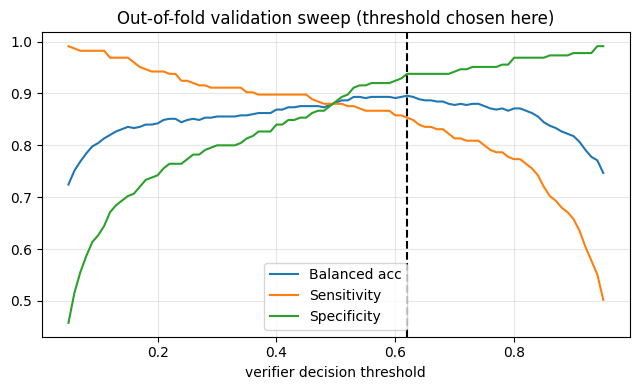

,n,n_normal,n_glaucoma,s1_specificity,old_stage2_specificity,v3_specificity,s1_sensitivity,old_stage2_sensitivity,v3_sensitivity,s1_accuracy,v3_accuracy,v3_accuracy_retained,review_share
bucket,,,,,,,,,,,,,
Small,36,28,8,0.786,0.857,0.929,0.250,0.125,0.250,0.667,0.778,0.769,0.278
Medium,45,30,15,0.900,0.900,0.900,0.600,0.600,0.333,0.800,0.711,0.816,0.156
Large,32,17,15,0.824,0.882,1.000,0.467,0.333,0.133,0.656,0.594,0.682,0.312


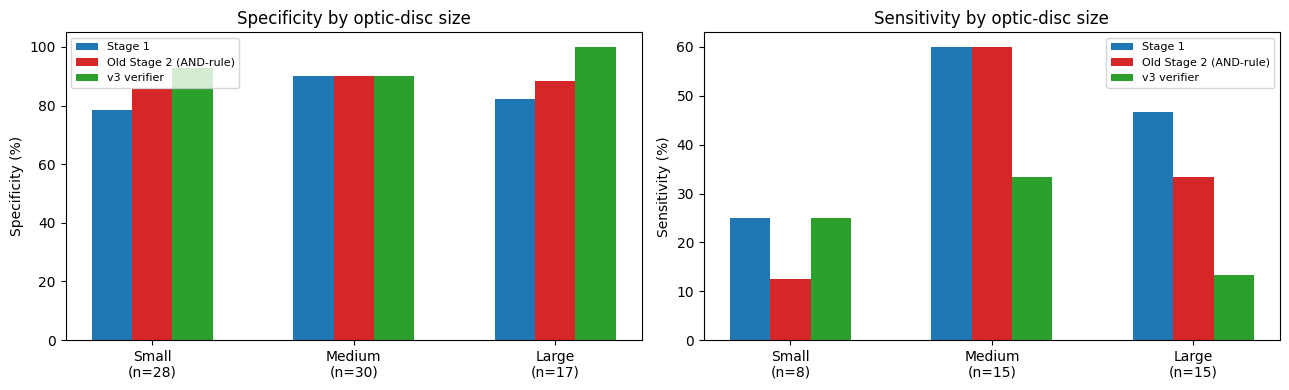

Saved /content/drive/MyDrive/glaucoma-mtl/results/proposed_devgate_20261010_1731/predictions/test_predictions_v3.csv
verifier_status
VERIFIED non-glaucoma    213
VERIFIED glaucoma        174
REVIEW                    63


In [26]:
# ============================================================
# CELL 16 (v3) — Full pipeline: Stage 1 → Stage-2 verification; disc-size subgroup analysis; prediction table
# ============================================================
try: display
except NameError: display = print
TAU = V3_OUT['TAU_OLD']                                                     # kept only for the OLD rule (comparison row)
pipe_te, review_te = V3_OUT['pipe_te'], V3_OUT['review_te']; pipe_old = V3_OUT['pipe_old']; c_te_new, c_te_old = V3_OUT['c_te_v3'], V3_OUT['c_te_old']
s1_te = (p_te >= .5).astype(int)
m_pipe, m_pipe_old = ROWS_V3[FULL], ROWS_V3[OLDN]                                 # metric dicts from CELL S2-4 (same 450 test images)
print(f'Verification module: {int(((pipe_te != s1_te)).sum())} Stage-1 decisions changed (overturned or rescued) | {int(review_te.sum())} cases routed to REVIEW ({review_te.mean()*100:.1f}%)')
print(f'  Stage-1 positives overturned: {int(((s1_te==1)&(pipe_te==0)).sum())} | Stage-1 negatives rescued: {int(((s1_te==0)&(pipe_te==1)).sum())}')

# ---- verifier threshold sweep on out-of-fold validation (figure) ----
fv = VER[FULL]; ths = np.round(np.arange(0.05, 0.951, 0.01), 2); sw = []
for t in ths:
    pr_ = (fv['oof_val'] >= t).astype(int); sw.append((balanced_accuracy_score(y_va_i, pr_), rate(y_va_i, pr_, 1), rate(y_va_i, pr_, 0)))
sw = np.array(sw); plt.figure(figsize=(6.5, 4)); plt.plot(ths, sw[:, 0], label='Balanced acc'); plt.plot(ths, sw[:, 1], label='Sensitivity'); plt.plot(ths, sw[:, 2], label='Specificity')
plt.axvline(fv['thr'], c='k', ls='--'); plt.xlabel('verifier decision threshold'); plt.title('Out-of-fold validation sweep (threshold chosen here)'); plt.legend(); plt.grid(alpha=.3); savefig('v3_pipeline_threshold_sweep_validation.png')

# ---- disc-size subgroup analysis (test images that have a disc mask) ----
sg = []
for k, nm in enumerate(BUCKET_NAMES):
    m = bk_te_ == k
    if m.sum() == 0: continue
    kept = m & ~review_te
    row = dict(bucket=nm, n=int(m.sum()), n_normal=int((y_te_i[m] == 0).sum()), n_glaucoma=int((y_te_i[m] == 1).sum()),
               s1_specificity=rate(y_te_i[m], s1_te[m], 0), old_stage2_specificity=rate(y_te_i[m], pipe_old[m], 0), v3_specificity=rate(y_te_i[m], pipe_te[m], 0),
               s1_sensitivity=rate(y_te_i[m], s1_te[m], 1), old_stage2_sensitivity=rate(y_te_i[m], pipe_old[m], 1), v3_sensitivity=rate(y_te_i[m], pipe_te[m], 1),
               s1_accuracy=float((s1_te[m] == y_te_i[m]).mean()), v3_accuracy=float((pipe_te[m] == y_te_i[m]).mean()),
               v3_accuracy_retained=float((pipe_te[kept] == y_te_i[kept]).mean()) if kept.any() else np.nan, review_share=float(review_te[m].mean()))
    if p_base is not None: row.update(baseline_specificity=rate(y_te_i[m], (p_base[m] >= .5).astype(int), 0), baseline_sensitivity=rate(y_te_i[m], (p_base[m] >= .5).astype(int), 1))
    sg.append(row)
sg_df = pd.DataFrame(sg).set_index('bucket'); display(sg_df.round(3)); sg_df.to_csv(f'{TAB_DIR}/v3_disc_size_subgroup_metrics.csv')
fig, axs = plt.subplots(1, 2, figsize=(13, 4)); w = .2; xs = np.arange(len(sg_df))
for ax, (kind, ttl) in zip(axs, [('specificity', 'Specificity by optic-disc size'), ('sensitivity', 'Sensitivity by optic-disc size')]):
    ax.bar(xs - w, sg_df[f's1_{kind}'] * 100, w, label='Stage 1', color='tab:blue'); ax.bar(xs, sg_df[f'old_stage2_{kind}'] * 100, w, label='Old Stage 2 (AND-rule)', color='tab:red')
    ax.bar(xs + w, sg_df[f'v3_{kind}'] * 100, w, label='v3 verifier', color='tab:green')
    ax.set_xticks(xs); ax.set_xticklabels([f"{b}\n(n={int(r.n_normal if kind=='specificity' else r.n_glaucoma)})" for b, r in sg_df.iterrows()]); ax.set_ylabel(kind.capitalize() + ' (%)'); ax.set_title(ttl); ax.legend(fontsize=8)
savefig('v3_disc_size_subgroup.png')

status = np.where(review_te, 'REVIEW', np.where(pipe_te == 1, 'VERIFIED glaucoma', 'VERIFIED non-glaucoma'))
preds = pd.DataFrame({'row_id': rows_te, 'name': test_df['names'].values, 'true_label': y_te, 'disc_bucket': [BUCKET_NAMES[b] if b >= 0 else 'unknown' for b in bk_te_],
                      'stage1_prob': p_te, 'stage1_pred': s1_te, 'cdr_true': np.where(has_te_, cdr_te_, np.nan), 'cdr_pred_v3': c_te_new, 'cdr_pred_old': c_te_old,
                      'deviation_score': DEV_TE, 'verifier_prob': V3_OUT['p_fused_te'], 'verifier_pred': pipe_te, 'verifier_status': status, 'old_stage2_pred': pipe_old})
if p_base is not None: preds['baseline_prob'] = p_base; preds['baseline_pred'] = (p_base >= .5).astype(int)
preds.to_csv(f'{PRED_DIR}/test_predictions_v3.csv', index=False); print('Saved', f'{PRED_DIR}/test_predictions_v3.csv'); print(preds.verifier_status.value_counts().to_string())

## 7 · Final journal tables, automatic claim check, and file manifest

,accuracy,balanced_accuracy,sensitivity,specificity,precision_glaucoma,precision_normal,f1_macro,f1_weighted,auc,auprc,mcc,kappa,brier,ece,tn,fp,fn,tp
Proposed Stage 1 (MaxViT-Tiny+CBAM+GC),84.2222,84.2222,87.1111,81.3333,82.3529,86.3208,0.8421,0.8421,0.9331,0.9367,0.6856,0.6844,0.1086,0.0573,183.0,42.0,29.0,196.0
"Old Stage 2 (AND-rule, original DGB)",83.5556,83.5556,84.0000,83.1111,83.2599,83.8565,0.8356,0.8356,NaN,NaN,0.6711,0.6711,NaN,NaN,187.0,38.0,36.0,189.0
Proposed full pipeline (Stage 1 + v3 Deviation-gated verification),84.0000,84.0000,78.6667,89.3333,88.0597,80.7229,0.8395,0.8395,0.9300,0.9303,0.6839,0.6800,0.1100,0.0453,201.0,24.0,48.0,177.0
"same, automatically decided cases only (86% coverage)",88.8889,88.8761,83.9378,93.8144,93.1034,85.4460,0.8886,0.8886,NaN,NaN,0.7815,0.7777,NaN,NaN,182.0,12.0,31.0,162.0


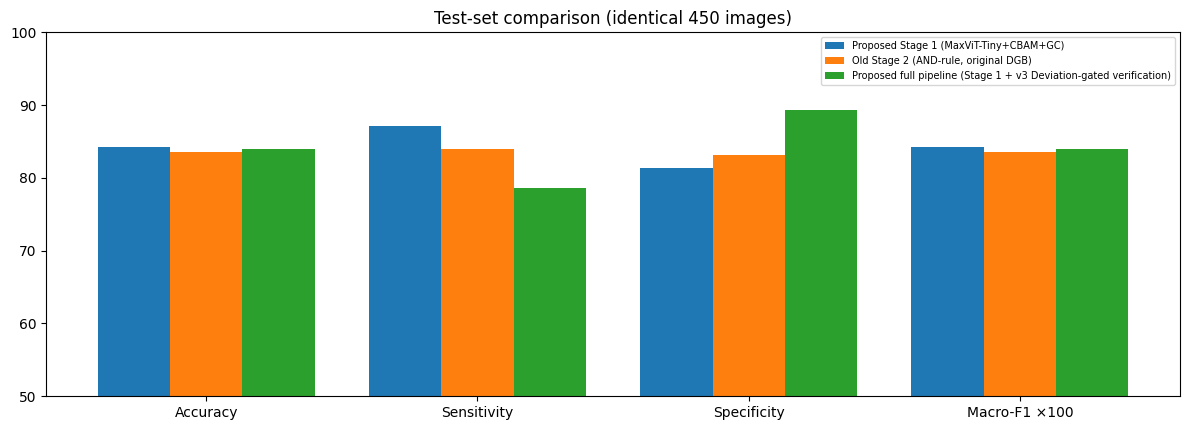


CLAIM CHECK (computed, not hard-coded)

Stage 1 vs reported DenseNet121 baseline:
  ✓ Accuracy           proposed 0.8422 | baseline 0.8044 | Δ +0.0378
  ✓ AUC-ROC            proposed 0.9331 | baseline 0.9195 | Δ +0.0136
  ✓ Macro-F1           proposed 0.8421 | baseline 0.8009 | Δ +0.0412
  ✗ Sensitivity        proposed 0.8711 | baseline 0.9378 | Δ -0.0667
  ✓ Specificity        proposed 0.8133 | baseline 0.6711 | Δ +0.1422
  ✓ Balanced accuracy  proposed 0.8422 | baseline 0.8044 | Δ +0.0378
  -> improves 5 of 6 metrics

Old Stage 2 pipeline vs reported DenseNet121 baseline:
  ✓ Accuracy           proposed 0.8356 | baseline 0.8044 | Δ +0.0312
  ✓ Macro-F1           proposed 0.8356 | baseline 0.8009 | Δ +0.0347
  ✗ Sensitivity        proposed 0.8400 | baseline 0.9378 | Δ -0.0978
  ✓ Specificity        proposed 0.8311 | baseline 0.6711 | Δ +0.1600
  ✓ Balanced accuracy  proposed 0.8356 | baseline 0.8044 | Δ +0.0311
  -> improves 4 of 5 metrics

NEW full pipeline (v3) vs reported DenseNet

In [27]:
# ============================================================
# CELL 17 (v3) — Final comparison table (all numbers computed from predictions), claim check, manifest
# ============================================================
final_rows = {}
if BASELINE_OK: final_rows['Baseline DenseNet121'] = m_base
final_rows['Proposed Stage 1 (MaxViT-Tiny+CBAM+GC)'] = m_te
final_rows['Old Stage 2 (AND-rule, original DGB)'] = m_pipe_old
final_rows['Proposed full pipeline (Stage 1 + v3 Deviation-gated verification)'] = m_pipe
kept_ = ~review_te; m_kept = clf_metrics(y_te_i[kept_], None, pred=pipe_te[kept_])
final_rows[f'  same, automatically decided cases only ({kept_.mean()*100:.0f}% coverage)'] = m_kept
final_tab = metrics_table(final_rows)
keep = ['accuracy', 'balanced_accuracy', 'sensitivity', 'specificity', 'precision_glaucoma', 'precision_normal', 'f1_macro', 'f1_weighted', 'auc', 'auprc', 'mcc', 'kappa', 'brier', 'ece', 'tn', 'fp', 'fn', 'tp']
final_tab = final_tab[keep].round(4); display(final_tab); final_tab.to_csv(f'{TAB_DIR}/FINAL_main_comparison_v3.csv')
try:
    open(f'{TAB_DIR}/FINAL_main_comparison_v3.tex', 'w').write(final_tab.to_latex(float_format='%.2f', na_rep='--'))
    open(f'{TAB_DIR}/v3_cdr_regression.tex', 'w').write(cdr3.drop(columns=['note']).to_latex(float_format='%.4f'))
except Exception as e: print('LaTeX export skipped:', e)

fig, ax = plt.subplots(figsize=(12, 4.4)); names = ['accuracy', 'sensitivity', 'specificity', 'f1_macro']; xs = np.arange(len(names)); plot_rows = {k: v for k, v in final_rows.items() if not k.startswith('  ')}
n_m = len(plot_rows); w = .8 / n_m
for i, (nm, mm) in enumerate(plot_rows.items()): ax.bar(xs + (i - (n_m - 1) / 2) * w, [mm[k] * 100 for k in names], w, label=nm)
ax.set_xticks(xs); ax.set_xticklabels(['Accuracy', 'Sensitivity', 'Specificity', 'Macro-F1 ×100']); ax.set_ylim(50, 100); ax.legend(fontsize=7); ax.set_title('Test-set comparison (identical 450 images)')
savefig('FINAL_metric_comparison_v3.png')

print('\n' + '=' * 78 + '\nCLAIM CHECK (computed, not hard-coded)\n' + '=' * 78)
ref = m_base if BASELINE_OK else dict(accuracy=BASE_FALLBACK['accuracy'], auc=BASE_FALLBACK['auc'], f1_macro=BASE_FALLBACK['f1_macro'], sensitivity=BASE_FALLBACK['sensitivity'],
                                      specificity=BASE_FALLBACK['specificity'], balanced_accuracy=(BASE_FALLBACK['sensitivity'] + BASE_FALLBACK['specificity']) / 2, mcc=np.nan)
claims = [('Accuracy', 'accuracy'), ('AUC-ROC', 'auc'), ('Macro-F1', 'f1_macro'), ('Sensitivity', 'sensitivity'), ('Specificity', 'specificity'), ('Balanced accuracy', 'balanced_accuracy'), ('MCC', 'mcc')]
for tag, mm in [('Stage 1', m_te), ('Old Stage 2 pipeline', m_pipe_old), ('NEW full pipeline (v3)', m_pipe)]:
    better = []; print(f'\n{tag} vs {"re-scored" if BASELINE_OK else "reported"} DenseNet121 baseline:')
    for nm, k in claims:
        if np.isnan(mm[k]) or np.isnan(ref.get(k, np.nan)): continue
        ok = mm[k] > ref[k]; better.append(ok); print(f"  {'✓' if ok else '✗'} {nm:<18} proposed {mm[k]:.4f} | baseline {ref[k]:.4f} | Δ {mm[k]-ref[k]:+.4f}")
    print(f'  -> improves {sum(better)} of {len(better)} metrics')
print('\nStage 2 improvement over the OLD Stage 2 (same images):')
for k, nm in [('accuracy', 'Accuracy'), ('sensitivity', 'Sensitivity'), ('specificity', 'Specificity'), ('f1_macro', 'Macro-F1'), ('mcc', 'MCC')]:
    print(f"  {'✓' if m_pipe[k] > m_pipe_old[k] else '✗'} {nm:<12} old {m_pipe_old[k]:.4f} -> v3 {m_pipe[k]:.4f}  (Δ {m_pipe[k]-m_pipe_old[k]:+.4f})")
print('\n(See the SCORECARD printed by CELL S2-4 for confidence intervals and for what is / is not statistically supported.)')
g = gap.loc['Train − Val gap', 'Accuracy (%)']; print(f"\nStage-1 overfitting check (clean train − val accuracy): {g:+.2f} pts; (val − test): {gap.loc['Val − Test gap', 'Accuracy (%)']:+.2f} pts")

json.dump({'run': RUN_NAME, 'stage2_version': 'v3', 'old_tau': TAU, 'val_youden_threshold': THR_YOUDEN, 'disc_cutoffs': [float(Q1), float(Q2)], 'stage1_test': {k: float(v) for k, v in m_te.items()},
           'old_stage2_test': {k: (None if (isinstance(v, float) and np.isnan(v)) else float(v)) for k, v in m_pipe_old.items()},
           'v3_pipeline_test': {k: (None if (isinstance(v, float) and np.isnan(v)) else float(v)) for k, v in m_pipe.items()},
           'v3_review_fraction_test': float(review_te.mean()), 'baseline_rescored': bool(BASELINE_OK)}, open(f'{RESULTS_DIR}/results_summary_v3.json', 'w'), indent=2)
print('\nSaved files in', RESULTS_DIR)
for r_, _, fs in os.walk(RESULTS_DIR):
    if 'checkpoints' in r_: continue
    for f in sorted(fs): print('  ', os.path.relpath(os.path.join(r_, f), RESULTS_DIR))